# 01 · Dataset analysis and research design

**Question.** Can measured household aggregate active power in a completed minute be reconstructed from past measurements and currently available appliance telemetry, while respecting time and household boundaries?

This notebook uses the original dataset releases. It first examines metadata and timestamps, fixes protected splits, and then examines development measurements. No models are fitted. Plegma houses 11–13 and temporal holdouts remain protected. REFIT measurements are reserved for the frozen external evaluation.

**Reading guide.** Source and sensor semantics → timestamp audit → fixed split design → development quality, coverage and physical consistency → research adequacy and limitations.

In [1]:
from pathlib import Path
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "Notebooks":
    ROOT = ROOT.parent
assert ROOT.is_dir()
RAW = ROOT / "Data/Interim/Plegma_extracted/Raw_Dataset"
RUN = "guldana_n3_20261007_v01"
TABLES = ROOT / "Tables" / RUN / "01_dataset_audit"
FIGURES = ROOT / "Figures" / RUN / "01_dataset_audit"
for directory in [TABLES, FIGURES, ROOT / "Data/Interim/timestamp_index"]:
    directory.mkdir(parents=True, exist_ok=True)
font_path = font_manager.findfont("Times New Roman", fallback_to_default=False)
assert Path(font_path).is_file()
mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
                     "axes.titlesize": 20, "axes.labelsize": 18,
                     "xtick.labelsize": 18, "ytick.labelsize": 18,
                     "legend.fontsize": 18, "figure.dpi": 350,
                     "savefig.dpi": 350, "axes.unicode_minus": True,
                     "pdf.fonttype": 42, "ps.fonttype": 42})
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

def table(frame, name, caption, precision=4):
    frame.to_csv(TABLES / (name + ".csv"), index=False)
    frame.to_latex(TABLES / (name + ".tex"), index=False,
                   caption=caption, float_format=lambda x: f"{x:.{precision}f}")
    display(frame.style.format(precision=precision, na_rep="Unavailable").hide(axis="index").set_caption(caption))

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=350, bbox_inches="tight")
    fig.savefig(FIGURES / (name + ".pdf"), dpi=350, bbox_inches="tight")
    plt.show()


In [3]:
# Complete scientific tables: semantic groups, unchanged values, mathematical minus.
# This display-only setup does not fit models or modify numerical exports.
import copy as _table_copy
import re as _table_re
import pandas as _table_pd
from bs4 import BeautifulSoup as _TableSoup, NavigableString as _TableText
from pandas.io.formats.style import Styler as _TableStyler
from IPython.display import HTML as _TableHTML
import hashlib as _table_hashlib, json as _table_json
_table_layout_bytes = (ROOT / "Configs/article_table_layout.json").read_bytes()
assert _table_hashlib.sha256(_table_layout_bytes).hexdigest() == "fbbb6522e8c59dbde1eea0021da0a6f72e3257d1c6d0c8d49e74c5bd3a6a9d8c"
_ARTICLE_TABLE_GROUPS = _table_json.loads(_table_layout_bytes)
_ARTICLE_NUMBER = _table_re.compile(r"^\s*[+−-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+−-]?\d+)?%?\s*$")
def _article_table_layout(tag, additions):
    declarations = dict(part.strip().split(":", 1) for part in tag.get("style", "").split(";") if ":" in part)
    declarations.update(additions)
    tag["style"] = ";".join(key + ":" + value for key, value in declarations.items()) + ";"
def _article_table_html(html):
    soup = _TableSoup(html, "html.parser")
    for table in list(soup.find_all("table")):
        head = table.find("thead")
        body = table.find("tbody")
        if head is None or body is None:
            continue
        heads = [tag.get_text(strip=True) for tag in head.find_all("th")]
        rule = _ARTICLE_TABLE_GROUPS.get("|".join(heads))
        if rule is not None and len(head.find_all("tr")) == 1:
            rows = body.find_all("tr", recursive=False)
            if all(len(row.find_all(["th", "td"], recursive=False)) == len(heads) for row in rows):
                assert set(sum(rule["columns"], [])) == set(heads)
                original_styles = [style.get_text() for style in soup.find_all("style")]
                for number, (columns, label) in enumerate(zip(rule["columns"], rule["labels"]), 1):
                    part = _table_copy.deepcopy(table)
                    keep = [heads.index(name) for name in columns]
                    for row in part.find_all("tr"):
                        for index, tag in enumerate(row.find_all(["th", "td"], recursive=False)):
                            if index not in keep:
                                tag.decompose()
                    caption = part.find("caption")
                    if caption is None:
                        caption = soup.new_tag("caption")
                        part.insert(0, caption)
                    caption.append(" " + label)
                    suffix = "_article_part_" + str(number)
                    original_id = table.get("id")
                    for tag in [part] + part.find_all(True):
                        if tag.has_attr("id"):
                            tag["id"] = (tag["id"].replace(original_id, original_id + suffix, 1)
                                         if original_id and tag["id"].startswith(original_id) else tag["id"] + suffix)
                    if original_id:
                        for style_text in original_styles:
                            if "#" + original_id in style_text:
                                copied_style = soup.new_tag("style")
                                copied_style.string = style_text.replace("#" + original_id, "#" + original_id + suffix)
                                table.insert_before(copied_style)
                    table.insert_before(part)
                table.decompose()
    for table in soup.find_all("table"):
        _article_table_layout(table, {"max-width":"100%", "table-layout":"auto", "margin-bottom":"1.4em"})
        for tag in table.find_all(["th", "td", "caption"]):
            _article_table_layout(tag, {"white-space":"normal", "vertical-align":"top"})
            if tag.name == "caption":
                _article_table_layout(tag, {"text-align":"left", "caption-side":"top"})
            for old_break in list(tag.find_all("wbr")):
                old_break.decompose()
            for node in list(tag.descendants):
                if not isinstance(node, _TableText) or node.parent.name in {"code", "pre", "script", "style"}:
                    continue
                text = str(node)
                if tag.name == "td" and _ARTICLE_NUMBER.fullmatch(text):
                    text = text.replace("-", "−")
                chunks = _table_re.split("(?<=_)", text)
                for index, chunk in enumerate(chunks):
                    node.insert_before(_TableText(chunk))
                    if index + 1 < len(chunks):
                        node.insert_before(soup.new_tag("wbr"))
                node.extract()
    return str(_TableSoup(str(soup), "html.parser"))
def _article_styler_html(value):
    with _table_pd.option_context("styler.render.max_elements", max(1, value.data.size + len(value.data)),
                                  "styler.render.max_rows", None, "styler.render.max_columns", None):
        html = value.to_html(max_rows=len(value.data), max_columns=len(value.data.columns))
    assert not _TableSoup(html, "html.parser").select(".row_trim, .col_trim"), "Scientific table was truncated"
    return _article_table_html(html)
def _article_frame_html(value):
    return _article_table_html(value.to_html(max_rows=None, max_cols=None))
def _article_HTML_html(value):
    result = value._repr_html_()
    if isinstance(result, tuple):
        return _article_table_html(result[0]), result[1]
    return _article_table_html(result)
_table_format = get_ipython().display_formatter.formatters["text/html"]
_table_format.for_type(_TableStyler, _article_styler_html)
_table_format.for_type(_table_pd.DataFrame, _article_frame_html)
_table_format.for_type(_TableHTML, _article_HTML_html);


## 1. Source evidence and acquisition semantics

The Plegma source reports active power in W. REFIT labels its readings in W, but its CurrentCost instrument uses fixed voltage and provides no per-reading freshness flag, so physical and observation equivalence remain unresolved. The proposed common representation will use kW. Plegma's raw release has separate asynchronous sensor streams. Its clean release applies filling and thresholds and is not used here. REFIT's raw README reports collection-time intermediate filling, ambiguous unavailable zeros in Part1, explicit missingness in Part2, and nonsynchronous polling. Therefore a non-null REFIT row cannot automatically be classified as a fresh measured target. This unresolved issue limits the use of REFIT as a strictly measured external endpoint.

Sources: [Plegma official record](https://doi.org/10.15129/3b01a6c6-2efd-424a-b8b8-5fe7fa445ded), [REFIT official record](https://doi.org/10.15129/31da3ece-f902-4e95-a093-e0a9536983c4), and their original READMEs.

In [2]:
manifest = pd.read_csv(ROOT / "Manifests/dataset_manifest.csv")
assert set(manifest.dataset) == {"Plegma", "REFIT"}
assert len(manifest) == 5
source_table = pd.DataFrame([
    {"Dataset": "Plegma", "Role": "Primary", "Houses (metadata)": 13,
     "Power cadence (s)": 10, "License": "CC BY 4.0",
     "Archive bytes": int(manifest.loc[manifest.filename.eq("PlegmaDataset_Raw.7z"), "bytes"].iloc[0])},
    {"Dataset": "REFIT", "Role": "External, protected", "Houses (metadata)": 20,
     "Power cadence (s)": 8, "License": "CC BY 4.0",
     "Archive bytes": int(manifest.loc[manifest.filename.eq("REFIT_RAW_081116.7z"), "bytes"].iloc[0])}
])
table(source_table, "source_overview", "Table 1. Original releases and metadata-defined sampling. Counts are not yet eligible target counts.")


Dataset,Role,Houses (metadata),Power cadence (s),License,Archive bytes
Plegma,Primary,13,10,CC BY 4.0,783216452
REFIT,"External, protected",20,8,CC BY 4.0,698108465


## 2. Deterministic sensor semantics

Sensor types are mapped from original names and household metadata, never from correlations with the hidden aggregate. Appliance indices distinguish physical channels within a household; they are not model position embeddings. Current aggregate-meter voltage and current are excluded because they could reveal the hidden aggregate. Environmental channels retain their distinct units and slower sampling rate. Household identity is used for grouping and audit only.

In [3]:
semantic_rows = []
name_rules = {"ac": "HVAC/air_conditioner", "boiler": "water_heater",
              "fridge": "refrigerator/freezer", "washing_machine": "washing_machine",
              "dishwasher": "dishwasher", "kettle": "kettle",
              "P_agg": "aggregate", "V": "aggregate_meter_voltage",
              "A": "aggregate_meter_current", "temperature (C)": "indoor_temperature",
              "humidity (%)": "indoor_humidity"}
for house_dir in sorted(RAW.glob("House_*")):
    house = int(house_dir.name.split("_")[-1])
    meta = next(house_dir.glob("Metadata_raw*"))
    descriptions = {}
    for line in meta.read_text(encoding="utf-8-sig").splitlines():
        if ":" in line:
            description, sensor = line.rsplit(":", 1)
            descriptions[sensor.strip()] = description.strip()
    sensors = set()
    for path in sorted(house_dir.glob("Raw_collected_data/*/*.csv")):
        sensors.update(c for c in pd.read_csv(path, nrows=0).columns if c != "timestamp")
    for sensor in sorted(sensors):
        base = re.sub(r"_\d+$", "", sensor)
        canonical = name_rules.get(base, "unknown")
        unit = {"V": "V", "A": "A", "temperature (C)": "degC", "humidity (%)": "%"}.get(sensor, "W")
        role = "aggregate" if sensor == "P_agg" else ("excluded_proxy" if sensor in {"V", "A"} else ("environment" if unit in {"degC", "%"} else "auxiliary_power"))
        semantic_rows.append({"dataset": "Plegma", "house": house, "original_sensor": sensor,
                              "original_description": descriptions.get(sensor, sensor),
                              "canonical_type": canonical, "unit": unit, "role": role,
                              "evidence": str(meta.relative_to(ROOT)),
                              "confidence_rule": "exact metadata/name rule" if canonical != "unknown" else "unresolved"})
semantic_map = pd.DataFrame(semantic_rows)
assert not semantic_map.canonical_type.eq("unknown").any()
semantic_map.to_csv(ROOT / "Data/Interim/sensor_semantic_map.csv", index=False)
vocabulary = semantic_map.groupby(["canonical_type", "unit", "role"], as_index=False).agg(Channels=("original_sensor", "size"), Houses=("house", "nunique"))
table(vocabulary, "sensor_vocabulary", "Table 2. Metadata-derived Plegma sensor vocabulary; all 13 houses, without inspecting measurements.")
composition = semantic_map.assign(aux=lambda x: x.role.eq("auxiliary_power").astype(int)).groupby("house", as_index=False).agg(Appliances=("aux", "sum"), Channels=("original_sensor", "size"))
table(composition, "sensor_composition", "Table 3. Installed channels by house. Channel counts describe composition, not availability.")


canonical_type,unit,role,Channels,Houses
HVAC/air_conditioner,W,auxiliary_power,18,11
aggregate,W,aggregate,13,13
aggregate_meter_current,A,excluded_proxy,9,9
aggregate_meter_voltage,V,excluded_proxy,9,9
dishwasher,W,auxiliary_power,4,4
indoor_humidity,%,environment,13,13
indoor_temperature,degC,environment,13,13
kettle,W,auxiliary_power,1,1
refrigerator/freezer,W,auxiliary_power,14,13
washing_machine,W,auxiliary_power,13,13


house,Appliances,Channels
1,5,10
2,5,10
3,5,10
4,5,10
5,5,10
6,3,6
7,5,10
8,4,7
9,3,8
10,6,11


**Interpretation.** The archive contains 3–6 monitored appliances per house, with 13 aggregate channels and 26 environmental channels. Refrigerator/freezer and washing-machine categories occur in every house; kettle appears in only one. Sensor sets therefore differ structurally even before missingness is considered. Nine houses also expose aggregate-meter voltage/current, which are excluded as current-time proxies.

## 3. Target-blind timestamp and acquisition audit

Only aggregate timestamps are read in this section. Parsing preserves the release's local-naive time representation: no unverified UTC offset is invented. Duplicate timestamps and backward jumps are audited before deciding how to aggregate. Minute IDs identify calendar intervals even when a target will later fail quality criteria. Power distributions and measurement-derived exclusions do not determine split boundaries.

In [4]:
timestamp_audit = []
for house_dir in sorted(RAW.glob("House_*")):
    house = int(house_dir.name.split("_")[-1])
    stamp_chunks = []
    invalid = 0
    for path in sorted(house_dir.glob("Raw_collected_data/*/total_consumption.csv")):
        stamp = pd.to_datetime(pd.read_csv(path, usecols=["timestamp"])["timestamp"], format="ISO8601", errors="coerce")
        invalid += int(stamp.isna().sum())
        stamp_chunks.append(stamp.dropna())
    stamps = pd.concat(stamp_chunks, ignore_index=True)
    sequence_differences = stamps.diff().dt.total_seconds()
    unique = pd.DatetimeIndex(stamps.drop_duplicates().sort_values())
    differences = np.diff(unique.asi8) / 1e9
    minute_counts = pd.Series(1, index=unique).resample("1min").sum().astype("int32")
    minute_index = pd.DataFrame({"timestamp": minute_counts.index, "raw_timestamp_count": minute_counts.values})
    minute_index.to_parquet(ROOT / "Data/Interim/timestamp_index" / f"plegma_house_{house:02d}.parquet", index=False)
    timestamp_audit.append({"House": house, "First timestamp": unique.min(), "Last timestamp": unique.max(),
                            "Raw rows": len(stamps), "Duplicate timestamps": int(stamps.duplicated().sum()),
                            "Unparseable": invalid, "Backward steps": int(sequence_differences.lt(0).sum()),
                            "Median cadence (s)": np.median(differences), "Gaps > 30 s": int((differences > 30).sum()),
                            "Calendar minutes": len(minute_counts), "Minutes with records": int(minute_counts.gt(0).sum())})
timestamp_audit = pd.DataFrame(timestamp_audit)
table(timestamp_audit.iloc[:, :7], "timestamp_integrity", "Table 4. Target-blind aggregate timestamp integrity across houses.")
table(timestamp_audit[["House", "Median cadence (s)", "Gaps > 30 s", "Calendar minutes", "Minutes with records"]],
      "timestamp_coverage", "Table 5. Timestamp-only cadence and coverage; positive values do not yet guarantee valid measured targets.")


House,First timestamp,Last timestamp,Raw rows,Duplicate timestamps,Unparseable,Backward steps
1,2022-07-15 00:00:02.091000,2023-09-30 23:59:51.229000,11431550,0,0,0
2,2022-09-17 00:00:03.864000,2023-04-11 10:26:00.901000,5043838,0,0,0
3,2022-07-11 10:36:55.528000,2023-09-30 23:59:53.231000,11511909,0,0,0
4,2022-10-10 14:03:00.905000,2023-09-30 23:59:56.813000,9153006,0,0,0
5,2023-01-01 00:00:04.273000,2023-09-30 23:59:52.883000,6709962,0,0,0
6,2023-03-01 00:00:01.417000,2023-09-30 23:59:56.550000,2369097,0,0,407366
7,2022-11-01 00:00:01.561000,2023-09-30 23:59:55.001000,8456627,0,0,0
8,2023-03-01 00:00:06.170000,2023-09-30 23:59:55.162000,3522420,0,0,0
9,2023-02-01 00:00:01.815000,2023-09-30 23:59:51.797000,6197847,0,0,810078
10,2023-04-21 07:58:33.265000,2023-09-30 23:59:55.282000,3788675,0,0,0


House,Median cadence (s),Gaps > 30 s,Calendar minutes,Minutes with records
1,0.1940,138,637920,634629
2,0.1900,23,297267,279839
3,0.1000,84,643044,634255
4,0.1880,38,511797,506965
5,0.1840,472,393120,380032
6,8.6080,59,308160,273464
7,0.1600,328,480960,480413
8,4.0390,86,308160,306803
9,0.1880,93,348480,347617
10,0.1490,100,234242,216856


**Interpretation.** All aggregate timestamps parse, and no exact duplicate aggregate timestamps were found. Houses 6, 9 and 11 contain backward steps in file order; sorting timestamps is necessary before temporal aggregation. The subsecond median row spacing in several houses is inconsistent with the nominal 10-second sensor cadence. Because rows may contain asynchronous channel updates, this is a row-arrival statistic, not proof of subsecond power measurements; per-channel non-null cadence must be audited on development data.

House 2's record ends before House 10's record begins. A common calendar interval cannot give both houses nonempty training and final periods. The prespecified fallback is deterministic per-house calendar splitting. Its limitation is that held-out periods differ by house; it estimates within-house forward transfer rather than deployment after one common worldwide cutoff.

## 4. Fixed calendar splits and nested expanding folds

The first 70% of each house's calendar minutes form development, the next 10% calibration, and the final 20% temporal holdout. Houses 11–13 remain group-locked throughout. Each new split begins with a 360-minute context purge; those rows are context-only, never fitting or evaluation targets. The development outer folds expand at 40%, 60% and 80%, validating on the next 20%; their trailing 15% training interval is inner validation, separated by an additional 360-minute gap. Every candidate must use the same rows. No target value enters this construction.

In [5]:
PURGE = pd.Timedelta(minutes=360)
split_rows = []
fold_rows = []
observation_counts = []
ID_DIR = ROOT / "Manifests/observation_ids"
ID_DIR.mkdir(parents=True, exist_ok=True)
for record in timestamp_audit.to_dict("records"):
    house = record["House"]
    idx = pd.read_parquet(ROOT / "Data/Interim/timestamp_index" / f"plegma_house_{house:02d}.parquet")
    start = idx.timestamp.min()
    stop = idx.timestamp.max() + pd.Timedelta(minutes=1)
    length = len(idx)
    cut1 = start + pd.Timedelta(minutes=int(np.floor(0.70 * length)))
    cut2 = start + pd.Timedelta(minutes=int(np.floor(0.80 * length)))
    idx["dataset"] = "Plegma"
    idx["house"] = house
    idx["observation_id"] = f"Plegma:H{house:02d}:" + idx.timestamp.dt.strftime("%Y%m%dT%H%M")
    idx["split"] = "group_locked" if house >= 11 else np.select([idx.timestamp.lt(cut1), idx.timestamp.lt(cut2)], ["development", "calibration"], default="temporal_locked")
    idx["context_only"] = idx.timestamp.lt(start + PURGE)
    if house <= 10:
        idx["context_only"] |= (idx.timestamp.ge(cut1) & idx.timestamp.lt(cut1 + PURGE)) | (idx.timestamp.ge(cut2) & idx.timestamp.lt(cut2 + PURGE))
        for fold, fraction in enumerate([0.40, 0.60, 0.80], 1):
            outer_start = start + pd.Timedelta(minutes=int((cut1 - start).total_seconds() / 60 * fraction))
            outer_stop = start + pd.Timedelta(minutes=int((cut1 - start).total_seconds() / 60 * (fraction + 0.20)))
            inner_start = start + pd.Timedelta(minutes=int((outer_start - start).total_seconds() / 60 * 0.85))
            train_stop = inner_start - PURGE
            inner_stop = outer_start - PURGE
            assert start + PURGE < train_stop < inner_start < inner_stop < outer_start < outer_stop <= cut1
            idx[f"fold_{fold}"] = np.select([
                idx.timestamp.ge(start + PURGE) & idx.timestamp.lt(train_stop),
                idx.timestamp.ge(inner_start) & idx.timestamp.lt(inner_stop),
                idx.timestamp.ge(outer_start) & idx.timestamp.lt(outer_stop)],
                ["train", "inner_validation", "outer_validation"], default="unused")
            fold_rows.append({"dataset": "Plegma", "house": house, "fold": fold,
                              "train_start": start + PURGE, "train_stop": train_stop,
                              "inner_start": inner_start, "inner_stop": inner_stop,
                              "outer_start": outer_start, "outer_stop": outer_stop})
    else:
        for fold in [1, 2, 3]: idx[f"fold_{fold}"] = "unused"
    for role, part in idx.groupby("split", sort=False):
        split_rows.append({"dataset": "Plegma", "house": house, "split": role,
                           "start_inclusive": part.timestamp.min(),
                           "stop_exclusive": part.timestamp.max() + pd.Timedelta(minutes=1),
                           "calendar_minutes": len(part), "context_only_minutes": int(part.context_only.sum())})
        observation_counts.append({"House": house, "Split": role, "Calendar minutes": len(part),
                                   "Timestamp-present target candidates": int((part.raw_timestamp_count.gt(0) & ~part.context_only).sum())})
    assert idx.observation_id.is_unique
    idx.to_parquet(ID_DIR / f"plegma_house_{house:02d}.parquet", index=False)
split_manifest = pd.DataFrame(split_rows)
fold_manifest = pd.DataFrame(fold_rows)
for frame, name in [(split_manifest, "split_manifest.csv"), (fold_manifest, "fold_manifest.csv")]:
    target = ROOT / "Manifests" / name
    content = frame.to_csv(index=False)
    if target.exists():
        assert target.read_text() == content, "An immutable split would change"
    else:
        target.write_text(content)
freeze = {"protocol": "target-blind per-house calendar 70/10/20", "purge_minutes": 360,
          "target_values_accessed": False,
          "files": {str(f.relative_to(ROOT)): hashlib.sha256(f.read_bytes()).hexdigest()
                    for f in [ROOT / "Manifests/split_manifest.csv", ROOT / "Manifests/fold_manifest.csv", *sorted(ID_DIR.glob("*.parquet"))]}}
freeze_path = ROOT / "Manifests/split_freeze.json"
if freeze_path.exists():
    assert json.loads(freeze_path.read_text()) == freeze
else:
    freeze_path.write_text(json.dumps(freeze, indent=2) + "\n")
summary = pd.DataFrame(observation_counts).pivot(index="House", columns="Split", values="Timestamp-present target candidates").fillna(0).astype(int).reset_index()
table(summary, "split_timestamp_candidates", "Table 6. Target-blind candidate minutes after context exclusions. Measurement quality is not yet applied.", precision=0)
table(fold_manifest.loc[fold_manifest.house.eq(1), ["fold", "train_start", "train_stop", "inner_start", "inner_stop", "outer_start", "outer_stop"]],
      "fold_example_house_01", "Table 7. House 1 nested chronological folds. Intervals are left-closed and right-open.")


House,calibration,development,group_locked,temporal_locked
1,63430,442899,0,127220
2,29287,207415,0,42057
3,63940,441379,0,127985
4,50800,353883,0,101560
5,33666,271478,0,74168
6,30396,180719,0,61269
7,47632,335875,0,95826
8,30449,215016,0,60258
9,34426,242782,0,69329
10,23064,146298,0,46487


fold,train_start,train_stop,inner_start,inner_stop,outer_start,outer_stop
1,2022-07-15 06:00:00,2022-10-28 04:24:00,2022-10-28 10:24:00,2022-11-15 18:57:00,2022-11-16 00:57:00,2023-01-17 01:26:00
2,2022-07-15 06:00:00,2022-12-19 21:37:00,2022-12-20 03:37:00,2023-01-16 19:26:00,2023-01-17 01:26:00,2023-03-20 01:55:00
3,2022-07-15 06:00:00,2023-02-10 14:49:00,2023-02-10 20:49:00,2023-03-19 19:55:00,2023-03-20 01:55:00,2023-05-21 02:24:00


**Interpretation.** All 10 development houses have timestamp-present candidates in development, calibration and temporal holdout. Houses 11–13 have only group-locked candidates. House 2's short record is retained without shifting its split to improve performance. Candidate counts are an upper bound: a minute needs sufficient valid aggregate measurements before it becomes an evaluation target.

## 5. Development-only channel quality and minute construction

The raw-row arrival cadence is not used as electrical sampling cadence. Each power channel is audited after removing missing channel values and sorting its own timestamps. Identical timestamp duplicates are retained once; conflicting duplicates are invalid. Finite nonnegative raw power is retained without upper clipping. Negative active-consumption values are flagged invalid (the release does not identify a net-export target); their frequency is reported. Zero remains a measured zero.

A provisional minute target requires at least five distinct observed 10-second bins, at least five finite nonnegative readings, and no within-minute observation gap exceeding 20 seconds, including edges. These fixed metadata-based rules prevent message bursts from inflating coverage. The mean uses only valid recorded samples; no target filling is performed. The 10-second-bin count is a coverage diagnostic, not proof of fresh sampling. Environmental values are summarized only where actually recorded; any later carry-forward must be explicitly causal and retain age.

The code opens development rows selected by timestamps before parsing measurement columns; calibration and locked measurements remain unexamined. The field `power_eligible` describes record-based quality and does not resolve undocumented upstream transformations.

In [6]:
CHANNEL_DIR = ROOT / "Data/Interim/development_minutes"
CHANNEL_DIR.mkdir(parents=True, exist_ok=True)
quality_rows = []
minute_quality_rows = []
def audit_house(house):
    house_dir = RAW / f"House_{house:02d}"
    split = split_manifest.query("house == @house and split == 'development'").iloc[0]
    begin, end = split.start_inclusive, split.stop_exclusive
    file_groups = {}
    for path in sorted(house_dir.glob("Raw_collected_data/*/*.csv")):
        columns = list(pd.read_csv(path, nrows=0).columns)
        for sensor in columns:
            if sensor not in {"timestamp", "V", "A"}:
                file_groups.setdefault(sensor, []).append(path)
    all_minutes = []
    for sensor, paths in sorted(file_groups.items()):
        chunks = []
        raw_rows = 0
        for path in paths:
            ts = pd.to_datetime(pd.read_csv(path, usecols=["timestamp"])["timestamp"], format="ISO8601", errors="coerce")
            keep = ts.ge(begin) & ts.lt(end)
            if not keep.any():
                continue
            allowed = keep.to_numpy()
            frame = pd.read_csv(path, usecols=["timestamp", sensor], skiprows=None if keep.all() else lambda i: i > 0 and not allowed[i - 1])
            frame["timestamp"] = pd.to_datetime(frame.timestamp, format="ISO8601")
            assert frame.timestamp.ge(begin).all() and frame.timestamp.lt(end).all()
            chunks.append(frame)
            raw_rows += len(frame)
        if not chunks:
            continue
        observations = pd.concat(chunks, ignore_index=True).sort_values("timestamp", kind="stable")
        numeric = pd.to_numeric(observations[sensor], errors="coerce")
        nonnumeric = int((observations[sensor].notna() & numeric.isna()).sum())
        missing = int(numeric.isna().sum())
        nonfinite = int((numeric.notna() & ~np.isfinite(numeric)).sum())
        power = sensor not in {"temperature (C)", "humidity (%)"}
        negative = int((numeric.lt(0) & np.isfinite(numeric)).sum()) if power else 0
        valid = numeric.notna() & np.isfinite(numeric)
        if power: valid &= numeric.ge(0)
        else: valid &= numeric.between(-50, 70) if sensor == "temperature (C)" else numeric.between(0, 100)
        stream = pd.DataFrame({"timestamp": observations.loc[valid, "timestamp"], "value": numeric[valid]})
        duplicate_rows = int(stream.timestamp.duplicated().sum())
        conflicting = stream.groupby("timestamp", sort=False).value.nunique().gt(1)
        conflict_times = conflicting.index[conflicting]
        stream = stream.loc[~stream.timestamp.isin(conflict_times)].drop_duplicates("timestamp")
        stream = stream.set_index("timestamp").sort_index()
        times = stream.index.asi8
        gaps = np.diff(times) / 1e9
        if power: stream["value"] /= 1000.0
        full_index = pd.date_range(begin, end, freq="1min", inclusive="left")
        group = stream.value.resample("1min")
        minute = group.agg(["mean", "count", "min", "max"]).reindex(full_index)
        minute["count"] = minute["count"].fillna(0).astype("int32")
        observed_bins = pd.Series(1, index=stream.index.floor("10s")).groupby(level=0).size().resample("1min").size()
        minute["observed_10s_bins"] = observed_bins.reindex(full_index, fill_value=0).astype("int16")
        minute["coverage_fraction"] = minute.observed_10s_bins / 6 if power else np.minimum(1, minute["count"])
        minute_floor = stream.index.floor("min")
        offsets = (stream.index.asi8 - minute_floor.asi8) / 1e9
        within_gap = np.r_[0., gaps]
        same_minute = np.r_[False, minute_floor[1:] == minute_floor[:-1]]
        within_gap[~same_minute] = 0.
        edges = pd.DataFrame({"timestamp": minute_floor, "offset": offsets, "within_gap": within_gap}).groupby("timestamp").agg(first=("offset", "min"), last=("offset", "max"), gap=("within_gap", "max"))
        edges["max_gap_seconds"] = np.maximum.reduce([edges["first"], 60 - edges["last"], edges["gap"]])
        minute["max_gap_seconds"] = edges.max_gap_seconds.reindex(full_index)
        minute["power_eligible"] = ((minute.observed_10s_bins >= 5) & (minute["count"] >= 5) & (minute.max_gap_seconds <= 20)) if power else False
        minute["observed"] = minute["count"].gt(0)
        minute["house"] = house
        minute["sensor"] = sensor
        minute["dataset"] = "Plegma"
        minute["timestamp"] = full_index
        minute["unit"] = "kW" if power else ("degC" if sensor == "temperature (C)" else "%")
        all_minutes.append(minute.reset_index(drop=True))
        quality_rows.append({"House": house, "Sensor": sensor, "Rows": raw_rows, "Missing": missing,
                             "Nonnumeric": nonnumeric, "Infinite": nonfinite, "Negative power": negative,
                             "Duplicate observed timestamps": duplicate_rows, "Conflicting timestamps": len(conflict_times),
                             "Valid readings": len(stream), "Median cadence (s)": float(np.median(gaps)) if len(gaps) else np.nan,
                             "Gap q95 (s)": float(np.quantile(gaps, .95)) if len(gaps) else np.nan,
                             "Gaps > 30 s": int((gaps > 30).sum()), "Largest gap (h)": float(gaps.max()/3600) if len(gaps) else np.nan})
        minute_quality_rows.append({"House": house, "Sensor": sensor, "Calendar minutes": len(minute),
                                    "Observed minutes": int(minute.observed.sum()), "Eligible power minutes": int(minute.power_eligible.sum())})
    pd.concat(all_minutes, ignore_index=True).to_parquet(CHANNEL_DIR / f"plegma_house_{house:02d}.parquet", index=False)


### House 1: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [7]:
audit_house(1)
house_quality = pd.DataFrame(quality_rows).query("House == 1")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 1")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_01_channel_quality", "House 1: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_01_minute_quality", "House 1: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,7981372,5324955,0,0,10.0000
ac_1,2658495,0,0,4,10.0000
ac_2,2461630,0,0,0,10.0000
boiler,2680284,0,0,1319168,10.0440
fridge,2593272,0,0,0,10.0000
washing_machine,2640532,0,0,0,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,446544,442453,438603
ac_1,446544,441321,439609
ac_2,446544,408716,408172
boiler,446544,430430,36750
fridge,446544,430731,429945
washing_machine,446544,438503,437852


### Timestamp format and negative-value safeguards

The first inspection revealed that environmental timestamp fields in some monthly files lack a full ISO date. A permissive parser can silently assign the computer's current date to time-only strings; that behavior is prohibited. All parsing now explicitly requires ISO 8601. Malformed timestamps remain unavailable, and calendar dates are never inferred from row position or a month folder. The following audit exposes original timestamp strings and valid ranges.

House 1's boiler has many small negative readings and an extreme negative value. The physical cause is not established. Negative values are flagged unavailable under the conservative prespecified consumption rule; they are not silently changed to measured zero. The resulting missingness is measurement-quality related and can be informative.

In [8]:
# Diagnose channel-specific validity before continuing the household audit.
negative_parts = []
environment_ranges = []
house_dir = RAW / "House_01"
end = split_manifest.query("house == 1 and split == 'development'").iloc[0].stop_exclusive
for path in sorted(house_dir.glob("Raw_collected_data/*/*.csv")):
    columns = list(pd.read_csv(path, nrows=0).columns)
    if "boiler" in columns:
        stamps = pd.to_datetime(pd.read_csv(path, usecols=["timestamp"]).timestamp, format="ISO8601")
        allowed = stamps.lt(end).to_numpy()
        if allowed.any():
            data = pd.read_csv(path, usecols=["timestamp", "boiler"], skiprows=None if allowed.all() else lambda i: i > 0 and not allowed[i-1])
            values = pd.to_numeric(data.boiler, errors="coerce")
            negative_parts.append(values[values.lt(0)])
    if "temperature (C)" in columns or "humidity (%)" in columns:
        stamps = pd.read_csv(path, usecols=["timestamp"]).timestamp
        parsed = pd.to_datetime(stamps, format="ISO8601", errors="coerce")
        environment_ranges.append({"Month folder": path.parent.name, "File": path.name,
                                   "First raw timestamp": str(stamps.iloc[0]), "Last raw timestamp": str(stamps.iloc[-1]),
                                   "First valid ISO timestamp": parsed.min(), "Last valid ISO timestamp": parsed.max(),
                                   "Unparseable timestamps": int(parsed.isna().sum()),
                                   "Development rows": int(parsed.lt(end).sum())})
negative_values = pd.concat(negative_parts, ignore_index=True)
negative_summary = pd.DataFrame({"Quantile": [0, .01, .25, .5, .75, .99, 1.],
                                 "Negative boiler reading (W)": negative_values.quantile([0, .01, .25, .5, .75, .99, 1.]).to_numpy()})
table(negative_summary, "house_01_negative_boiler", "House 1: magnitude of negative boiler readings in development.")
table(pd.DataFrame(environment_ranges), "house_01_environment_timestamp_audit", "House 1: environmental timestamp parsing and development overlap.", precision=0)


Quantile,Negative boiler reading (W)
0.0000,−107374183.4000
0.0100,−2.1000
0.2500,−1.0000
0.5000,−0.6000
0.7500,−0.3000
0.9900,−0.1000
1.0000,−0.1000


Month folder,File,First raw timestamp,Last raw timestamp
2022-07,environmental_sensor.csv,02:53.0,45:33.5
2022-08,environmental_sensor.csv,00:33.1,49:10.5
2022-09,environmental_sensor.csv,03:47.3,52:22.7
2022-10,environmental_sensor.csv,07:22.3,55:28.6
2022-11,environmental_sensor.csv,10:28.2,57:59.8
2022-12,environmental_sensor.csv,12:59.5,46:00.9
2023-01,environmental_sensor.csv,01:00.5,49:01.7
2023-02,environmental_sensor.csv,04:01.3,54:18.9
2023-03,environmental_sensor.csv,09:18.5,57:20.0
2023-04,environmental_sensor.csv,12:19.1,45:45.1


### House 2: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [9]:
audit_house(2)
house_quality = pd.DataFrame(quality_rows).query("House == 2")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 2")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_02_channel_quality", "House 2: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_02_minute_quality", "House 2: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,3744885,2496637,0,0,10.0000
ac_1,1167420,0,0,0,10.0000
boiler,1234933,0,0,103550,10.0090
fridge,1235361,0,0,0,10.0000
kettle,1074404,0,0,1,10.0000
washing_machine,494017,0,0,0,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,208086,207775,206876
ac_1,208086,195097,193655
boiler,208086,207757,149613
fridge,208086,206203,205035
kettle,208086,179418,178509
washing_machine,208086,82156,81734


### House 3: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [10]:
audit_house(3)
house_quality = pd.DataFrame(quality_rows).query("House == 3")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 3")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_03_channel_quality", "House 3: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_03_minute_quality", "House 3: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,8039955,5363964,0,0,10.0000
ac_1,2616139,0,0,0,10.0000
ac_2,2662249,0,0,0,10.0000
boiler,1904108,0,0,0,10.0000
fridge,2471916,0,0,0,10.0000
humidity (%),68953,34231,0,0,899.7410
temperature (C),68953,34730,0,0,899.7420
washing_machine,2420344,0,0,1,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,450130,441609,440226
ac_1,450130,417357,411989
ac_2,450130,439975,439384
boiler,450130,318385,314617
fridge,450130,408312,406391
humidity (%),450130,29303,0
temperature (C),450130,29430,0
washing_machine,450130,398203,397130


### House 4: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [11]:
audit_house(4)
house_quality = pd.DataFrame(quality_rows).query("House == 4")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 4")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_04_channel_quality", "House 4: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_04_minute_quality", "House 4: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,6388357,4266020,0,0,10.0000
ac_1,2011148,0,0,0,10.0100
ac_2,2016181,0,0,687,10.0090
boiler,2011951,0,0,73530,10.0100
fridge,1592136,0,0,0,10.0000
humidity (%),12249,6151,0,0,3539.9430
temperature (C),12249,6098,0,0,3539.9430
washing_machine,1591721,0,0,0,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,358257,353884,347845
ac_1,358257,348504,317573
ac_2,358257,348356,318257
boiler,358257,348428,290040
fridge,358257,260130,250246
humidity (%),358257,6002,0
temperature (C),358257,5985,0
washing_machine,358257,259924,249138


### House 5: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [12]:
audit_house(5)
house_quality = pd.DataFrame(quality_rows).query("House == 5")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 5")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_05_channel_quality", "House 5: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_05_minute_quality", "House 5: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,4824131,3243061,0,0,10.0000
ac_1,1237217,0,0,1,10.0000
boiler,1160827,0,0,436237,10.0160
dishwasher,1355337,0,0,1,10.0000
fridge,762893,0,0,0,10.0000
humidity (%),9581,4850,0,0,3539.9650
temperature (C),9581,4731,0,0,3539.9650
washing_machine,1454974,0,0,11,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,275184,264149,259490
ac_1,275184,206121,202009
boiler,275184,199072,44049
dishwasher,275184,226321,220365
fridge,275184,126662,124629
humidity (%),275184,4667,0
temperature (C),275184,4681,0
washing_machine,275184,248061,235609


### House 6: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [13]:
audit_house(6)
house_quality = pd.DataFrame(quality_rows).query("House == 6")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 6")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_06_channel_quality", "House 6: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_06_minute_quality", "House 6: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,1605901,0,0,0,6.6210
boiler,1605712,0,0,780,6.6290
fridge,2191123,0,0,0,5.0020
humidity (%),3155,1579,0,0,869.7970
temperature (C),3155,1578,0,0,870.5270
washing_machine,2279325,0,0,0,4.9540


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,215712,181079,173914
boiler,215712,181078,173829
fridge,215712,181727,181654
humidity (%),215712,1576,0
temperature (C),215712,1577,0
washing_machine,215712,181671,181621


### House 7: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [14]:
audit_house(7)
house_quality = pd.DataFrame(quality_rows).query("House == 7")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 7")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_07_channel_quality", "House 7: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_07_minute_quality", "House 7: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,5915893,3955291,0,5,10.0000
ac_1,1825670,0,0,1,10.0000
ac_2,1890173,0,0,1,10.0000
boiler,1550921,0,0,96695,10.0300
fridge,1701113,0,0,0,9.9930
humidity (%),11676,5914,0,0,3539.9480
temperature (C),11676,5762,0,0,3539.9480
washing_machine,1834489,0,0,3,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,336672,336184,308978
ac_1,336672,304831,290651
ac_2,336672,317561,292460
boiler,336672,326981,152302
fridge,336672,277698,265939
humidity (%),336672,5672,0
temperature (C),336672,5651,0
washing_machine,336672,302610,287643


### House 8: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [15]:
audit_house(8)
house_quality = pd.DataFrame(quality_rows).query("House == 8")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 8")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_08_channel_quality", "House 8: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_08_minute_quality", "House 8: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,2651216,0,0,0,3.4900
ac_1,2872643,1437388,0,42249,9.8770
dishwasher,1435255,0,0,42249,9.8770
fridge,1577670,0,0,20,9.6630
humidity (%),1360,680,0,0,1741.2890
temperature (C),1360,680,0,0,1741.7880
washing_machine,1577523,0,0,49886,9.6880


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,215712,215376,209464
ac_1,215712,213754,197989
dishwasher,215712,213754,197989
fridge,215712,215384,204646
humidity (%),215712,680,0
temperature (C),215712,680,0
washing_machine,215712,213446,196476


In [16]:
# Audit suspiciously matching channel availability before proceeding.
h8 = pd.read_parquet(CHANNEL_DIR / "plegma_house_08.parquet")
h8_values = h8.pivot(index="timestamp", columns="sensor", values="mean")
paired = h8_values[["ac_1", "dishwasher"]].dropna()
pair_check = pd.DataFrame([{"House": 8, "Paired minutes": len(paired),
                            "Exactly equal means (%)": 100 * paired.ac_1.eq(paired.dishwasher).mean(),
                            "Maximum absolute difference (kW)": (paired.ac_1 - paired.dishwasher).abs().max()}])
table(pair_check, "house_08_channel_identity_check", "House 8: audit of matching air-conditioner and dishwasher streams.")
header_rows = []
for path in sorted((RAW / "House_08").glob("Raw_collected_data/*/*.csv")):
    header = list(pd.read_csv(path, nrows=0).columns)
    if "ac_1" in header or "dishwasher" in header:
        header_rows.append({"Month": path.parent.name, "Filename": path.name, "Header": ", ".join(header)})
table(pd.DataFrame(header_rows), "house_08_header_identity_check", "House 8: source filenames and declared channel names.", precision=0)


House,Paired minutes,Exactly equal means (%),Maximum absolute difference (kW)
8,213754,100.0000,0.0000


Month,Filename,Header
2023-03,ac_1.csv,"timestamp, ac_1"
2023-03,dishwasher.csv,"timestamp, dishwasher"
2023-04,ac_1.csv,"timestamp, ac_1"
2023-04,dishwasher.csv,"timestamp, dishwasher"
2023-05,ac_1.csv,"timestamp, ac_1"
2023-05,dishwasher.csv,"timestamp, dishwasher"
2023-06,ac_1.csv,"timestamp, ac_1"
2023-06,dishwasher.csv,"timestamp, dishwasher"
2023-07,ac_1.csv,"timestamp, ac_1"
2023-07,dishwasher.csv,"timestamp, dishwasher"


### House 9: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [17]:
audit_house(9)
house_quality = pd.DataFrame(quality_rows).query("House == 9")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 9")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_09_channel_quality", "House 9: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_09_minute_quality", "House 9: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,4315206,2878364,0,3,10.0000
boiler,1288793,0,0,41415,10.0080
fridge,1057562,0,0,0,10.0000
humidity (%),8351,4162,0,0,3539.9540
temperature (C),8351,4189,0,0,3539.9540
washing_machine,1202857,0,0,0,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,243935,243103,234863
boiler,243935,219060,192954
fridge,243935,176276,175391
humidity (%),243935,4125,0
temperature (C),243935,4135,0
washing_machine,243935,201356,197962


### House 10: development measurement audit

The same prespecified coverage rules are applied independently to this household.

In [18]:
audit_house(10)
house_quality = pd.DataFrame(quality_rows).query("House == 10")
house_minutes = pd.DataFrame(minute_quality_rows).query("House == 10")
table(house_quality[["Sensor", "Rows", "Missing", "Infinite", "Negative power", "Median cadence (s)"]],
      "house_10_channel_quality", "House 10: observed channel quality and cadence (development only).")
table(house_minutes[["Sensor", "Calendar minutes", "Observed minutes", "Eligible power minutes"]],
      "house_10_minute_quality", "House 10: minute coverage and eligible power intervals.", precision=0)

Sensor,Rows,Missing,Infinite,Negative power,Median cadence (s)
P_agg,2531886,1701196,0,0,10.0000
ac_1,611544,0,0,72,10.0350
ac_2,865839,0,0,0,10.0000
boiler,639563,0,0,39003,10.0390
dishwasher,829157,0,0,1,10.0000
fridge,834951,0,0,1,10.0000
humidity (%),5034,2526,0,0,3539.9660
temperature (C),5034,2508,0,0,3539.9660
washing_machine,681211,0,0,1,10.0000


Sensor,Calendar minutes,Observed minutes,Eligible power minutes
P_agg,163969,146579,130243
ac_1,163969,136906,65727
ac_2,163969,146209,141312
boiler,163969,141924,56437
dishwasher,163969,143645,129716
fridge,163969,143676,129351
humidity (%),163969,2486,0
temperature (C),163969,2486,0
washing_machine,163969,117693,107555


## 6. Development quality across houses

In [19]:
channel_quality = pd.DataFrame(quality_rows)
minute_quality = pd.DataFrame(minute_quality_rows)
channel_quality.to_csv(TABLES / "channel_quality_full.csv", index=False)
minute_quality.to_csv(TABLES / "minute_quality_full.csv", index=False)
aggregate_quality = channel_quality[channel_quality.Sensor.eq("P_agg")]
table(aggregate_quality[["House", "Rows", "Missing", "Nonnumeric", "Infinite", "Negative power", "Valid readings"]],
      "aggregate_raw_quality", "Table 8. Development aggregate-channel quality before any interpolation or model fitting.", precision=0)
table(aggregate_quality[["House", "Duplicate observed timestamps", "Conflicting timestamps", "Median cadence (s)", "Gap q95 (s)", "Gaps > 30 s", "Largest gap (h)"]],
      "aggregate_channel_timing", "Table 9. Development cadence of valid aggregate readings after channel separation and chronological sorting.")
table(minute_quality[minute_quality.Sensor.eq("P_agg")], "aggregate_minute_eligibility", "Table 10. Development minute eligibility under prespecified record-coverage rules.", precision=0)


House,Rows,Missing,Nonnumeric,Infinite,Negative power,Valid readings
1,7981372,5324955,0,0,0,2656417
2,3744885,2496637,0,0,0,1248248
3,8039955,5363964,0,0,0,2675991
4,6388357,4266020,0,0,0,2122337
5,4824131,3243061,0,0,0,1581070
6,1605901,0,0,0,0,1605901
7,5915893,3955291,0,0,5,1960597
8,2651216,0,0,0,0,2651216
9,4315206,2878364,0,0,3,1436839
10,2531886,1701196,0,0,0,830690


House,Duplicate observed timestamps,Conflicting timestamps,Median cadence (s),Gap q95 (s),Gaps > 30 s,Largest gap (h)
1,0,0,10.0000,10.1010,2132,24.0029
2,0,0,10.0000,10.3020,16,2.4932
3,0,0,10.0000,10.0830,84,92.0486
4,0,0,10.0000,11.0220,102,38.4126
5,0,0,10.0000,10.3520,2467,39.6002
6,0,0,6.6210,11.1070,42,558.0812
7,0,0,10.0000,14.5020,1136,1.8861
8,0,0,3.4900,10.8120,75,1.4011
9,0,0,10.0000,10.3170,3040,3.9657
10,0,0,10.0000,15.5100,758,186.6520


House,Sensor,Calendar minutes,Observed minutes,Eligible power minutes
1,P_agg,446544,442453,438603
2,P_agg,208086,207775,206876
3,P_agg,450130,441609,440226
4,P_agg,358257,353884,347845
5,P_agg,275184,264149,259490
6,P_agg,215712,181079,173914
7,P_agg,336672,336184,308978
8,P_agg,215712,215376,209464
9,P_agg,243935,243103,234863
10,P_agg,163969,146579,130243


In [20]:
# Check all power-channel pairs, including possible current-target copies.
from itertools import combinations
pair_rows = []
for house in range(1, 11):
    data = pd.read_parquet(CHANNEL_DIR / f"plegma_house_{house:02d}.parquet")
    power = data[data.unit.eq("kW")].pivot(index="timestamp", columns="sensor", values="mean")
    for first, second in combinations(power.columns, 2):
        pair = power[[first, second]].dropna()
        distinct = min(pair[first].nunique(), pair[second].nunique())
        equal = pair[first].eq(pair[second])
        duplicate = len(pair) >= 1440 and distinct >= 20 and bool(equal.all())
        pair_rows.append({"House": house, "First channel": first, "Second channel": second,
                          "Paired minutes": len(pair), "Distinct values (minimum)": distinct,
                          "Equal means (%)": 100 * equal.mean(), "Duplicate candidate": duplicate})
pair_audit = pd.DataFrame(pair_rows)
pair_audit.to_csv(TABLES / "all_power_pair_identity_checks.csv", index=False)
duplicate_candidates = pair_audit[pair_audit["Duplicate candidate"]].copy()
ambiguous_houses = set(duplicate_candidates.House)
identity_summary = pair_audit.groupby("House", as_index=False).agg(Pairs_checked=("First channel", "size"), Duplicate_candidates=("Duplicate candidate", "sum"))
table(identity_summary, "power_pair_identity_summary", "Power-channel identity audit across all development houses.", precision=0)
table(duplicate_candidates.drop(columns="Duplicate candidate"), "duplicate_channel_candidates", "Distinct physical labels with identical varying minute means: physical identity requires resolution.")


House,Pairs_checked,Duplicate_candidates
1,15,0
2,15,0
3,15,0
4,15,0
5,15,0
6,6,0
7,15,0
8,10,1
9,6,0
10,21,0


House,First channel,Second channel,Paired minutes,Distinct values (minimum),Equal means (%)
8,ac_1,dishwasher,213754,13968,100.0000


## 7. Eligible targets and physical consistency

This section uses only development minutes outside the initial context-only interval. Target summaries retain high loads; no value is removed because a model would fit it poorly. Monitored fraction and residual are calculated only when the aggregate and every installed power submeter pass the same minute coverage rules. They are diagnostic quantities and never model inputs. The all-submeter condition changes the evaluated population, so its sample size and coverage are reported explicitly.


**Identity safeguard.** The all-pair audit found one identical varying channel pair, House 8 `ac_1`/`dishwasher`, and no such aggregate/auxiliary pair. Coverage counts for nominal channels remain descriptive, but House 8 monitored-fraction and residual values are withheld. A train-local duplicate policy must be resolved in Notebook 02 before these streams enter a physical balance model.


In [21]:
development = {}
target_rows = []
balance_rows = []
fold_eligibility = []
for house in range(1, 11):
    data = pd.read_parquet(CHANNEL_DIR / f"plegma_house_{house:02d}.parquet")
    ids = pd.read_parquet(ID_DIR / f"plegma_house_{house:02d}.parquet")
    ids = ids[ids.split.eq("development")].set_index("timestamp")
    values = data.pivot(index="timestamp", columns="sensor", values="mean").reindex(ids.index)
    power_valid = data.pivot(index="timestamp", columns="sensor", values="power_eligible").reindex(ids.index).fillna(False)
    power_sensors = semantic_map.query("house == @house and role in ['aggregate', 'auxiliary_power']").original_sensor.tolist()
    auxiliaries = [s for s in power_sensors if s != "P_agg"]
    for sensor in power_sensors:
        values[sensor] = values[sensor].where(power_valid[sensor])
    target_mask = values.P_agg.notna() & ~ids.context_only
    target = values.loc[target_mask, "P_agg"]
    joint_mask = target_mask & values[auxiliaries].notna().all(axis=1)
    observed_sum = values.loc[joint_mask, auxiliaries].sum(axis=1)
    aggregate = values.loc[joint_mask, "P_agg"]
    residual = aggregate - observed_sum
    fraction = (observed_sum / aggregate).where(aggregate.gt(0)).dropna()
    if house in ambiguous_houses:
        residual = pd.Series(dtype=float)
        fraction = pd.Series(dtype=float)
    target_rows.append({"House": house, "Eligible targets": len(target), "Coverage (%)": 100 * len(target) / (~ids.context_only).sum(),
                        "Mean (kW)": target.mean(), "SD (kW)": target.std(), "Median (kW)": target.median(),
                        "q99 (kW)": target.quantile(.99), "Maximum (kW)": target.max(), "Zero targets (%)": 100 * target.eq(0).mean()})
    balance_rows.append({"House": house, "Complete-set minutes": int(joint_mask.sum()),
                         "Complete set / targets (%)": 100 * joint_mask.sum() / target_mask.sum(),
                         "Median monitored fraction": fraction.median(), "Fraction q05": fraction.quantile(.05),
                         "Fraction q95": fraction.quantile(.95), "Negative residual (%)": 100 * residual.lt(0).mean(),
                         "Residual q05 (kW)": residual.quantile(.05), "Residual median (kW)": residual.median(),
                         "Residual q95 (kW)": residual.quantile(.95)})
    for fold in [1, 2, 3]:
        fold_eligibility.append({"House": house, "Fold": fold,
                                 **{role: int((target_mask & ids[f"fold_{fold}"].eq(role)).sum())
                                    for role in ["train", "inner_validation", "outer_validation"]}})
    development[house] = {"values": values, "ids": ids, "target_mask": target_mask,
                          "auxiliaries": auxiliaries, "complete_mask": joint_mask,
                          "monitored_fraction": fraction, "residual": residual}
target_summary = pd.DataFrame(target_rows)
balance_summary = pd.DataFrame(balance_rows)
fold_counts = pd.DataFrame(fold_eligibility)
assert (fold_counts[["train", "inner_validation", "outer_validation"]] > 0).all().all()
table(target_summary[["House", "Eligible targets", "Coverage (%)", "Zero targets (%)"]],
      "eligible_target_counts", "Table 11. Observed development targets after quality and context exclusions.")
table(target_summary[["House", "Mean (kW)", "SD (kW)", "Median (kW)", "q99 (kW)", "Maximum (kW)"]],
      "target_distribution", "Table 12. Development aggregate power: high values are retained for physical review.")
table(balance_summary.iloc[:, :7], "monitored_fraction", "Table 13. Complete nominal-channel coverage and monitored fraction. House 8 ratios are withheld because channel identity is unresolved.")
table(balance_summary[["House", "Residual q05 (kW)", "Residual median (kW)", "Residual q95 (kW)"]],
      "residual_distribution", "Table 14. Signed residual load on complete-submeter development minutes; unresolved House 8 is withheld.")
table(fold_counts, "fold_eligible_targets", "Table 15. Eligible target counts for every development house and nested fold.", precision=0)


House,Eligible targets,Coverage (%),Zero targets (%)
1,438243,98.2202,0.0000
2,206516,99.4175,0.0000
3,440000,97.8278,0.0000
4,347843,97.1908,0.0000
5,259130,94.2894,0.0000
6,173554,80.5908,0.0000
7,308645,91.7734,0.0000
8,209110,97.1015,0.0000
9,234503,96.2755,0.0000
10,130043,79.4840,0.0000


House,Mean (kW),SD (kW),Median (kW),q99 (kW),Maximum (kW)
1,0.2699,0.7191,0.1014,4.2519,8.7241
2,0.2998,0.7994,0.0656,3.9259,9.1429
3,0.2846,0.7384,0.0729,3.7222,7.6732
4,0.3374,0.7453,0.1497,3.7832,8.7564
5,0.5606,1.0826,0.1658,4.0412,179.8658
6,0.3051,0.7609,0.1031,4.4504,7.3708
7,0.2745,0.8335,0.1176,3.8849,214.9061
8,0.2653,0.4274,0.1111,2.2882,5.6142
9,0.2015,0.6048,0.0369,3.7885,6.9066
10,0.3995,0.6823,0.1716,3.3089,9.6303


House,Complete-set minutes,Complete set / targets (%),Median monitored fraction,Fraction q05,Fraction q95,Negative residual (%)
1,33627,7.6731,0.6258,0.0701,1.0000,5.0644
2,43292,20.9630,0.2085,0.0000,0.6969,0.2333
3,285718,64.9359,0.2879,0.0049,0.7831,1.7920
4,147514,42.4082,0.0004,0.0000,0.7774,0.3356
5,14077,5.4324,0.6989,0.0236,0.9891,2.1524
6,168962,97.3541,0.2570,0.0000,0.7887,0.1278
7,98782,32.0051,0.0699,0.0116,0.6766,0.0294
8,172742,82.6082,Unavailable,Unavailable,Unavailable,Unavailable
9,138855,59.2125,0.1212,0.0000,0.8572,1.5023
10,28827,22.1673,0.5522,0.0183,0.9275,0.4059


House,Residual q05 (kW),Residual median (kW),Residual q95 (kW)
1,−0.0001,0.0248,0.1032
2,0.0241,0.0276,0.1915
3,0.0342,0.0460,0.4611
4,0.0406,0.0955,0.2713
5,0.0326,0.0539,2.4534
6,0.0128,0.0503,0.7166
7,0.0440,0.0706,0.6966
8,Unavailable,Unavailable,Unavailable
9,0.0082,0.0111,0.7656
10,0.0352,0.0945,0.3450


House,Fold,train,inner_validation,outer_validation
1,1,147315,23285,89198
1,2,219992,39806,89222
1,3,295848,53172,88503
2,1,69002,12100,41541
2,2,104300,18337,41588
2,3,139636,24586,41574
3,1,143698,26370,89550
3,2,219636,39975,89796
3,3,295895,53508,89877
4,1,118470,20366,70778


In [22]:
# Inspect the exact raw records responsible for the largest eligible target minutes.
peak_records = []
peak_minutes = []
for house in [5, 7]:
    info = development[house]
    target = info["values"].loc[info["target_mask"], "P_agg"]
    peak = target.idxmax()
    peak_minutes.append({"House": house, "Minute": peak, "Mean power (kW)": target.loc[peak]})
    path = RAW / f"House_{house:02d}/Raw_collected_data/{peak:%Y-%m}/total_consumption.csv"
    timestamps = pd.to_datetime(pd.read_csv(path, usecols=["timestamp"]).timestamp, format="ISO8601", errors="coerce")
    keep = timestamps.ge(peak) & timestamps.lt(peak + pd.Timedelta(minutes=1))
    allowed = keep.to_numpy()
    raw_peak = pd.read_csv(path, skiprows=lambda i: i > 0 and not allowed[i-1])
    raw_peak.insert(0, "House", house)
    peak_records.append(raw_peak)
table(pd.DataFrame(peak_minutes), "peak_target_minutes", "Table 16. Largest provisional development target minutes.")
table(pd.concat(peak_records, ignore_index=True), "peak_raw_records", "Table 17. Original asynchronous meter records inside the two peak minutes; W, V and A retain source units.", precision=4)
channel_extremes = []
for house in range(1, 11):
    minutes = pd.read_parquet(CHANNEL_DIR / f"plegma_house_{house:02d}.parquet")
    for sensor, group in minutes[minutes.unit.eq("kW")].groupby("sensor"):
        channel_extremes.append({"House": house, "Sensor": sensor, "Maximum raw reading (kW)": group["max"].max(),
                                 "Maximum minute mean (kW)": group["mean"].max(), "Minutes containing > 156 kW": int(group["max"].gt(156).sum())})
table(pd.DataFrame(channel_extremes), "raw_channel_extremes", "Table 18. Power-channel maxima before hardware-bound exclusion.")

House,Minute,Mean power (kW)
5,2023-03-12 16:52:00,179.8658
7,2023-06-10 00:35:00,214.9061


House,timestamp,V,A,P_agg
5,2023-03-12 16:52:00.075,Unavailable,1.1270,Unavailable
5,2023-03-12 16:52:00.256,Unavailable,Unavailable,206.8920
5,2023-03-12 16:52:09.848,233.4680,Unavailable,Unavailable
5,2023-03-12 16:52:10.029,Unavailable,1.1240,Unavailable
5,2023-03-12 16:52:10.213,Unavailable,Unavailable,206.7350
5,2023-03-12 16:52:19.847,233.2850,Unavailable,Unavailable
5,2023-03-12 16:52:20.030,Unavailable,1.1270,Unavailable
5,2023-03-12 16:52:20.213,Unavailable,Unavailable,206.9310
5,2023-03-12 16:52:29.848,233.3580,Unavailable,Unavailable
5,2023-03-12 16:52:30.029,Unavailable,1.1590,Unavailable


House,Sensor,Maximum raw reading (kW),Maximum minute mean (kW),Minutes containing > 156 kW
1,P_agg,9.9828,8.7241,0
1,ac_1,1073.7446,214.7510,10
1,ac_2,2.1032,1.1559,0
1,boiler,4.3614,4.3470,0
1,fridge,1073.7418,178.9570,1
1,washing_machine,33.5544,5.5924,0
2,P_agg,9.2227,9.1429,0
2,ac_1,134.2177,22.3697,0
2,boiler,13.1112,3.7947,0
2,fridge,68.5172,8.5903,0


## 8. Instrument-range refinement and explicit validity states

**Finding.** The House 5 and 7 peak minutes contain isolated aggregate readings far above the equipment envelope, surrounded by ordinary readings; the exact raw values are displayed above. Large positive excursions also occur in appliance channels. Tables 11–18 are explicitly **provisional**, before this quality refinement; they are not the final modeling cohort.

**Source-based rule.** The [dataset descriptor](https://www.nature.com/articles/s41597-024-03208-0) identifies the meters. The [Aeotec aggregate meter specification](https://aeotec.freshdesk.com/support/solutions/articles/6000168072-home-energy-meter-gen5-technical-specifications-) gives 200 A and up to 260 V per phase for EU 1P/3P4. Because phase identities and exact installed variants are not specified per house, use the conservative three-phase envelope 3 × 260 × 200 = 156 kW, above the documented 3P3 envelope. The [Smart Switch 6 specification](https://aeotec.freshdesk.com/support/solutions/articles/6000167099-smart-switch-6-technical-specifications-) lists a 4.16 kW momentary EU maximum; the [Qubino boiler meter](https://qubino.com/products/smart-meter/smart-meter-techold/) supports 65 A at 230 V ±20%, giving 17.94 kW. Add a 1% measurement allowance to these envelopes. These are conservative study eligibility bounds inferred from equipment specifications, not certified household connection limits or proof that every smaller reading is correct.

For the [environmental sensor](https://aeotec.freshdesk.com/support/solutions/articles/6000166772-multisensor-6-technical-specifications-), the measurement ranges and stated accuracies give study bounds of −11 to 51 °C and 17–93% RH. This replaces the provisional broad temperature bound. No threshold is selected from validation error or a target quantile.

**Minute quarantine.** Any finite reading outside its bound, nonnumeric nonempty reading, infinity, or conflicting duplicate invalidates that sensor's entire minute. Missing values caused by asynchronous V/A/power rows are counted but are not themselves invalid measurements. A target must additionally have at least five observed 10-second bins, at least five readings, maximum within-minute/edge gap ≤20 s, and no invalid reading. No value is clipped, interpolated or carried forward. Each nominal channel is retained even when no timestamp can be placed in development. Unparseable timestamps remain unassigned; dates are never guessed. The refined artifacts below are the inputs to later analysis.

In [23]:
# Refine quality using equipment bounds, retaining separate reasons and original means.
REFINED_DIR = ROOT / "Data/Interim/development_minutes_refined"
REFINED_DIR.mkdir(parents=True, exist_ok=True)
refined_quality_rows = []
timestamp_quality_rows = []

def instrument_range(sensor):
    if sensor == "temperature (C)": return -11.0, 51.0
    if sensor == "humidity (%)": return 17.0, 93.0
    maximum_watts = 156000.0 if sensor == "P_agg" else (17940.0 if sensor == "boiler" else 4160.0)
    return 0.0, maximum_watts * 1.01

def refine_house(house):
    boundary = split_manifest.query("house == @house and split == 'development'").iloc[0]
    begin, end = boundary.start_inclusive, boundary.stop_exclusive
    calendar = pd.date_range(begin, end, freq="1min", inclusive="left")
    old = pd.read_parquet(CHANNEL_DIR / f"plegma_house_{house:02d}.parquet")
    sensor_groups = {}
    for path in sorted((RAW / f"House_{house:02d}/Raw_collected_data").glob("*/*.csv")):
        header = pd.read_csv(path, nrows=0).columns
        times = pd.to_datetime(pd.read_csv(path, usecols=["timestamp"]).timestamp, format="ISO8601", errors="coerce")
        # Timestamp-only accounting includes out-of-development files, never their values.
        timestamp_quality_rows.append({"House": house, "File": str(path.relative_to(RAW)),
                                       "Timestamp rows": len(times), "Unparseable timestamps": int(times.isna().sum()),
                                       "Development timestamp rows": int((times.ge(begin) & times.lt(end)).sum())})
        keep = (times.ge(begin) & times.lt(end)).to_numpy()
        sensors = [s for s in header if s not in {"timestamp", "V", "A"}]
        for sensor in sensors: sensor_groups.setdefault(sensor, [])
        if not keep.any(): continue
        part = pd.read_csv(path, usecols=["timestamp", *sensors], skiprows=None if keep.all() else lambda i: i > 0 and not keep[i-1])
        part["timestamp"] = pd.to_datetime(part.timestamp, format="ISO8601")
        assert part.timestamp.ge(begin).all() and part.timestamp.lt(end).all()
        for sensor in sensors: sensor_groups[sensor].append(part[["timestamp", sensor]])
    final = []
    for sensor, parts in sorted(sensor_groups.items()):
        power = sensor not in {"temperature (C)", "humidity (%)"}
        existing = old[old.sensor.eq(sensor)].set_index("timestamp").reindex(calendar)
        if existing["sensor"].isna().all():
            existing = pd.DataFrame(index=calendar)
            for column in ["mean", "min", "max", "max_gap_seconds"]: existing[column] = np.nan
            for column in ["count", "observed_10s_bins", "coverage_fraction"]: existing[column] = 0
            existing["power_eligible"] = False
            existing["observed"] = False
        original_eligible = existing.power_eligible.fillna(False).astype(bool)
        original_mean = existing["mean"].copy()
        count_columns = ["raw_rows", "raw_missing", "nonnumeric", "nonfinite", "below_range", "above_range", "conflicting_rows"]
        counts = pd.DataFrame(0, index=calendar, columns=count_columns, dtype="int32")
        if parts:
            observations = pd.concat(parts, ignore_index=True).sort_values("timestamp", kind="stable")
            numeric = pd.to_numeric(observations[sensor], errors="coerce")
            finite = numeric.notna() & np.isfinite(numeric)
            lower, upper = instrument_range(sensor)
            conflict = pd.DataFrame({"time": observations.timestamp, "value": numeric}).dropna().groupby("time").value.nunique().gt(1)
            bad_times = conflict.index[conflict]
            rows = pd.DataFrame({"raw_rows": 1, "raw_missing": observations[sensor].isna().astype(int),
                                 "nonnumeric": (observations[sensor].notna() & numeric.isna()).astype(int),
                                 "nonfinite": (numeric.notna() & ~np.isfinite(numeric)).astype(int),
                                 "below_range": (finite & numeric.lt(lower)).astype(int),
                                 "above_range": (finite & numeric.gt(upper)).astype(int),
                                 "conflicting_rows": observations.timestamp.isin(bad_times).astype(int)})
            rows.index = pd.DatetimeIndex(observations.timestamp).floor("min")
            counts = rows.groupby(level=0).sum().reindex(calendar, fill_value=0).astype("int32")
        invalid = counts[["nonnumeric", "nonfinite", "below_range", "above_range", "conflicting_rows"]].sum(axis=1).gt(0)
        has_observation = existing["count"].fillna(0).gt(0)
        sufficient = original_eligible if power else has_observation
        eligible = sufficient & ~invalid
        existing["provisional_mean"] = original_mean
        existing["mean"] = original_mean.where(eligible)
        existing["power_eligible"] = eligible if power else False
        existing["available"] = eligible
        existing["invalid_observation"] = invalid
        existing["state"] = np.select([invalid, eligible, has_observation],
                                      ["invalid_observation", "observed_valid", "insufficient_coverage"], default="natural_missing")
        existing["observed_zero"] = eligible & original_mean.eq(0)
        for column in count_columns: existing[column] = counts[column]
        existing["house"], existing["sensor"], existing["dataset"] = house, sensor, "Plegma"
        existing["unit"] = "kW" if power else ("degC" if sensor == "temperature (C)" else "%")
        existing["timestamp"] = calendar
        final.append(existing.reset_index(drop=True))
        refined_quality_rows.append({"House": house, "Sensor": sensor, "Calendar minutes": len(calendar),
                                    **{state: int(existing.state.eq(state).sum()) for state in ["observed_valid", "natural_missing", "insufficient_coverage", "invalid_observation"]},
                                    "Above-range minutes": int(counts.above_range.gt(0).sum()), "Below-range minutes": int(counts.below_range.gt(0).sum()),
                                    "Observed zero minutes": int(existing.observed_zero.sum())})
    result = pd.concat(final, ignore_index=True)
    assert result.groupby("sensor").size().eq(len(calendar)).all()
    assert result.loc[result.available, "mean"].notna().all()
    assert not (result.available & result.invalid_observation).any()
    result.to_parquet(REFINED_DIR / f"plegma_house_{house:02d}.parquet", index=False)

# Numeric minus is typographic in rendered tables; machine-readable CSV remains numeric.
def table(frame, name, caption, precision=4):
    frame.to_csv(TABLES / (name + ".csv"), index=False)
    frame.to_latex(TABLES / (name + ".tex"), index=False, caption=caption,
                   float_format=lambda x: f"{x:.{precision}f}")
    formatters = {col: (lambda x: f"{x:.{precision}f}".replace("-", "−"))
                  for col in frame.select_dtypes(include="floating").columns}
    display(frame.style.format(formatters, na_rep="Unavailable").hide(axis="index").set_caption(caption))


### House 1: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [24]:
refine_house(1)
quality_h1 = pd.DataFrame(refined_quality_rows).query("House == 1")
table(quality_h1.iloc[:, :7], "refined_states_house_01", "Table 19.1. House 1: mutually exclusive minute states.", precision=0)
table(quality_h1[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_01", "Table 20.1. House 1: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
1,P_agg,446544,438603,4091,3850,0
1,ac_1,446544,439579,5223,1709,33
1,ac_2,446544,408172,37828,544,0
1,boiler,446544,17019,6554,317,422654
1,fridge,446544,429942,15813,786,3
1,humidity (%),446544,0,446544,0,0
1,temperature (C),446544,0,446544,0,0
1,washing_machine,446544,437845,8041,651,7


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,0,0
ac_1,29,4,580
ac_2,0,0,6
boiler,0,422654,6
fridge,3,0,220219
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,7,0,397342


**Interpretation.** Aggregate eligibility is much more complete than boiler eligibility. The boiler is the dominant quality problem, with invalid observations greatly outnumbering valid minutes; exact counts are in the preceding computed table. Environmental timestamps cannot be assigned a full date. Missing or invalid boiler values must not become observed zeros.

### House 2: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [25]:
refine_house(2)
quality_h2 = pd.DataFrame(refined_quality_rows).query("House == 2")
table(quality_h2.iloc[:, :7], "refined_states_house_02", "Table 19.2. House 2: mutually exclusive minute states.", precision=0)
table(quality_h2[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_02", "Table 20.2. House 2: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
2,P_agg,208086,206876,311,899,0
2,ac_1,208086,193653,12989,1442,2
2,boiler,208086,122483,316,4253,81034
2,fridge,208086,205032,1883,1168,3
2,humidity (%),208086,0,208086,0,0
2,kettle,208086,178507,28668,909,2
2,temperature (C),208086,0,208086,0,0
2,washing_machine,208086,81734,125930,421,1


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,0,0
ac_1,2,0,73636
boiler,0,81034,73091
fridge,3,0,60309
humidity (%),0,0,0
kettle,1,1,178158
temperature (C),0,0,0
washing_machine,1,0,76521


**Interpretation.** Washer coverage is limited and the boiler contains substantial invalid observations, as quantified in the preceding table. Environmental timestamps are unresolved, so these channels cannot supply contemporaneous values.

### House 3: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [26]:
refine_house(3)
quality_h3 = pd.DataFrame(refined_quality_rows).query("House == 3")
table(quality_h3.iloc[:, :7], "refined_states_house_03", "Table 19.3. House 3: mutually exclusive minute states.", precision=0)
table(quality_h3[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_03", "Table 20.3. House 3: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
3,P_agg,450130,440226,8521,1383,0
3,ac_1,450130,411978,32773,5367,12
3,ac_2,450130,439379,10155,591,5
3,boiler,450130,314617,131745,3768,0
3,fridge,450130,406389,41818,1921,2
3,humidity (%),450130,29303,420827,0,0
3,temperature (C),450130,29430,420700,0,0
3,washing_machine,450130,397126,51927,1073,4


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,0,0
ac_1,12,0,94564
ac_2,5,0,3733
boiler,0,0,302995
fridge,2,0,87109
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,3,1,373422


**Interpretation.** Boiler coverage is incomplete, with extensive natural missingness shown in the computed counts. Environmental observations are sparse; their cadence must be represented by age and availability rather than interpolation of the hidden target.

### House 4: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [27]:
refine_house(4)
quality_h4 = pd.DataFrame(refined_quality_rows).query("House == 4")
table(quality_h4.iloc[:, :7], "refined_states_house_04", "Table 19.4. House 4: mutually exclusive minute states.", precision=0)
table(quality_h4[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_04", "Table 20.4. House 4: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
4,P_agg,358257,347845,4373,6039,0
4,ac_1,358257,317573,9753,30931,0
4,ac_2,358257,318103,9901,29781,472
4,boiler,358257,275350,9623,25538,47746
4,fridge,358257,250245,98127,9884,1
4,humidity (%),358257,6002,352255,0,0
4,temperature (C),358257,5985,352272,0,0
4,washing_machine,358257,249138,98333,10786,0


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,0,0
ac_1,0,0,297473
ac_2,0,472,309549
boiler,0,47746,235524
fridge,1,0,140712
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,0,0,243500


**Interpretation.** The boiler contains invalid observations and appliance coverage differs across channels. An all-sensors-complete cohort would select a narrower population than the target cohort.

In [28]:
# Keep HTML tables compact; publication font requirements apply to Matplotlib figures.
def table(frame, name, caption, precision=4):
    frame.to_csv(TABLES / (name + ".csv"), index=False)
    frame.to_latex(TABLES / (name + ".tex"), index=False, caption=caption,
                   float_format=lambda x: f"{x:.{precision}f}")
    def signed_number(x):
        rounded = round(float(x), precision)
        return f"{0.0 if rounded == 0 else rounded:.{precision}f}".replace("-", "−")
    formatters = {col: signed_number for col in frame.select_dtypes(include="floating").columns}
    display(frame.style.format(formatters, na_rep="Unavailable").hide(axis="index").set_caption(caption))

### House 5: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [29]:
refine_house(5)
quality_h5 = pd.DataFrame(refined_quality_rows).query("House == 5")
table(quality_h5.iloc[:, :7], "refined_states_house_05", "Table 19.5. House 5: mutually exclusive minute states.", precision=0)
table(quality_h5[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_05", "Table 20.5. House 5: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
5,P_agg,275184,259487,11035,4659,3
5,ac_1,275184,202002,69063,4111,8
5,boiler,275184,30502,72174,8108,164400
5,dishwasher,275184,220355,48863,5955,11
5,fridge,275184,124628,148522,2033,1
5,humidity (%),275184,4667,270517,0,0
5,temperature (C),275184,4681,270503,0,0
5,washing_machine,275184,235583,27123,12445,33


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,3,0,0
ac_1,7,1,0
boiler,3,164397,2772
dishwasher,10,1,202201
fridge,1,0,42461
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,22,11,20164


**Interpretation.** Above-range aggregate records invalidate the corresponding minutes. The boiler has substantially fewer valid minutes than invalid or naturally missing minutes; the exact categories are retained in the computed table. This strongly limits complete-set balance diagnostics without invalidating targets when auxiliaries are absent.

### House 6: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [30]:
refine_house(6)
quality_h6 = pd.DataFrame(refined_quality_rows).query("House == 6")
table(quality_h6.iloc[:, :7], "refined_states_house_06", "Table 19.6. House 6: mutually exclusive minute states.", precision=0)
table(quality_h6[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_06", "Table 20.6. House 6: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
6,P_agg,215712,173914,34633,7165,0
6,boiler,215712,173449,34634,7187,442
6,fridge,215712,181654,33985,73,0
6,humidity (%),215712,1576,214136,0,0
6,temperature (C),215712,1577,214135,0,0
6,washing_machine,215712,181621,34041,50,0


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,0,0
boiler,0,442,169394
fridge,0,0,77589
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,0,0,148882


**Interpretation.** The aggregate contains substantial natural missingness. Timestamp-only inspection also identifies unparseable channel timestamps; no date is inferred from directory names. Long gaps and sparse environment observations must remain explicit.

### House 7: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [31]:
refine_house(7)
quality_h7 = pd.DataFrame(refined_quality_rows).query("House == 7")
table(quality_h7.iloc[:, :7], "refined_states_house_07", "Table 19.7. House 7: mutually exclusive minute states.", precision=0)
table(quality_h7[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_07", "Table 20.7. House 7: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
7,P_agg,336672,308974,488,27203,7
7,ac_1,336672,290650,31841,14179,2
7,ac_2,336672,292447,19111,25098,16
7,boiler,336672,138834,8570,120491,68777
7,fridge,336672,265939,58974,11759,0
7,humidity (%),336672,5672,331000,0,0
7,temperature (C),336672,5651,331021,0,0
7,washing_machine,336672,287635,34062,14965,10


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,2,5,0
ac_1,1,1,34642
ac_2,15,1,9
boiler,14,68765,102395
fridge,0,0,5129
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,7,3,166761


**Interpretation.** A small subset of aggregate minutes contains invalid raw observations, with exact counts displayed above. The boiler has extensive insufficient coverage and invalid observations, so absent measurements cannot be silently interpreted as low load.

### House 8: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [32]:
refine_house(8)
quality_h8 = pd.DataFrame(refined_quality_rows).query("House == 8")
table(quality_h8.iloc[:, :7], "refined_states_house_08", "Table 19.8. House 8: mutually exclusive minute states.", precision=0)
table(quality_h8[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_08", "Table 20.8. House 8: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
8,P_agg,215712,209464,336,5912,0
8,ac_1,215712,195220,331,11252,8909
8,dishwasher,215712,195220,331,11252,8909
8,fridge,215712,204644,327,10738,3
8,humidity (%),215712,680,215032,0,0
8,temperature (C),215712,680,215032,0,0
8,washing_machine,215712,194448,327,10303,10634


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,0,0
ac_1,0,8909,178176
dishwasher,0,8909,178176
fridge,0,3,70609
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,0,10634,178818


**Interpretation.** The preceding table retains aggregate eligibility and each channel's quality categories. The nominal A/C 1 and dishwasher streams remain identical wherever the provisional audit found paired observations. Their labels are unresolved; physical summaries are withheld and downstream redundancy decisions must be fitted within training partitions.

### House 9: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [33]:
refine_house(9)
quality_h9 = pd.DataFrame(refined_quality_rows).query("House == 9")
table(quality_h9.iloc[:, :7], "refined_states_house_09", "Table 19.9. House 9: mutually exclusive minute states.", precision=0)
table(quality_h9[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_09", "Table 20.9. House 9: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
9,P_agg,243935,234861,832,8239,3
9,boiler,243935,181432,24608,5756,32139
9,fridge,243935,175390,67659,885,1
9,humidity (%),243935,4125,239810,0,0
9,temperature (C),243935,4135,239800,0,0
9,washing_machine,243935,197955,42579,3394,7


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,3,0
boiler,0,32139,152172
fridge,1,0,78362
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,7,0,190550


**Interpretation.** Three aggregate minutes contain negative observations, and seven washer minutes contain above-range readings. These are sensor-specific invalid states. Auxiliary defects do not remove an otherwise eligible aggregate target.

### House 10: refined validity states

Each minute receives one mutually exclusive state. Structural empty fields in asynchronous rows do not alone exclude a minute.

In [34]:
refine_house(10)
quality_h10 = pd.DataFrame(refined_quality_rows).query("House == 10")
table(quality_h10.iloc[:, :7], "refined_states_house_10", "Table 19.10. House 10: mutually exclusive minute states.", precision=0)
table(quality_h10[["Sensor", "Above-range minutes", "Below-range minutes", "Observed zero minutes"]],
      "refined_reasons_house_10", "Table 20.10. House 10: range exclusions and observed zeros.", precision=0)

House,Sensor,Calendar minutes,observed_valid,natural_missing,insufficient_coverage,invalid_observation
10,P_agg,163969,130243,17390,16336,0
10,ac_1,163969,65714,27062,71132,61
10,ac_2,163969,141309,17760,4897,3
10,boiler,163969,50069,21525,61898,30477
10,dishwasher,163969,129709,20324,13928,8
10,fridge,163969,129336,20293,14322,18
10,humidity (%),163969,2486,161483,0,0
10,temperature (C),163969,2486,161483,0,0
10,washing_machine,163969,107552,46276,10137,4


Sensor,Above-range minutes,Below-range minutes,Observed zero minutes
P_agg,0,0,0
ac_1,2,59,60254
ac_2,3,0,121125
boiler,1,30476,35539
dishwasher,7,1,125335
fridge,17,1,0
humidity (%),0,0,0
temperature (C),0,0,0
washing_machine,3,1,100089


**Interpretation.** A/C 1 and the boiler have substantial insufficient coverage, as quantified above. This household has six nominal auxiliaries but fewer complete current sensor sets than that count implies.

## 9. Refined development cohort and split adequacy

Rebuild every downstream summary from the refined minute artifacts. Targets additionally exclude the first 360 context-only minutes. Counts are reported for every house and fold; physical balance remains undefined for House 8 because its two nominal appliance channels have unresolved identity. Raw, provisional and refined measurements are stored separately. No calibration, temporal-test or group-held-out measurement is opened.

In [35]:
# Rebuild the final development views; retain exact frozen observation identifiers.
refined_quality = pd.DataFrame(refined_quality_rows)
refined_quality.to_csv(TABLES / "refined_channel_quality.csv", index=False)
timestamp_quality = pd.DataFrame(timestamp_quality_rows)
timestamp_quality.to_csv(TABLES / "channel_timestamp_quality.csv", index=False)
provisional_target_summary = target_summary.copy()
development = {}
final_target_rows, final_balance_rows, final_fold_rows = [], [], []
daily_coverage_rows = []
availability_gaps = []
synchronization_rows = []
for house in range(1, 11):
    data = pd.read_parquet(REFINED_DIR / f"plegma_house_{house:02d}.parquet")
    ids = pd.read_parquet(ID_DIR / f"plegma_house_{house:02d}.parquet")
    ids = ids[ids.split.eq("development")].set_index("timestamp")
    values = data.pivot(index="timestamp", columns="sensor", values="mean").reindex(ids.index)
    valid = data.pivot(index="timestamp", columns="sensor", values="available").reindex(ids.index).fillna(False)
    power_sensors = semantic_map.query("house == @house and role in ['aggregate', 'auxiliary_power']").original_sensor.tolist()
    auxiliary = [s for s in power_sensors if s != "P_agg"]
    target_mask = valid.P_agg & ~ids.context_only
    target = values.loc[target_mask, "P_agg"]
    complete = target_mask & valid[auxiliary].all(axis=1)
    residual = values.loc[complete, "P_agg"] - values.loc[complete, auxiliary].sum(axis=1)
    fraction = (values.loc[complete, auxiliary].sum(axis=1) / values.loc[complete, "P_agg"]).replace([np.inf, -np.inf], np.nan).dropna()
    if house in ambiguous_houses:
        residual, fraction = pd.Series(dtype=float), pd.Series(dtype=float)
    final_target_rows.append({"House": house, "Target minutes": len(target),
        "Coverage (%)": 100 * target_mask.sum() / (~ids.context_only).sum(),
        "Additional exclusions": int(provisional_target_summary.set_index("House").loc[house, "Eligible targets"] - len(target)),
        "Maximum (kW)": target.max(), "Nominal auxiliaries": len(auxiliary),
        "Complete auxiliary minutes": int(complete.sum())})
    for fold in [1, 2, 3]:
        final_fold_rows.append({"House": house, "Fold": fold,
            **{role: int((target_mask & ids[f"fold_{fold}"].eq(role)).sum()) for role in ["train", "inner_validation", "outer_validation"]}})
    final_balance_rows.append({"House": house, "Complete-set minutes": int(complete.sum()),
        "Negative residual (%)": 100 * residual.lt(0).mean(),
        **{f"Fraction q{int(q*100):02d}": fraction.quantile(q) for q in [.05,.25,.5,.75,.95,.99]},
        **{f"Residual q{int(q*100):02d} (kW)": residual.quantile(q) for q in [.05,.25,.5,.75,.95,.99]}})
    eligible = valid.P_agg
    daily = eligible.resample("D").mean()
    daily_coverage_rows.extend({"House": house, "Date": t, "Coverage": value} for t, value in daily.items())
    missing = ~eligible.to_numpy()
    edges = np.diff(np.r_[False, missing, False].astype("int8"))
    starts, stops = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    availability_gaps.extend({"House": house, "Start": ids.index[a], "Length (min)": int(b-a)} for a,b in zip(starts,stops))
    for sensor in auxiliary:
        synchronization_rows.append({"House": house, "Sensor": sensor,
            "Paired eligible minutes": int((target_mask & valid[sensor]).sum()),
            "Target minutes": int(target_mask.sum()),
            "Current auxiliary available (%)": 100 * (target_mask & valid[sensor]).sum() / target_mask.sum()})
    development[house] = {"values": values, "valid": valid, "ids": ids, "target_mask": target_mask,
        "auxiliaries": auxiliary, "complete_mask": complete, "residual": residual, "monitored_fraction": fraction}
final_targets = pd.DataFrame(final_target_rows)
final_folds = pd.DataFrame(final_fold_rows)
final_balance = pd.DataFrame(final_balance_rows)
daily_coverage = pd.DataFrame(daily_coverage_rows)
gap_lengths = pd.DataFrame(availability_gaps)
synchronization = pd.DataFrame(synchronization_rows)
assert (final_folds[["train", "inner_validation", "outer_validation"]] > 0).all().all()
assert set(development) == set(range(1, 11))
for frame, name in [(final_balance,"refined_balance_quantiles"), (daily_coverage,"daily_aggregate_coverage"),
                    (gap_lengths,"unavailable_run_lengths"), (synchronization,"minute_synchronization")]:
    frame.to_csv(TABLES / f"{name}.csv", index=False)
table(final_targets.iloc[:, :5], "refined_target_counts", "Table 21. Refined development targets and exclusions beyond the provisional coverage rule.")
table(final_targets[["House", "Nominal auxiliaries", "Complete auxiliary minutes"]], "refined_complete_auxiliary",
      "Table 22. Targets with every nominal power auxiliary available; House 8 identities remain unresolved.", precision=0)
table(final_folds, "refined_fold_counts", "Table 23. Refined target counts in every nested development partition.", precision=0)

House,Target minutes,Coverage (%),Additional exclusions,Maximum (kW)
1,438243,98.2202,0,8.7241
2,206516,99.4175,0,9.1429
3,440000,97.8278,0,7.6732
4,347843,97.1908,0,8.7564
5,259127,94.2883,3,9.3613
6,173554,80.5908,0,7.3708
7,308641,91.7722,4,9.9696
8,209110,97.1015,0,5.6142
9,234501,96.2747,2,6.9066
10,130043,79.4840,0,9.6303


House,Nominal auxiliaries,Complete auxiliary minutes
1,5,15460
2,5,35130
3,5,285701
4,5,138906
5,5,9249
6,3,168584
7,5,89907
8,4,169362
9,3,130508
10,6,25738


House,Fold,train,inner_validation,outer_validation
1,1,147315,23285,89198
1,2,219992,39806,89222
1,3,295848,53172,88503
2,1,69002,12100,41541
2,2,104300,18337,41588
2,3,139636,24586,41574
3,1,143698,26370,89550
3,2,219636,39975,89796
3,3,295895,53508,89877
4,1,118470,20366,70778


**Interpretation.** The refined cohort retains eligible targets in every required house-by-fold role. Instrument refinement removes a small additional subset beyond the provisional rule. House 10 has the lowest target coverage and House 2 the highest; complete counts and coverage are calculated in the preceding table. This supports chronological development, but it does not prove equal representativeness across houses.

## 10. Calendar coverage and unavailable runs

Daily colour represents the fraction of minute intervals with a valid aggregate observation, including context-only minutes. Grey denotes dates outside that house's development interval, where no measurement distribution is inspected. The gap summary treats every run of unavailable aggregate minutes as one event; natural missingness, range exclusion and insufficient coverage all prevent target use. These are observation gaps, not confirmed outages.

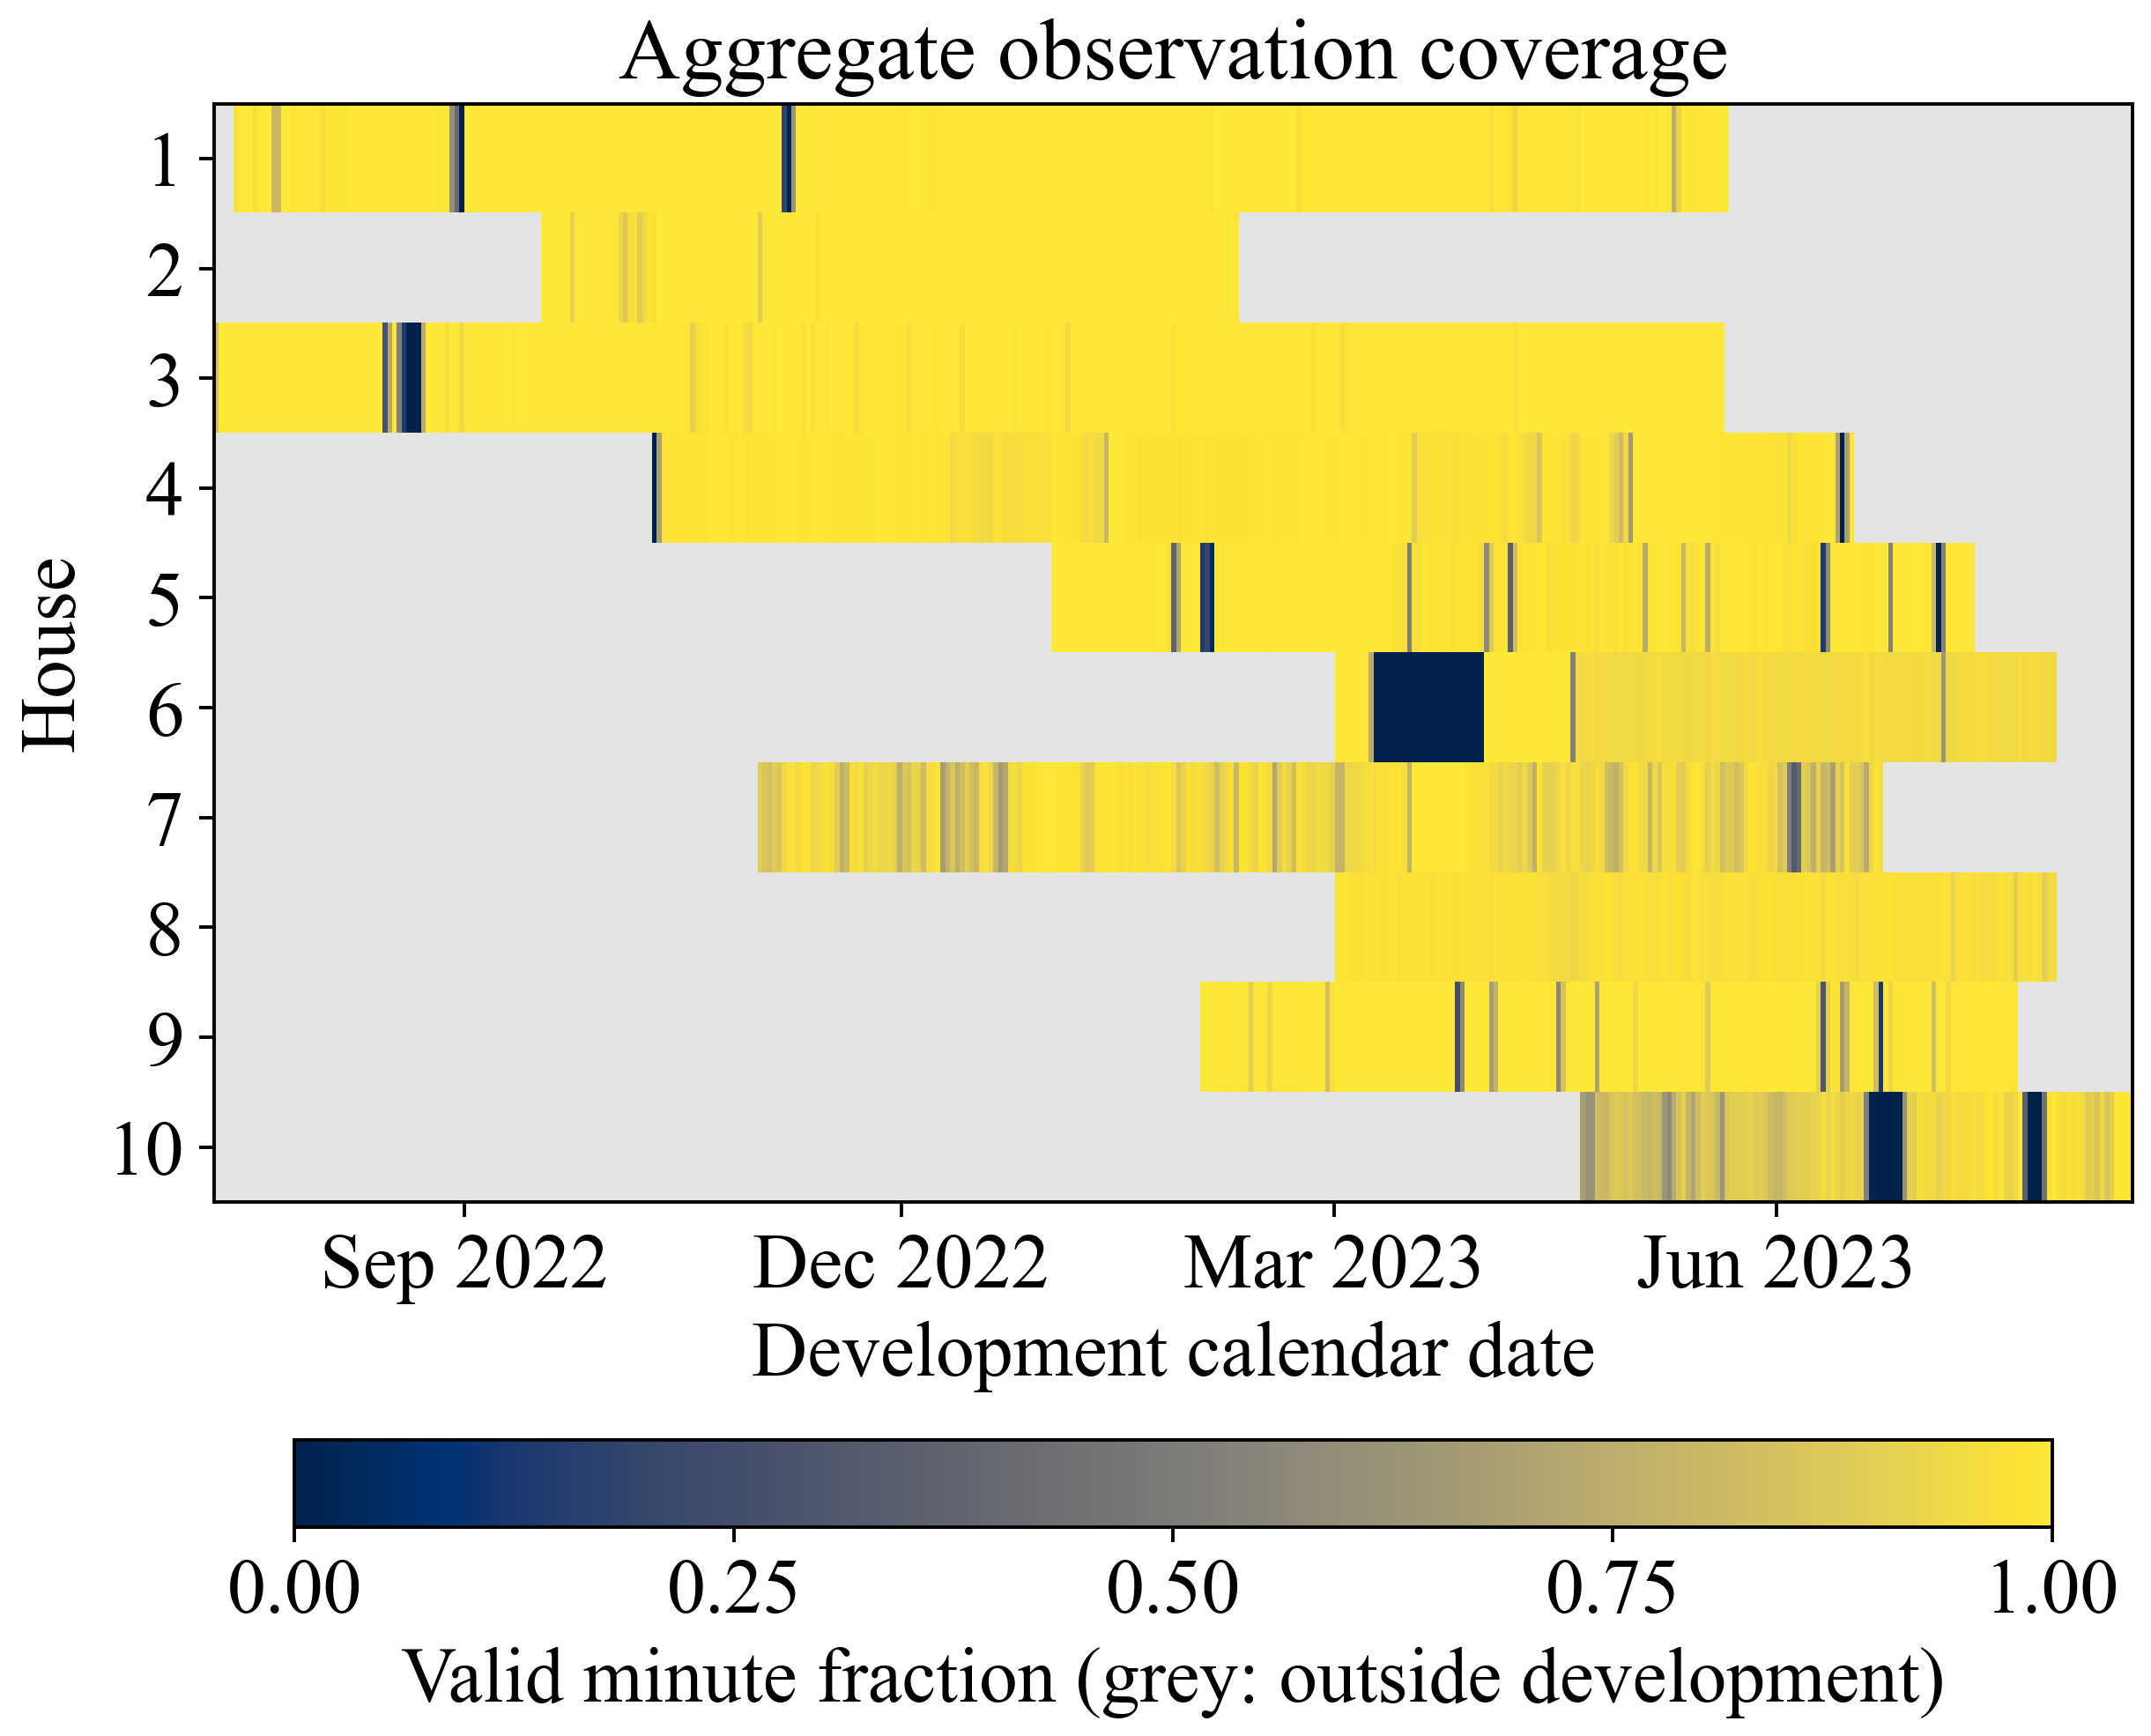

In [36]:
# Figure export verifies the real font, all text sizes and PNG density before inline display.
from IPython.display import Image
from PIL import Image as PILImage
import matplotlib.dates as mdates
from matplotlib.text import Text
FIGURE_PNG = ROOT / "Figures/PNG" / RUN
FIGURE_PDF = ROOT / "Figures/PDF" / RUN
FIGURE_PNG.mkdir(parents=True, exist_ok=True)
FIGURE_PDF.mkdir(parents=True, exist_ok=True)
figure_qa = []
def save_figure(fig, name):
    fig.canvas.draw()
    texts = [t for t in fig.findobj(Text) if t.get_visible() and t.get_text().strip()]
    for text_item in texts:
        assert 18 <= text_item.get_fontsize() <= 20, (text_item.get_text(), text_item.get_fontsize())
        resolved = font_manager.findfont(text_item.get_fontproperties(), fallback_to_default=False)
        assert font_manager.FontProperties(fname=resolved).get_name() == "Times New Roman"
    png = FIGURE_PNG / f"{name}.png"
    pdf = FIGURE_PDF / f"{name}.pdf"
    fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.06)
    fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.06)
    with PILImage.open(png) as im:
        assert all(abs(d - 350) < .02 for d in im.info["dpi"])
        figure_qa.append({"Figure": name, "Width px": im.width, "Height px": im.height, "DPI": im.info["dpi"][0],
                          "Font": "Times New Roman", "Text items checked": len(texts)})
    plt.close(fig)
    display(Image(filename=str(png)))

coverage_matrix = daily_coverage.pivot(index="House", columns="Date", values="Coverage")
calendar_days = pd.date_range(coverage_matrix.columns.min(), coverage_matrix.columns.max(), freq="D")
coverage_matrix = coverage_matrix.reindex(columns=calendar_days)
cmap = mpl.colormaps["cividis"].copy()
cmap.set_bad("#e4e4e4")
fig, ax = plt.subplots(figsize=(7.0, 5.6), layout="constrained")
extent = [mdates.date2num(calendar_days[0]), mdates.date2num(calendar_days[-1] + pd.Timedelta(days=1)), 10.5, .5]
image = ax.imshow(coverage_matrix.to_numpy(), vmin=0, vmax=1, cmap=cmap, aspect="auto", extent=extent, interpolation="none")
ax.set_yticks(range(1,11))
ax.set_ylabel("House")
ax.set_xlabel("Development calendar date")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Aggregate observation coverage")
bar = fig.colorbar(image, ax=ax, orientation="horizontal", pad=.04, fraction=.08, ticks=[0,.25,.5,.75,1])
bar.set_label("Valid minute fraction (grey: outside development)")
save_figure(fig, "01_daily_aggregate_coverage")

In [37]:
# Each unavailable run is one event; minutes and events answer different questions.
gap_summary = gap_lengths.groupby("House")["Length (min)"].agg(
    Events="size", Median="median", q95=lambda s:s.quantile(.95), Maximum="max").reset_index()
table(gap_summary, "aggregate_gap_summary", "Table 24. Aggregate unavailability runs: duration in minutes.", precision=1)
unparseable = timestamp_quality.groupby("House").agg(
    timestamp_rows=("Timestamp rows","sum"), unparseable=("Unparseable timestamps","sum")).reset_index()
table(unparseable, "unparseable_channel_timestamps", "Table 25. Timestamp-only parse failures across original channel files; failed timestamps are never assigned a guessed date.", precision=0)

House,Events,Median,q95,Maximum
1,672,1.0,12.4,1440
2,769,1.0,2.0,150
3,1192,1.0,2.0,5523
4,5263,1.0,2.0,2305
5,1950,1.0,2.0,2376
6,4873,1.0,3.0,33485
7,18800,1.0,3.0,180
8,4434,1.0,3.0,84
9,1733,1.0,8.0,374
10,12341,1.0,3.0,11200


House,timestamp_rows,unparseable
1,30300560,67674
2,11944368,18845
3,29463890,0
4,22501359,0
5,14659191,0
6,11871834,11694
7,21428302,0
8,13927283,0
9,10413053,0
10,10598970,0


**Interpretation.** Typical unavailable runs are short in every house, but Houses 6 and 10 contain very long runs, quantified in the computed run-length table. Their long tails make independent point masking an incomplete stress test. The run definition combines absent, invalid and insufficiently covered observations; it is not a direct count of confirmed network outages.

## 11. Power distributions after the eligibility refinement

Boxplots summarize the actual eligible development targets: boxes show the interquartile range, bars the median, whiskers the 5th–95th percentiles, diamonds the 99th percentile, and open circles the maximum. The symmetric-log scale is linear below 0.05 kW and logarithmic above it; zero remains visible. No display limit removes valid high-load observations. The numeric quantiles and sample sizes are saved with the figure.

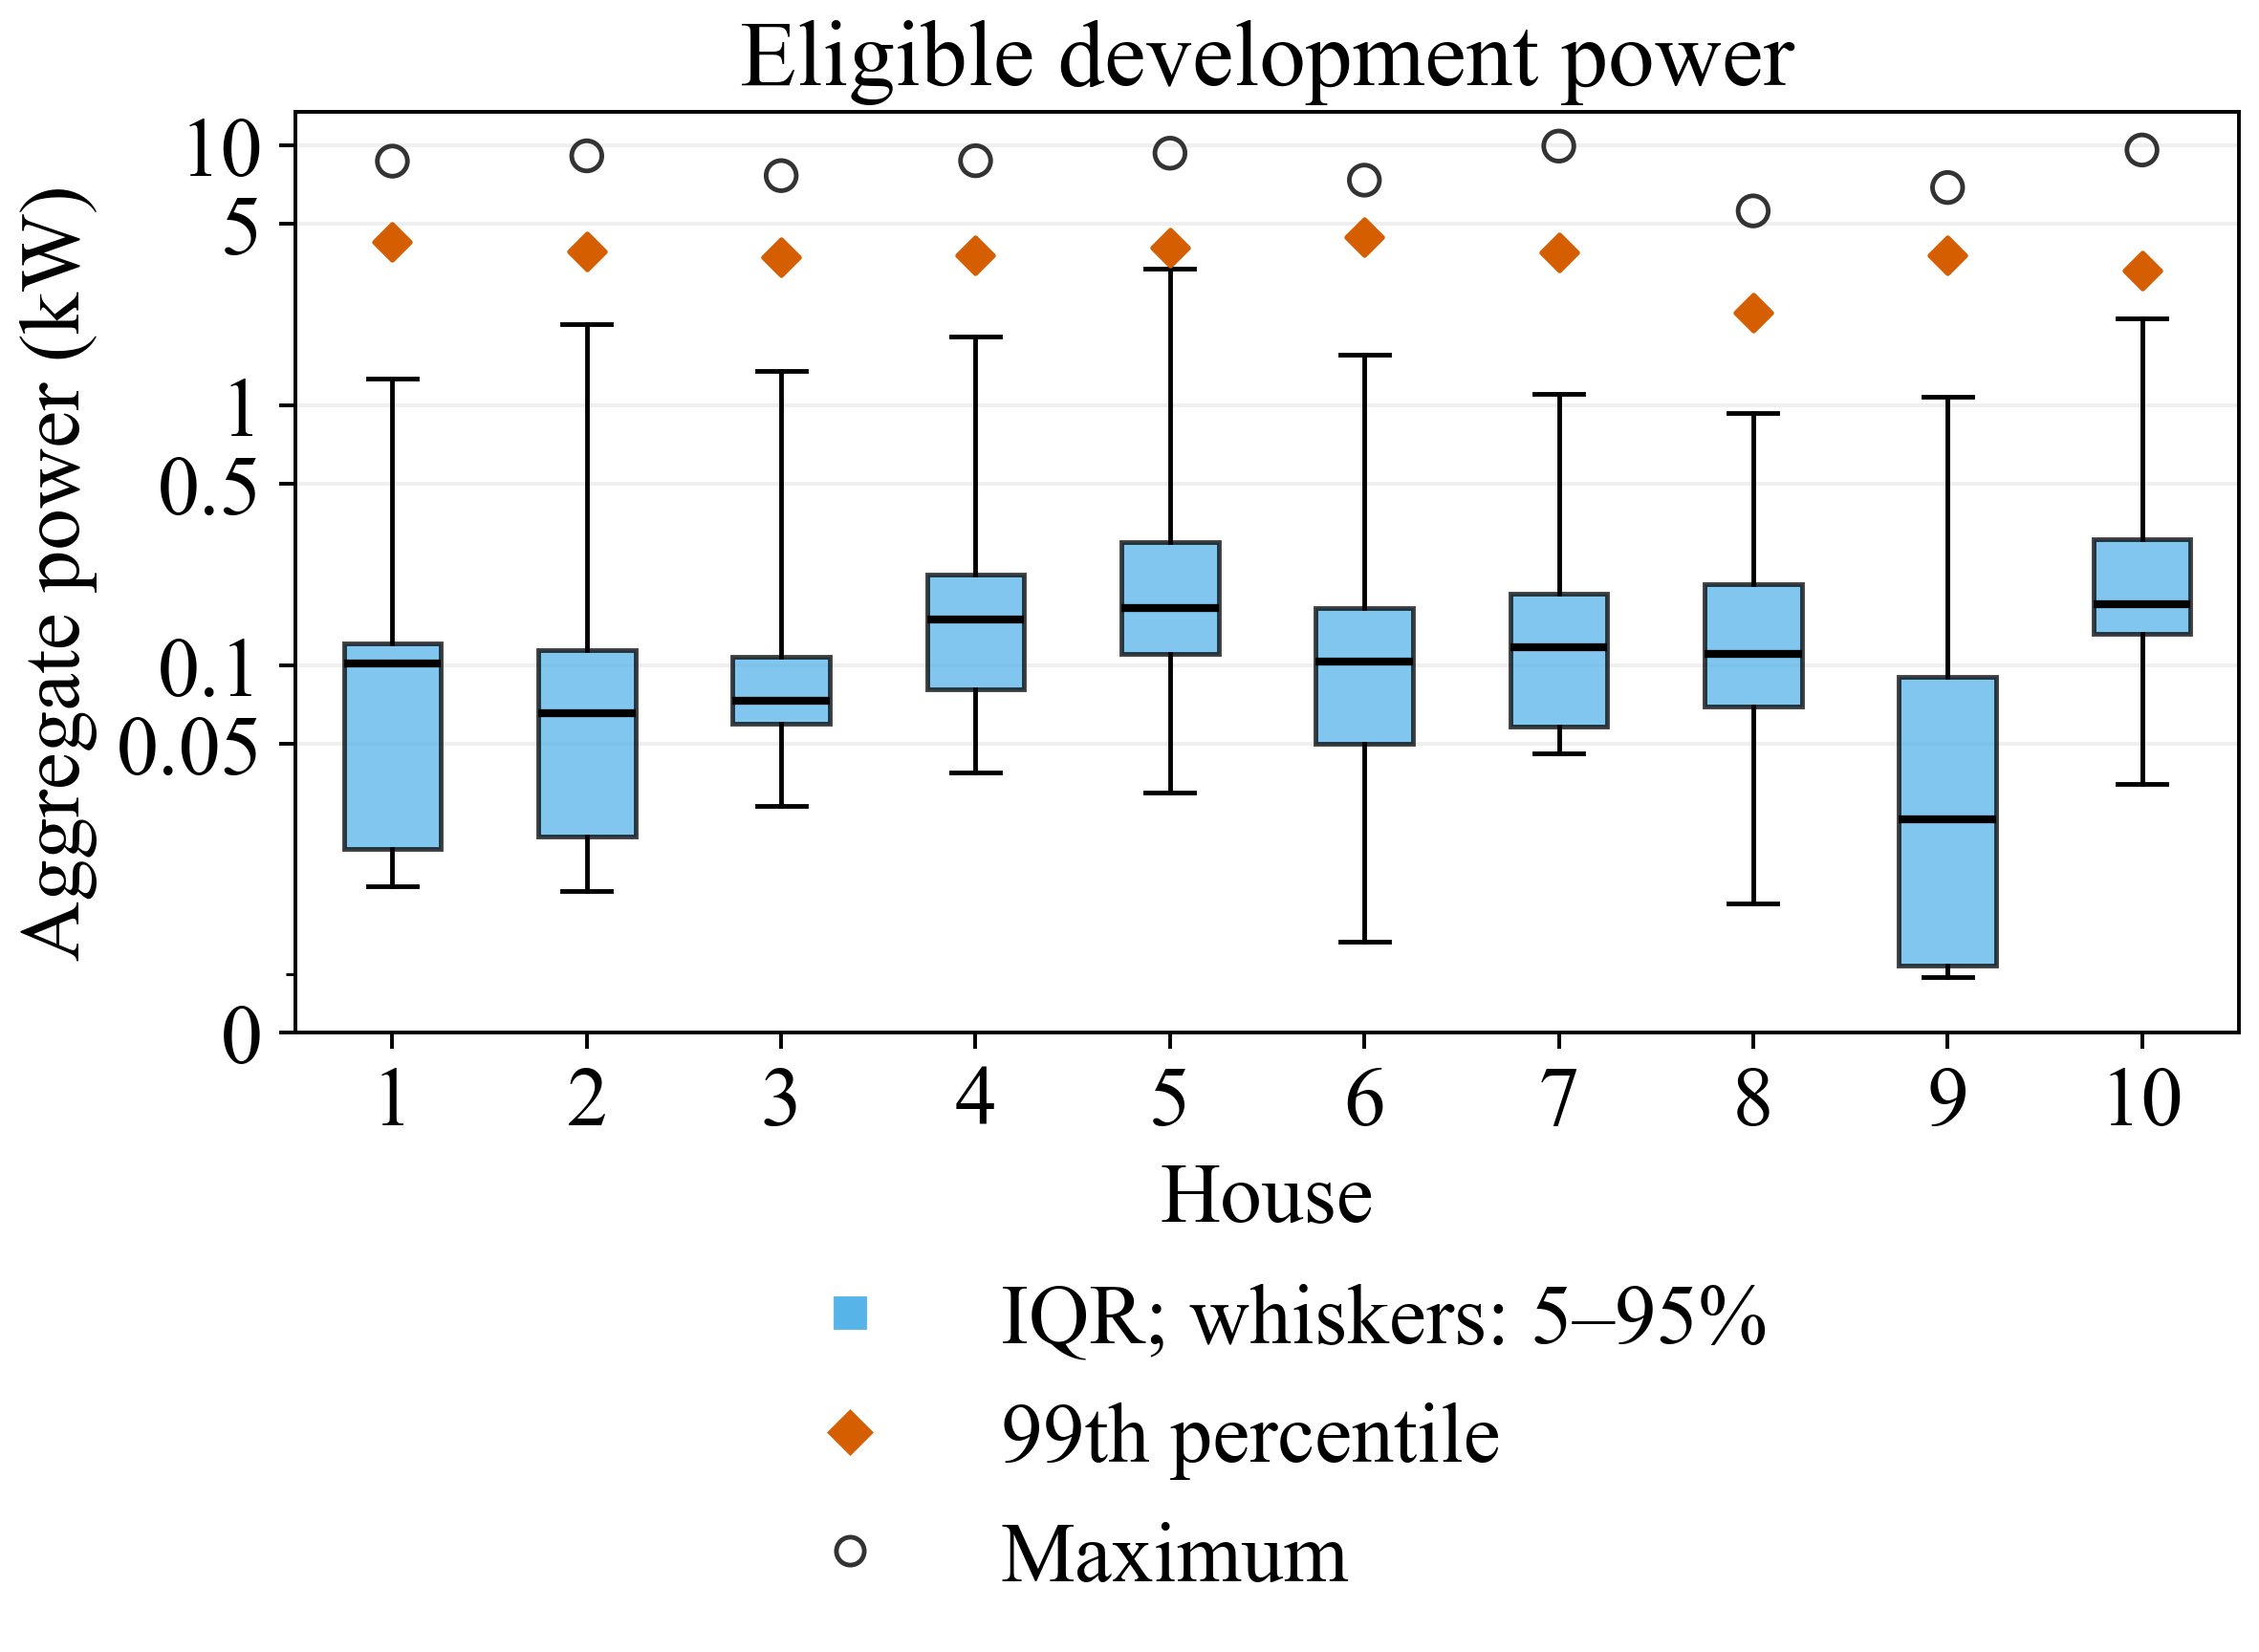

In [38]:
# Distribution estimates use all eligible development targets, without subsampling.
from matplotlib.lines import Line2D
distribution_rows = []
box_stats = []
for house, info in development.items():
    y = info["values"].loc[info["target_mask"], "P_agg"]
    quantiles = y.quantile([.05,.25,.5,.75,.95,.99])
    distribution_rows.append({"House":house, "n":len(y), "Mean (kW)":y.mean(), "SD (kW)":y.std(),
        "Minimum (kW)":y.min(), "Maximum (kW)":y.max(),
        **{f"q{int(q*100):02d} (kW)":value for q,value in quantiles.items()}})
    box_stats.append({"label":str(house), "whislo":quantiles.loc[.05], "q1":quantiles.loc[.25],
                      "med":quantiles.loc[.5], "q3":quantiles.loc[.75], "whishi":quantiles.loc[.95], "fliers":[]})
distribution = pd.DataFrame(distribution_rows)
distribution.to_csv(TABLES / "refined_target_quantiles.csv", index=False)
fig, ax = plt.subplots(figsize=(7.0,5.0))
ax.bxp(box_stats, showfliers=False, patch_artist=True,
       boxprops={"facecolor":"#56B4E9","alpha":.75}, medianprops={"color":"black","linewidth":1.7})
ax.scatter(distribution.House, distribution["q99 (kW)"], marker="D", s=30, color="#D55E00", zorder=3)
ax.scatter(distribution.House, distribution["Maximum (kW)"], marker="o", s=42, facecolors="none", edgecolors="#333333", zorder=3)
ax.set_yscale("symlog", linthresh=.05)
ax.set_ylim(bottom=0)
ax.set_yticks([0,.05,.1,.5,1,5,10,50,100])
ax.set_yticklabels(["0","0.05","0.1","0.5","1","5","10","50","100"])
ax.set_ylim(0,max(distribution["Maximum (kW)"])*1.35)
ax.set_xlabel("House")
ax.set_ylabel("Aggregate power (kW)")
ax.set_title("Eligible development power")
ax.grid(axis="y",alpha=.2)
handles=[Line2D([0],[0],marker="s",color="#56B4E9",linestyle="none",label="IQR; whiskers: 5–95%"),
         Line2D([0],[0],marker="D",color="#D55E00",linestyle="none",label="99th percentile"),
         Line2D([0],[0],marker="o",markerfacecolor="none",color="#333333",linestyle="none",label="Maximum")]
ax.legend(handles=handles,loc="upper center",bbox_to_anchor=(.5,-.19),ncol=1,frameon=False)
fig.subplots_adjust(left=.15,right=.98,top=.9,bottom=.35)
save_figure(fig, "02_eligible_power_distributions")

**Interpretation.** The computed quantile table records each house's eligible maximum after equipment-based exclusions. The figure shows every household's tail summaries, rather than clipping them at a chosen load quantile. Its vertical axis is symmetric-logarithmic, linear below 0.05 kW; boxes are the interquartile range, central lines the median, whiskers the 5th–95th percentiles, diamonds the 99th percentile and open circles the maximum.

## 12. Current auxiliary availability and physical residuals

The heatmap measures how often a current auxiliary sensor is valid on eligible target minutes. It describes alignment at the minute interval, not simultaneous raw sampling. Blank cells indicate an absent nominal sensor. Environmental reporting is sparse and will require causal age-aware handling in Notebook 02; it is not filled here. Complete-submeter residual and monitored-fraction quantiles are computed only when every nominal power channel is available. House 8 is omitted from physical-balance plots because identical streams with conflicting names cannot be counted as separate loads.

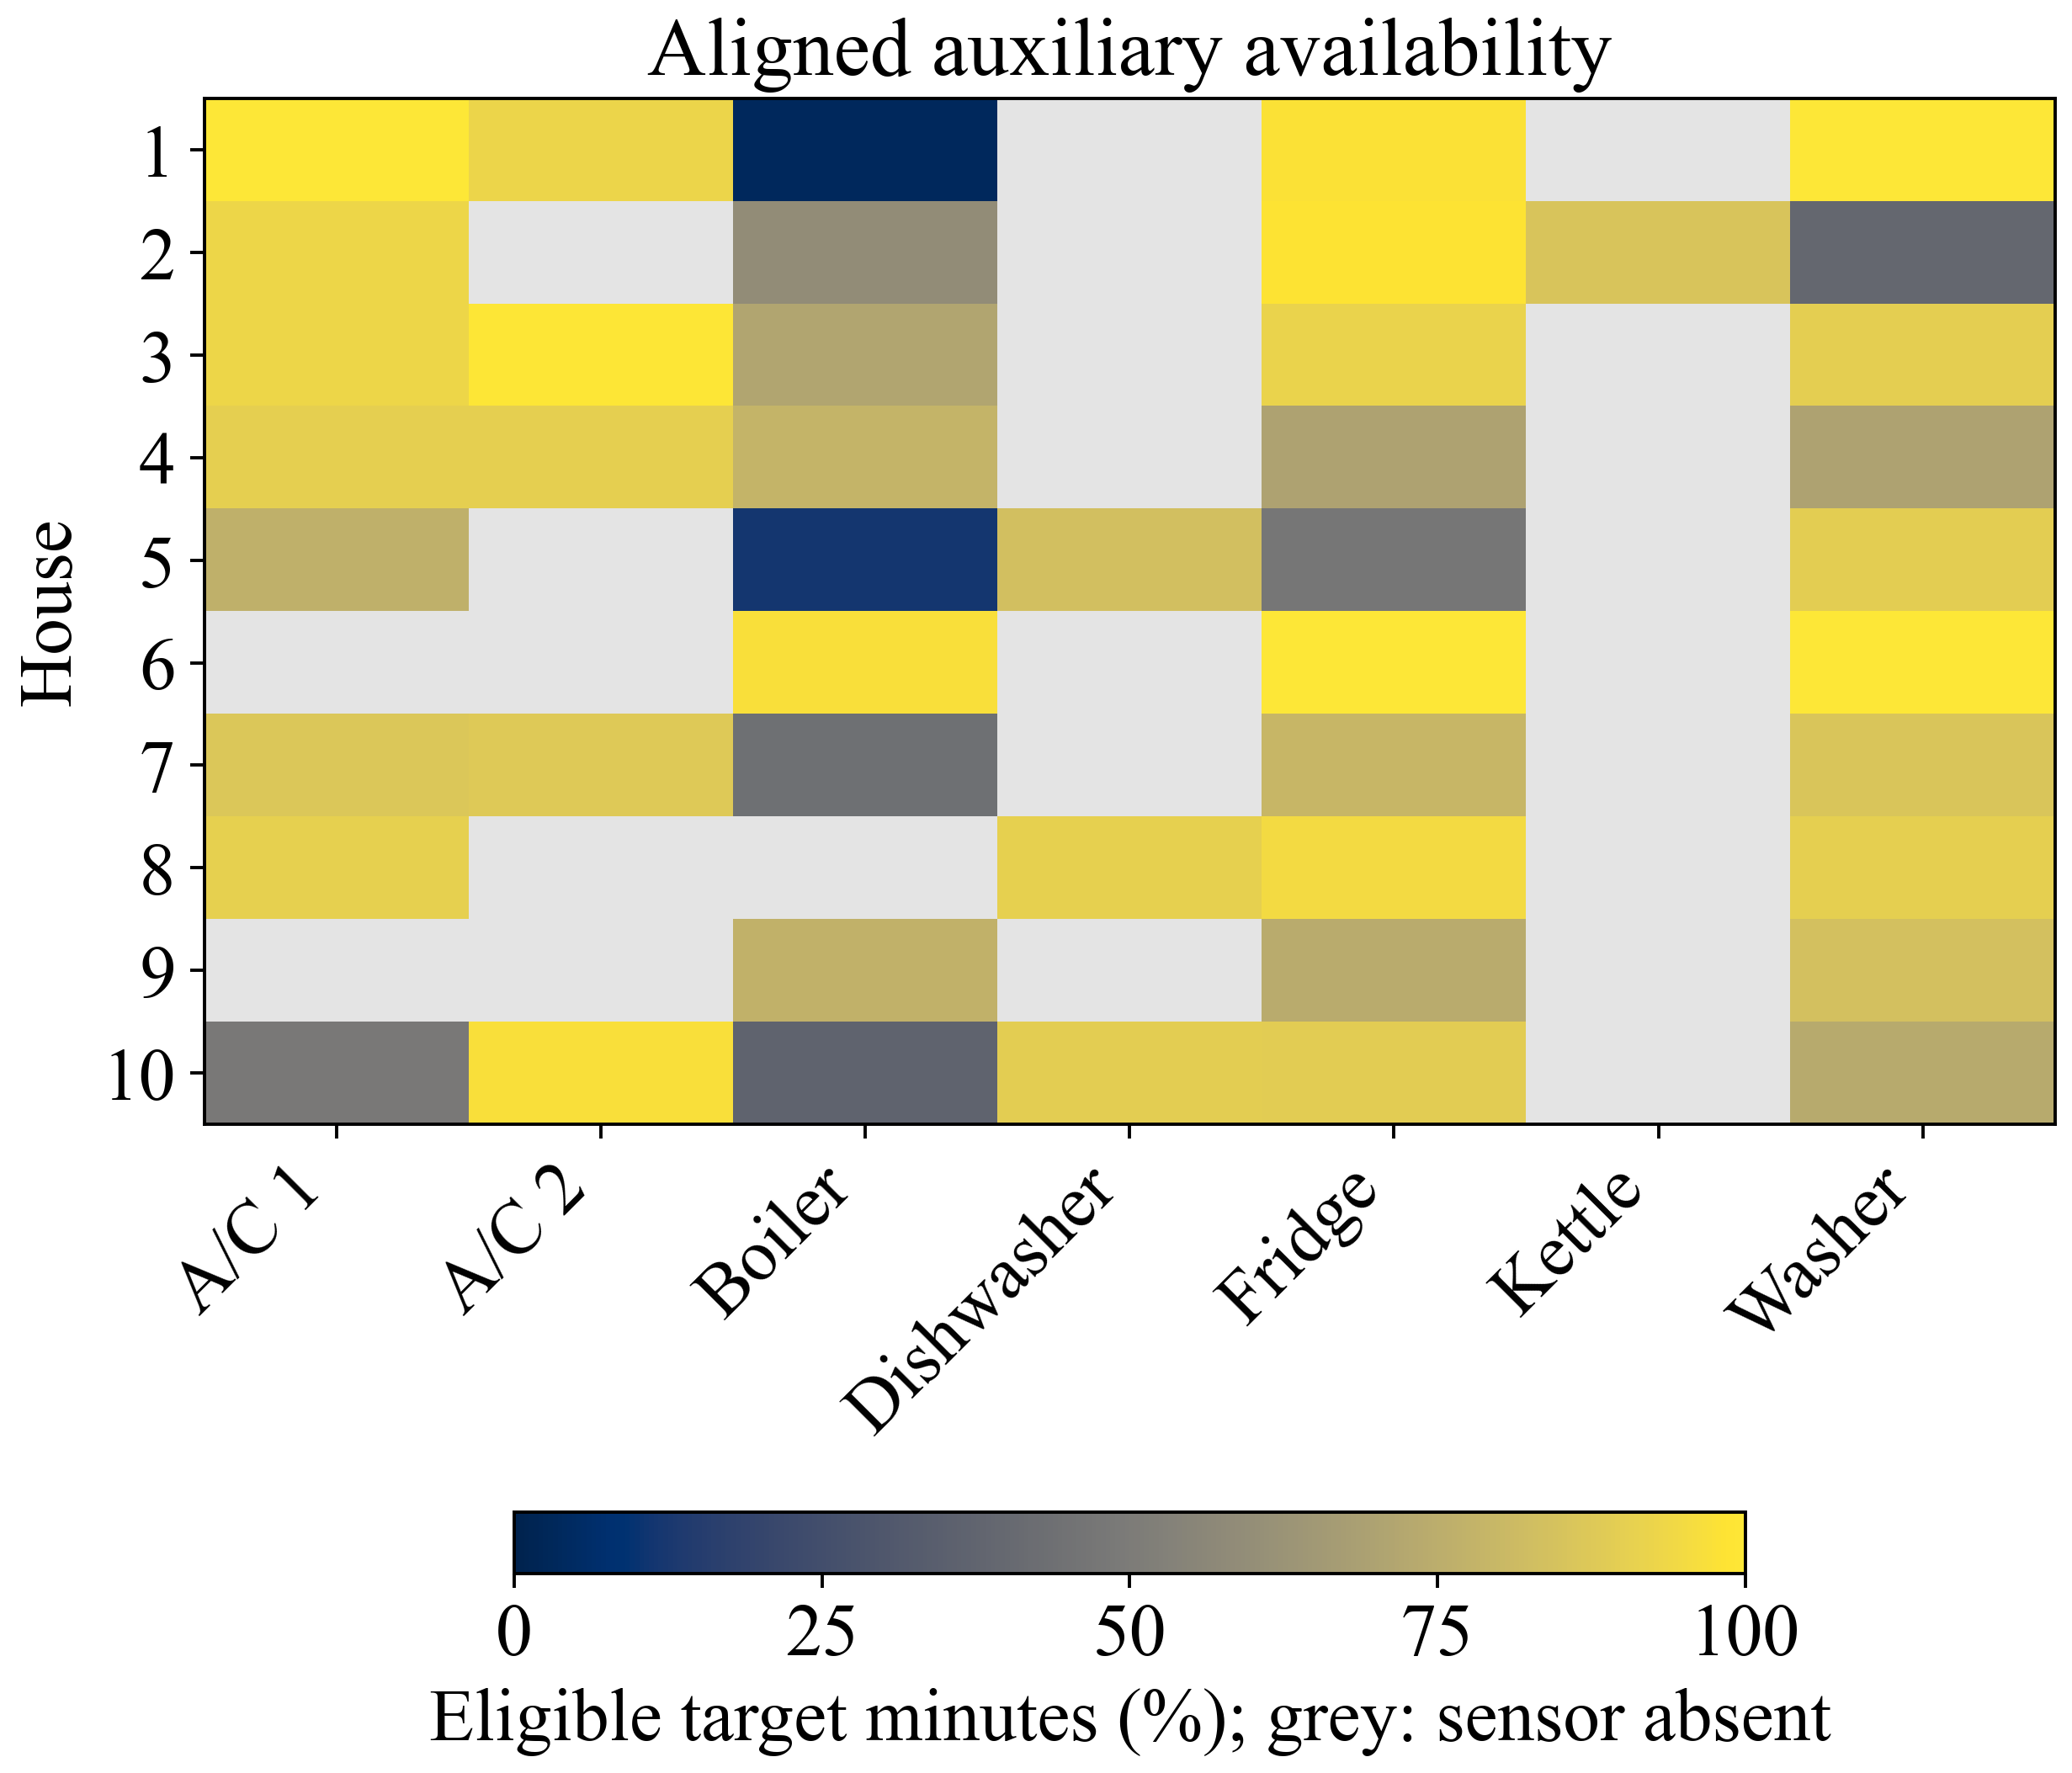

In [39]:
# Minute alignment respects channel-specific validity and existing house-specific composition.
sensor_order = sorted(synchronization.Sensor.unique())
sync_matrix = synchronization.pivot(index="House", columns="Sensor", values="Current auxiliary available (%)").reindex(columns=sensor_order)
sync_matrix.to_csv(TABLES / "auxiliary_availability_matrix.csv")
labels = {"ac_1":"A/C 1", "ac_2":"A/C 2", "boiler":"Boiler", "dishwasher":"Dishwasher", "fridge":"Fridge",
          "kettle":"Kettle", "washing_machine":"Washer"}
cmap = mpl.colormaps["cividis"].copy()
cmap.set_bad("#e4e4e4")
fig, ax = plt.subplots(figsize=(7.0,6.0),layout="constrained")
im = ax.imshow(sync_matrix.to_numpy(),vmin=0,vmax=100,cmap=cmap,aspect="auto")
ax.set_yticks(range(10),labels=[str(h) for h in sync_matrix.index])
ax.set_xticks(range(len(sensor_order)),labels=[labels.get(s,s) for s in sensor_order],rotation=45,ha="right")
ax.set_ylabel("House")
ax.set_title("Aligned auxiliary availability")
cb = fig.colorbar(im,ax=ax,orientation="horizontal",pad=.06,fraction=.06,ticks=[0,25,50,75,100])
cb.set_label("Eligible target minutes (%); grey: sensor absent")
save_figure(fig,"03_current_auxiliary_availability")

**Interpretation.** Installed sensor composition and actual current availability are different quantities. Grey cells identify structurally absent sensors; colours represent empirical availability among eligible aggregate targets. Unequal boiler coverage and the two nominally duplicated House 8 streams motivate explicit masks and train-fitted redundancy handling.

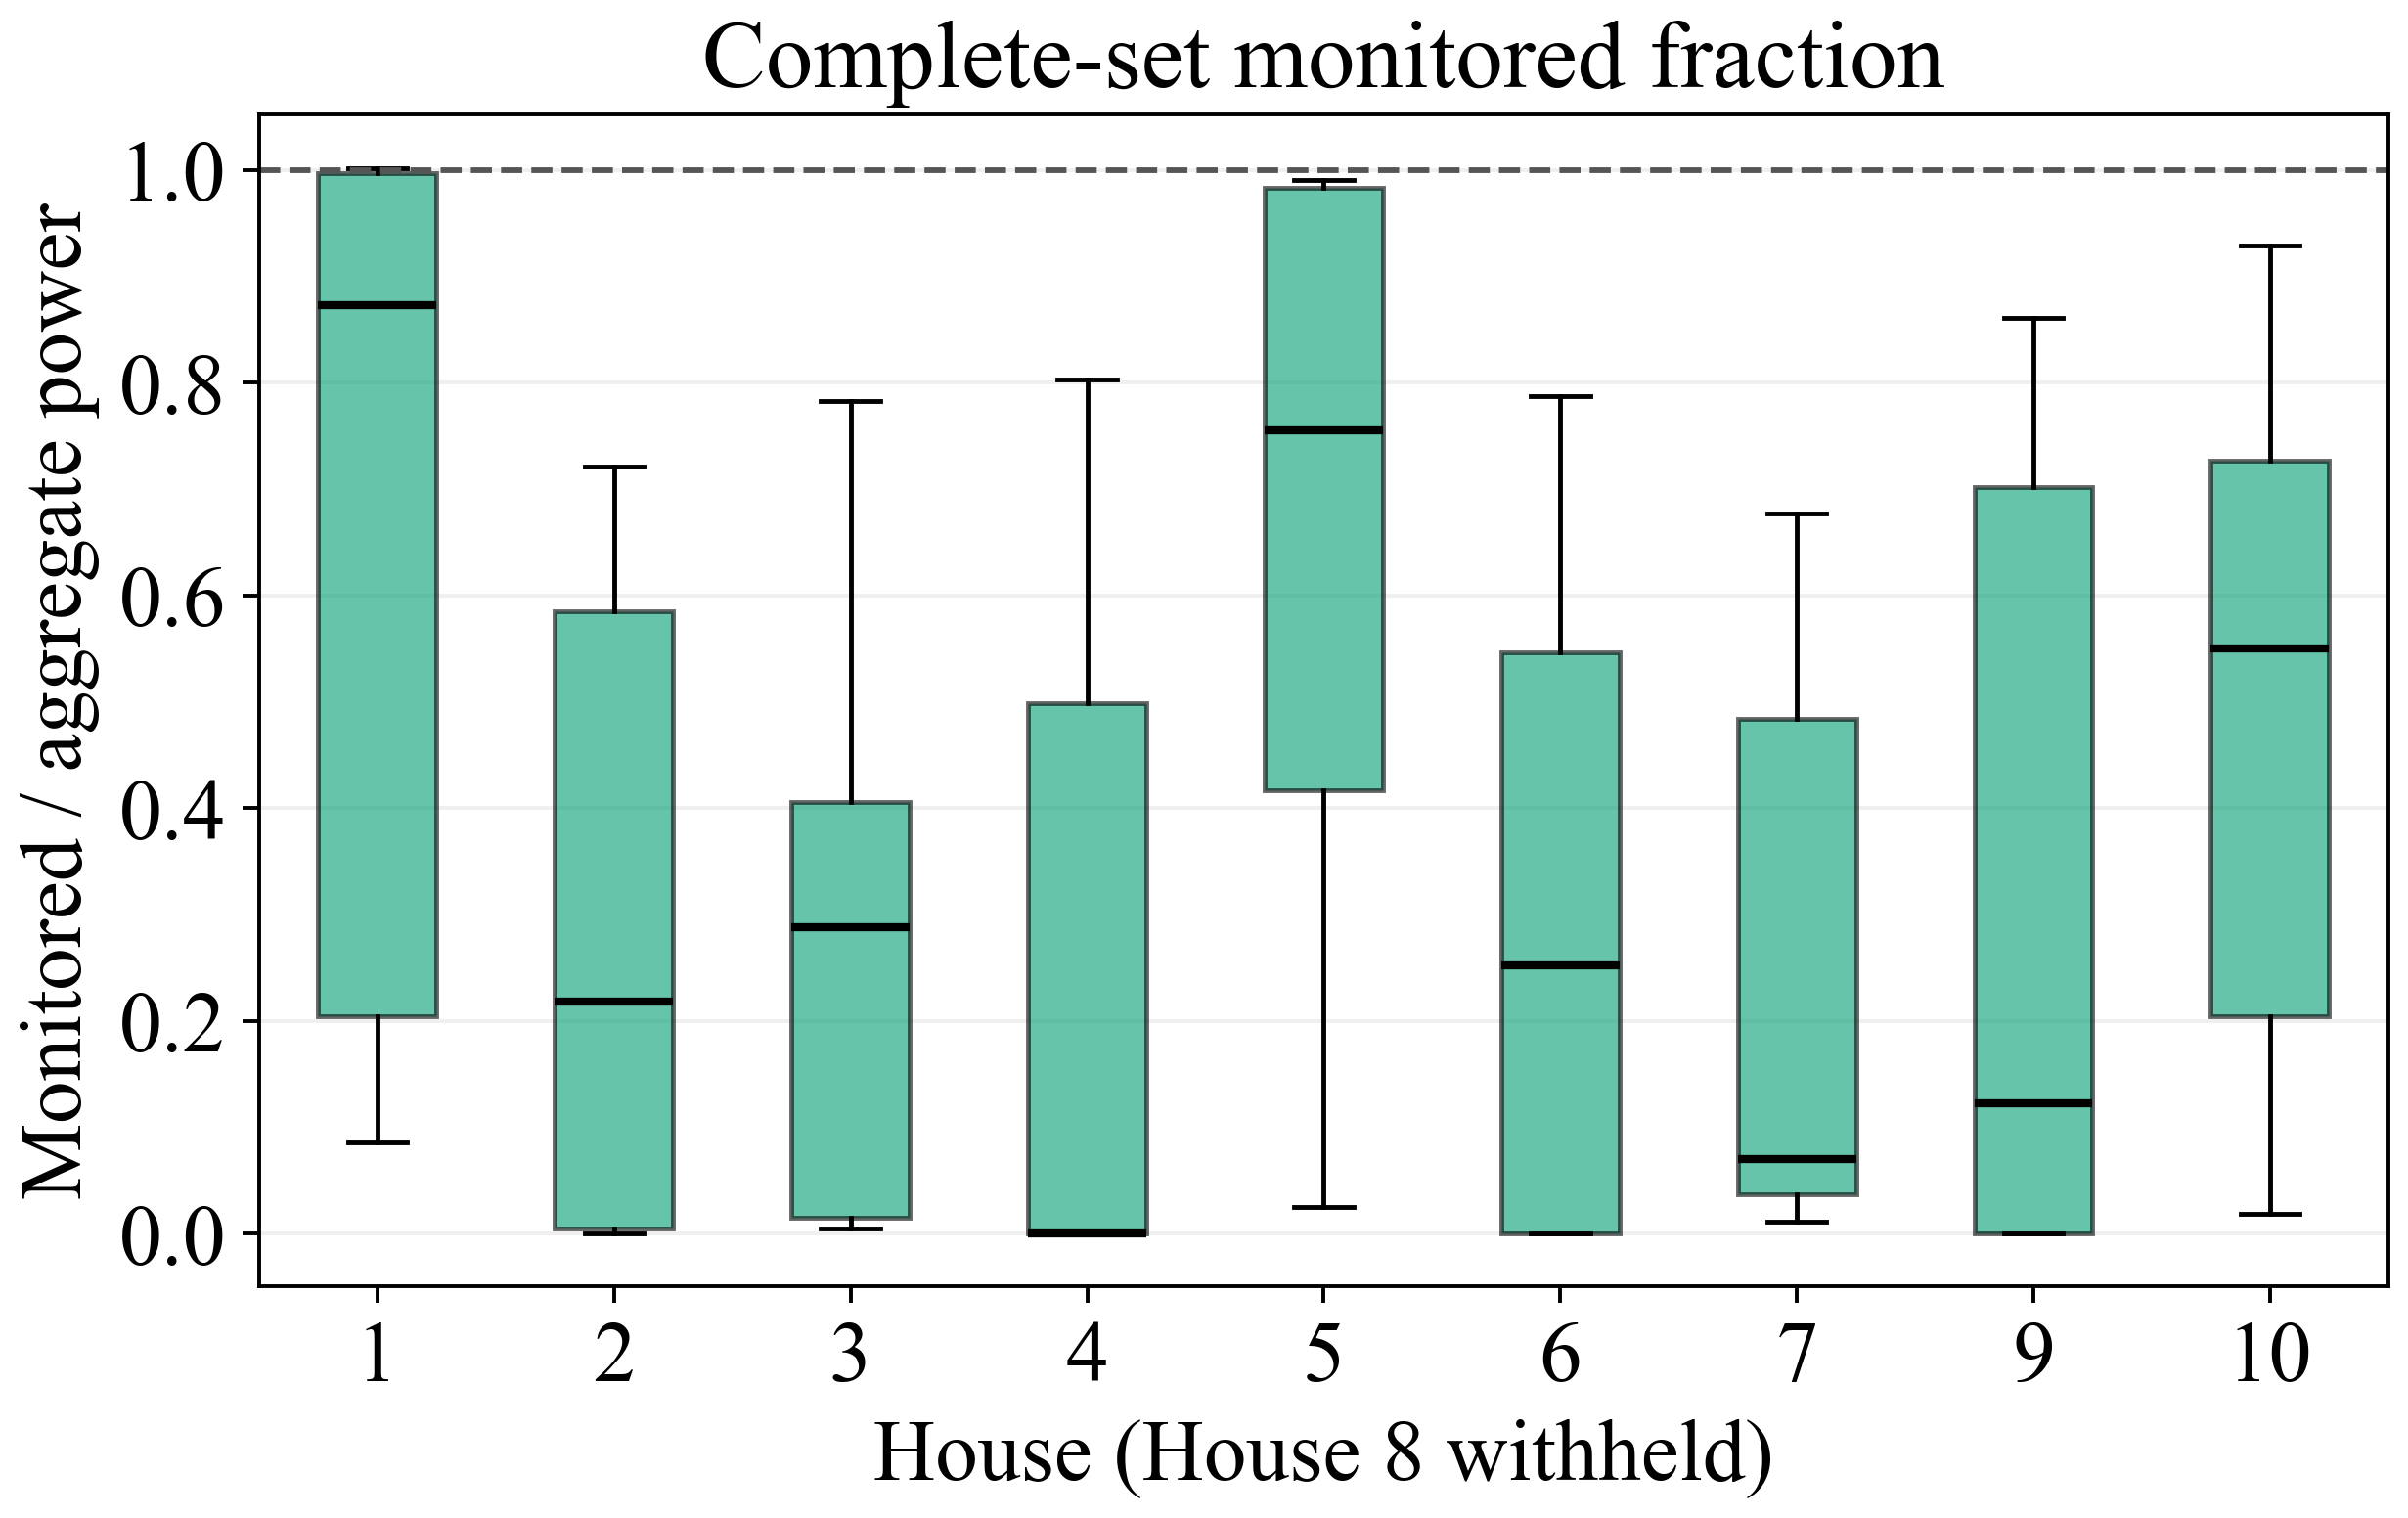

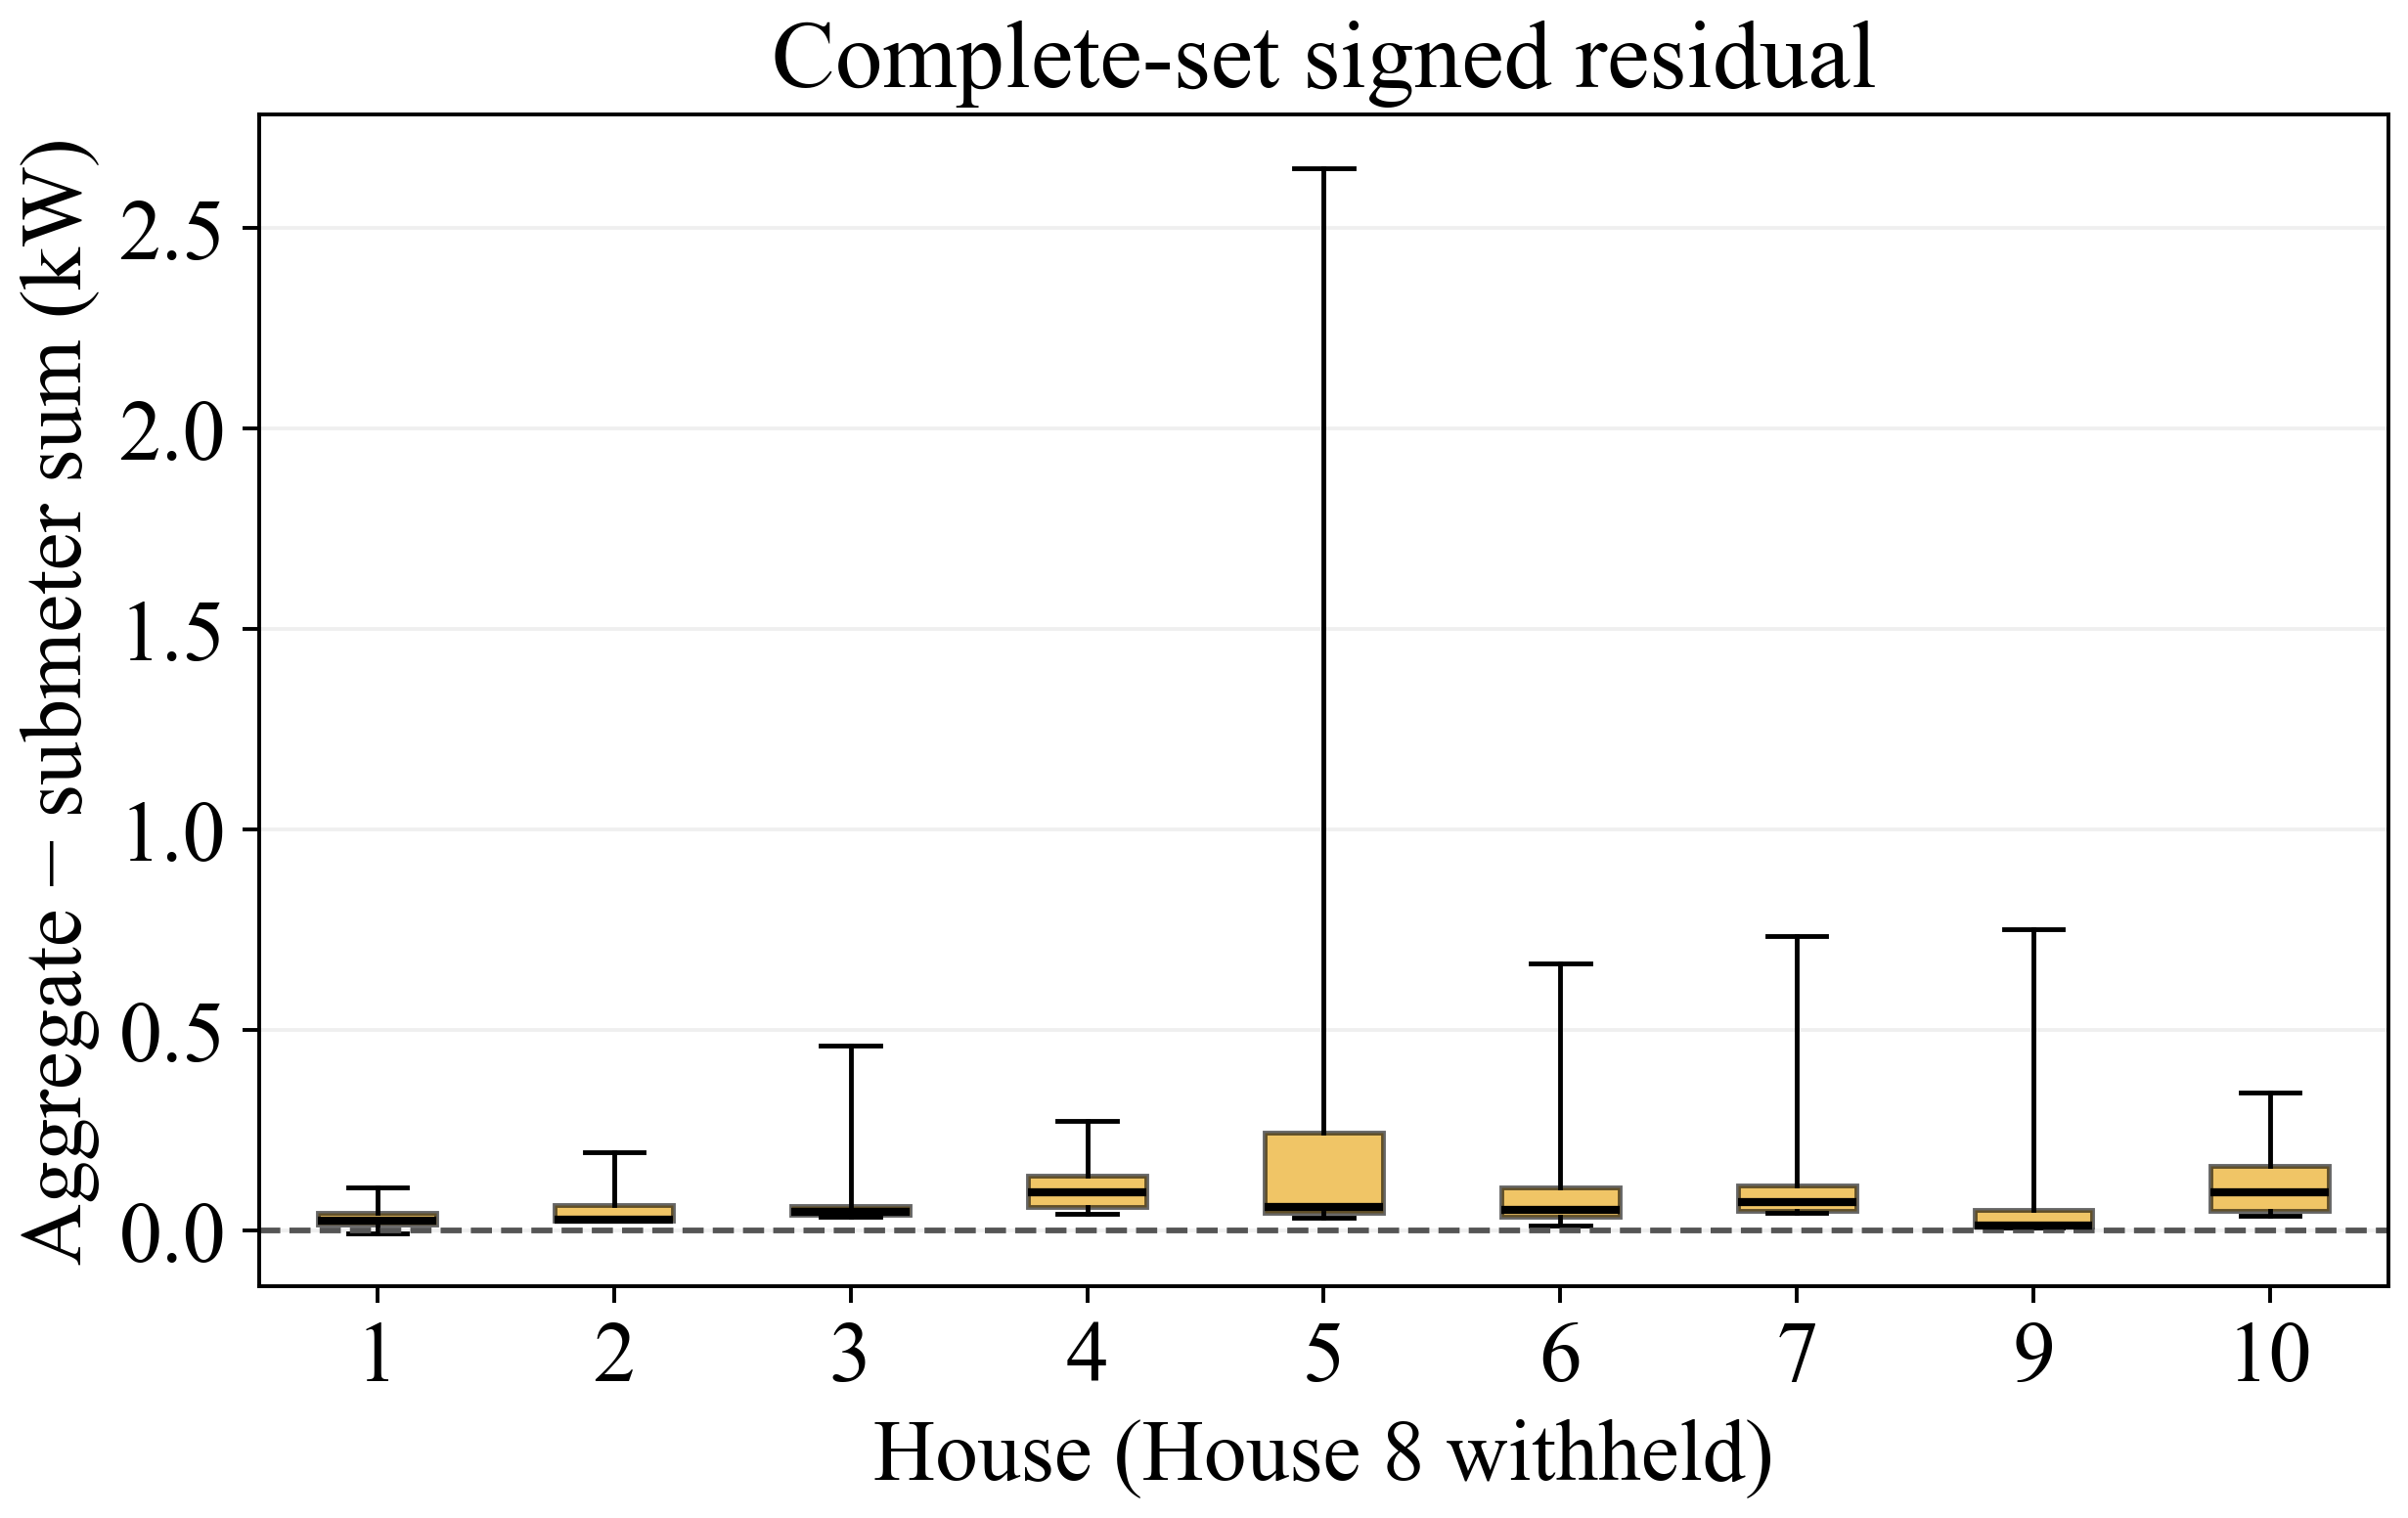

House,Complete-set minutes,Negative residual (%)
1,15460,10.1940
2,35130,0.2590
3,285701,1.7861
4,138906,0.3448
5,9249,2.4759
6,168584,0.1240
7,89907,0.0234
8,169362,Unavailable
9,130508,1.5578
10,25738,0.4041


In [40]:
# Physical diagnostics retain signed residuals; they are never inference features.
balance_boxes, residual_boxes = [], []
for house, info in development.items():
    if house in ambiguous_houses: continue
    for series, boxes in [(info["monitored_fraction"], balance_boxes),(info["residual"],residual_boxes)]:
        q = series.quantile([.05,.25,.5,.75,.95])
        boxes.append({"label":str(house),"whislo":q.loc[.05],"q1":q.loc[.25],"med":q.loc[.5],
                      "q3":q.loc[.75],"whishi":q.loc[.95],"fliers":[]})
fig, ax = plt.subplots(figsize=(7.0,4.4),layout="constrained")
ax.bxp(balance_boxes,showfliers=False,patch_artist=True,
       boxprops={"facecolor":"#009E73","alpha":.6},medianprops={"color":"black","linewidth":1.7})
ax.axhline(1,color="#555555",linestyle="--",linewidth=1.2)
ax.set_xlabel("House (House 8 withheld)")
ax.set_ylabel("Monitored / aggregate power")
ax.set_title("Complete-set monitored fraction")
ax.grid(axis="y",alpha=.2)
save_figure(fig,"04_monitored_fraction")
fig, ax = plt.subplots(figsize=(7.0,4.4),layout="constrained")
ax.bxp(residual_boxes,showfliers=False,patch_artist=True,
       boxprops={"facecolor":"#E69F00","alpha":.6},medianprops={"color":"black","linewidth":1.7})
ax.axhline(0,color="#555555",linestyle="--",linewidth=1.2)
ax.set_xlabel("House (House 8 withheld)")
ax.set_ylabel("Aggregate − submeter sum (kW)")
ax.set_title("Complete-set signed residual")
ax.grid(axis="y",alpha=.2)
save_figure(fig,"05_signed_residual")
table(final_balance[["House","Complete-set minutes","Negative residual (%)"]], "refined_negative_residual",
      "Table 26. Frequency of negative residuals on complete nominal-channel minutes; House 8 physical diagnostics are withheld.")

**Figure reading and interpretation.** Boxes show interquartile ranges, centre lines medians and whiskers the 5th–95th percentiles. The dashed references indicate monitored fraction 1 and residual 0. Residuals use complete nominal sets only; House 8 is excluded because its sensor identity is unresolved. House 1 has a material negative-residual frequency, quantified in the accompanying computed table. These complete-set subsets are selected by availability and do not represent all target minutes.

## 13. Development time-of-day and weekday structure

Profiles use all eligible target minutes. Each house first contributes its own mean for each time-of-day bin, and the displayed line is the median across houses; the band is the interquartile range across houses, not a confidence interval. Different observation seasons and missingness confound causal interpretation. Calendar labels use source-local Plegma timestamps; no undocumented UTC conversion is applied.

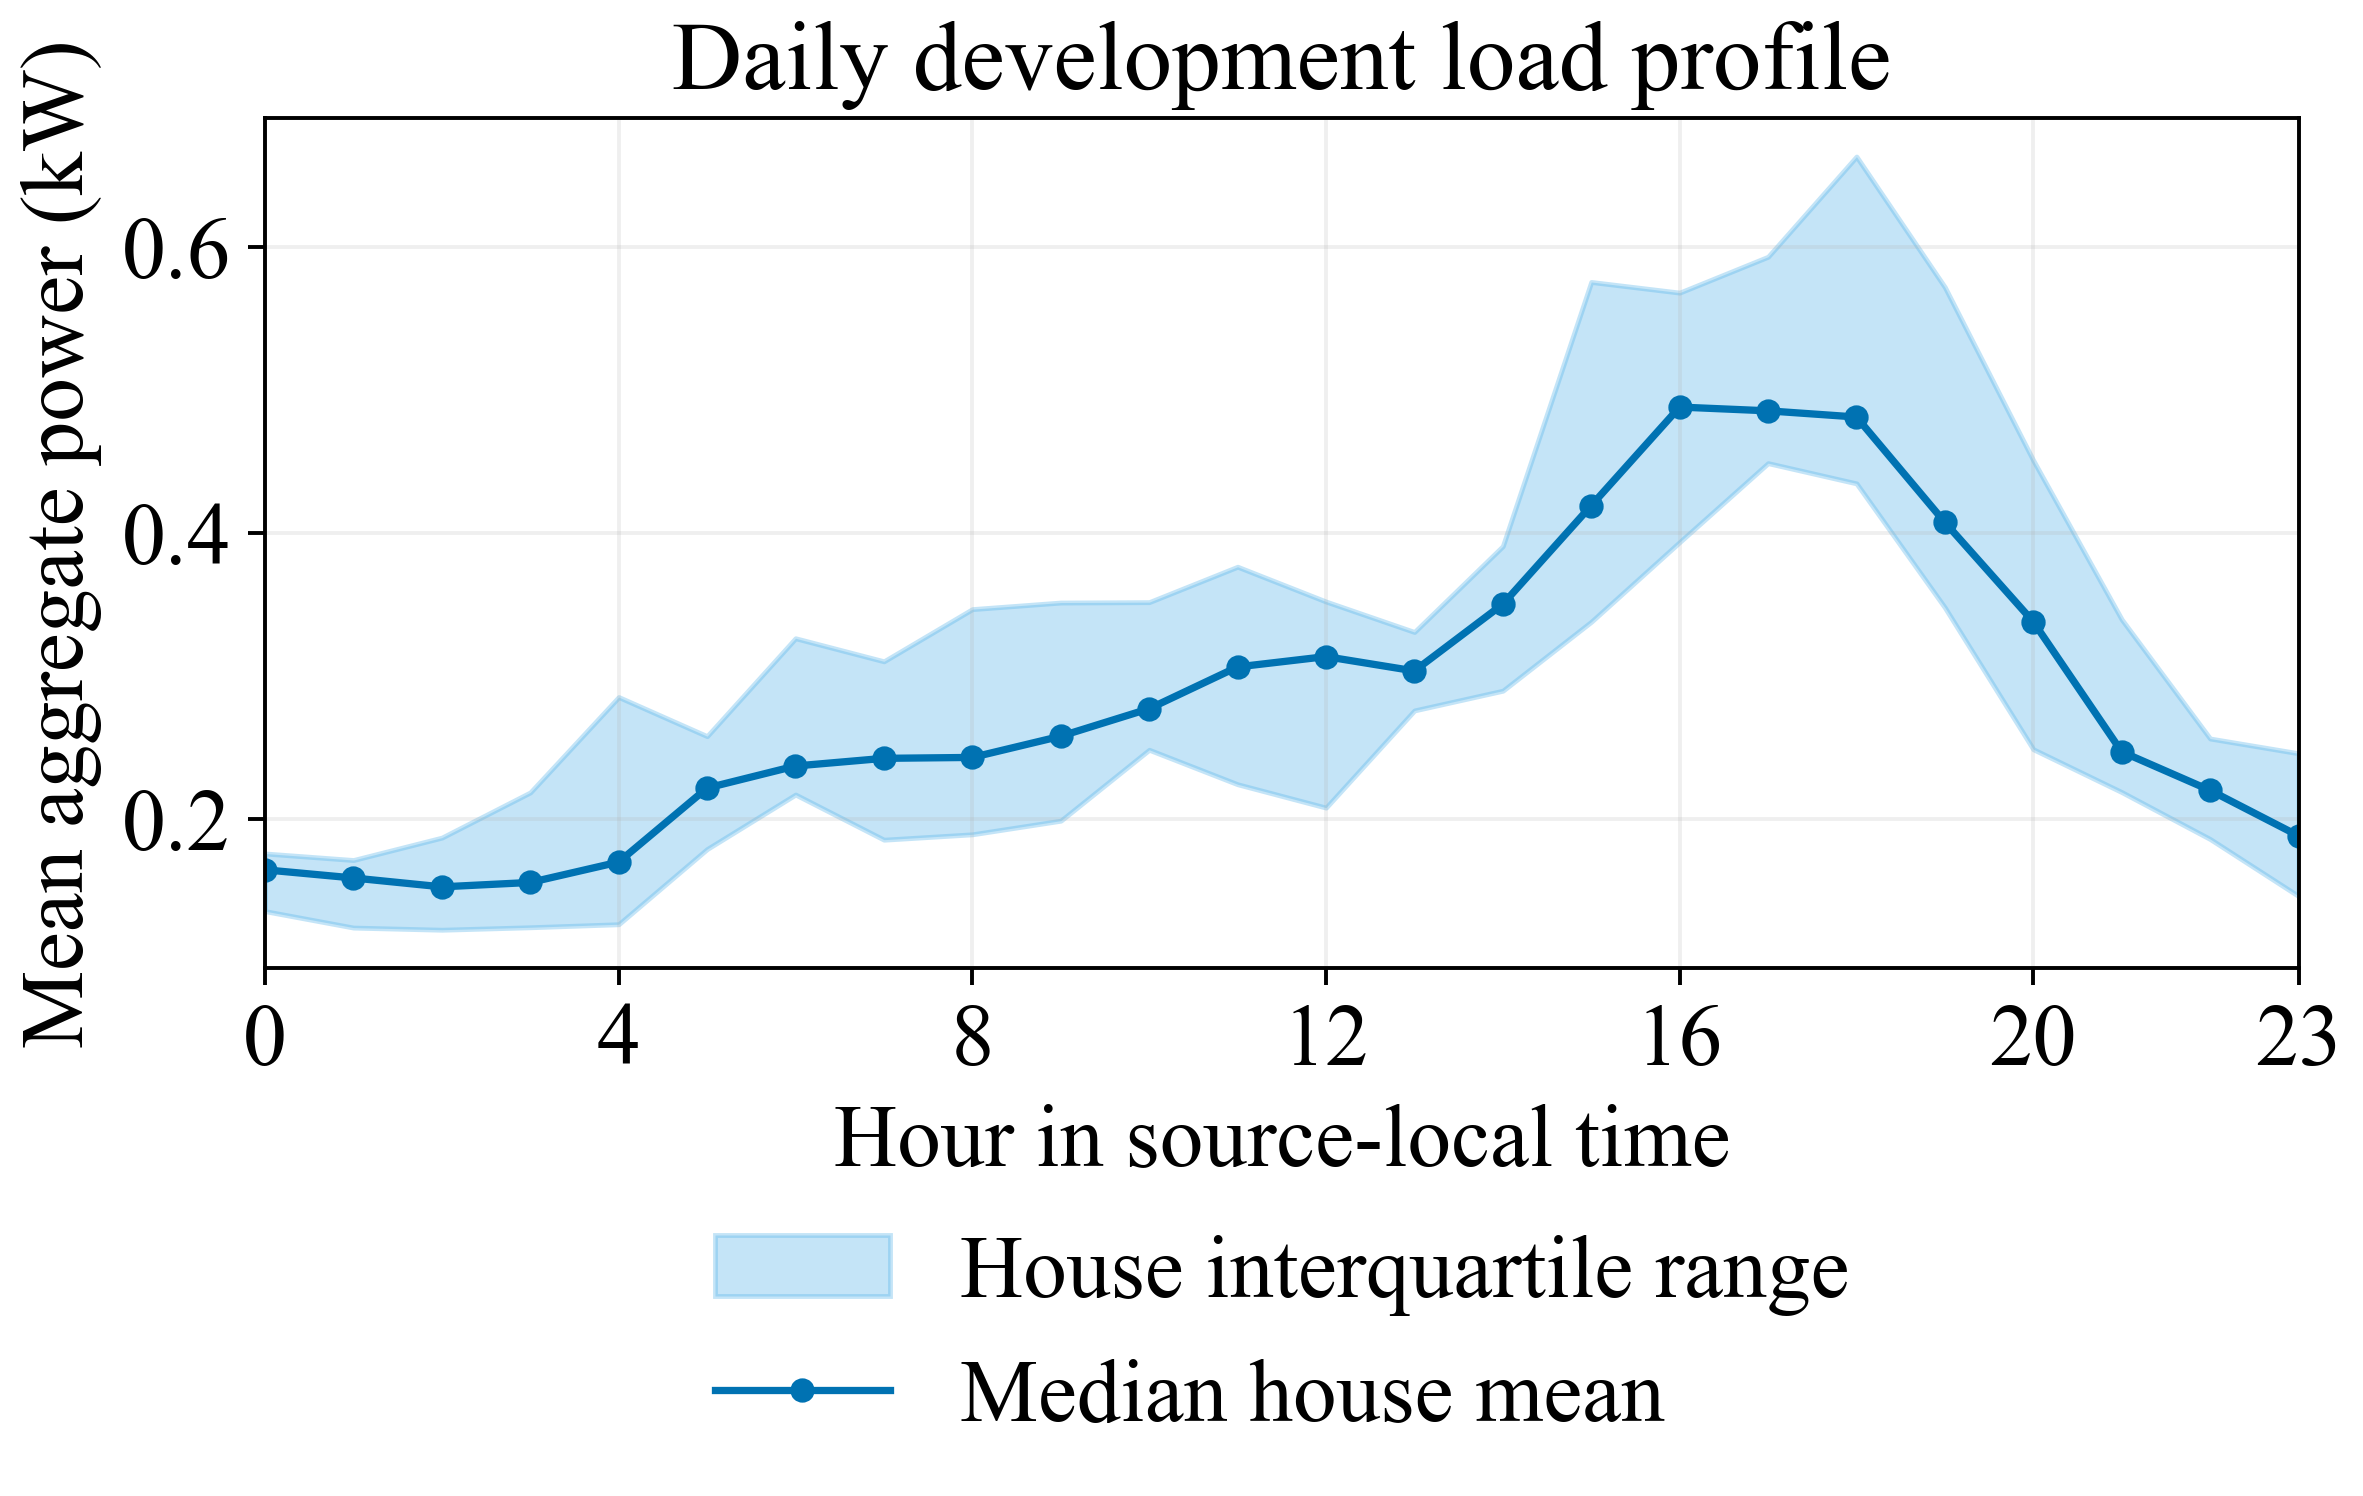

In [41]:
# Equal-house descriptive profiles avoid letting the longest household dominate.
profile_rows = []
for house, info in development.items():
    y = info["values"].loc[info["target_mask"],"P_agg"]
    for hour, sample in y.groupby(y.index.hour):
        profile_rows.append({"House":house,"Hour":hour,"Mean power (kW)":sample.mean(),"n":len(sample)})
hour_profiles = pd.DataFrame(profile_rows)
hour_profiles.to_csv(TABLES / "house_hour_profiles.csv",index=False)
profile = hour_profiles.groupby("Hour")["Mean power (kW)"].agg(
    median="median",q25=lambda s:s.quantile(.25),q75=lambda s:s.quantile(.75))
fig, ax = plt.subplots(figsize=(7.0,4.5))
ax.fill_between(profile.index,profile.q25,profile.q75,color="#56B4E9",alpha=.35,label="House interquartile range")
ax.plot(profile.index,profile["median"],color="#0072B2",marker="o",markersize=4,label="Median house mean")
ax.set_xticks([0,4,8,12,16,20,23])
ax.set_xlim(0,23)
ax.set_xlabel("Hour in source-local time")
ax.set_ylabel("Mean aggregate power (kW)")
ax.set_title("Daily development load profile")
ax.grid(alpha=.2)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),frameon=False,ncol=1)
fig.subplots_adjust(left=.15,right=.98,top=.88,bottom=.34)
save_figure(fig,"06_daily_load_profile")

**Interpretation.** Daily profiles are descriptive mixtures of the observed seasons and household occupancy. The across-house interquartile band describes heterogeneity, not confidence in a population average. Clock hour follows source-local timestamps; the files do not establish a timezone-aware DST correction.

Weekday,median,q25,q75
Monday,0.2832,0.2672,0.3159
Tuesday,0.2931,0.2823,0.3271
Wednesday,0.2767,0.2494,0.3478
Thursday,0.2810,0.2545,0.3204
Friday,0.2870,0.2414,0.3169
Saturday,0.3435,0.2643,0.3625
Sunday,0.2964,0.2787,0.3576


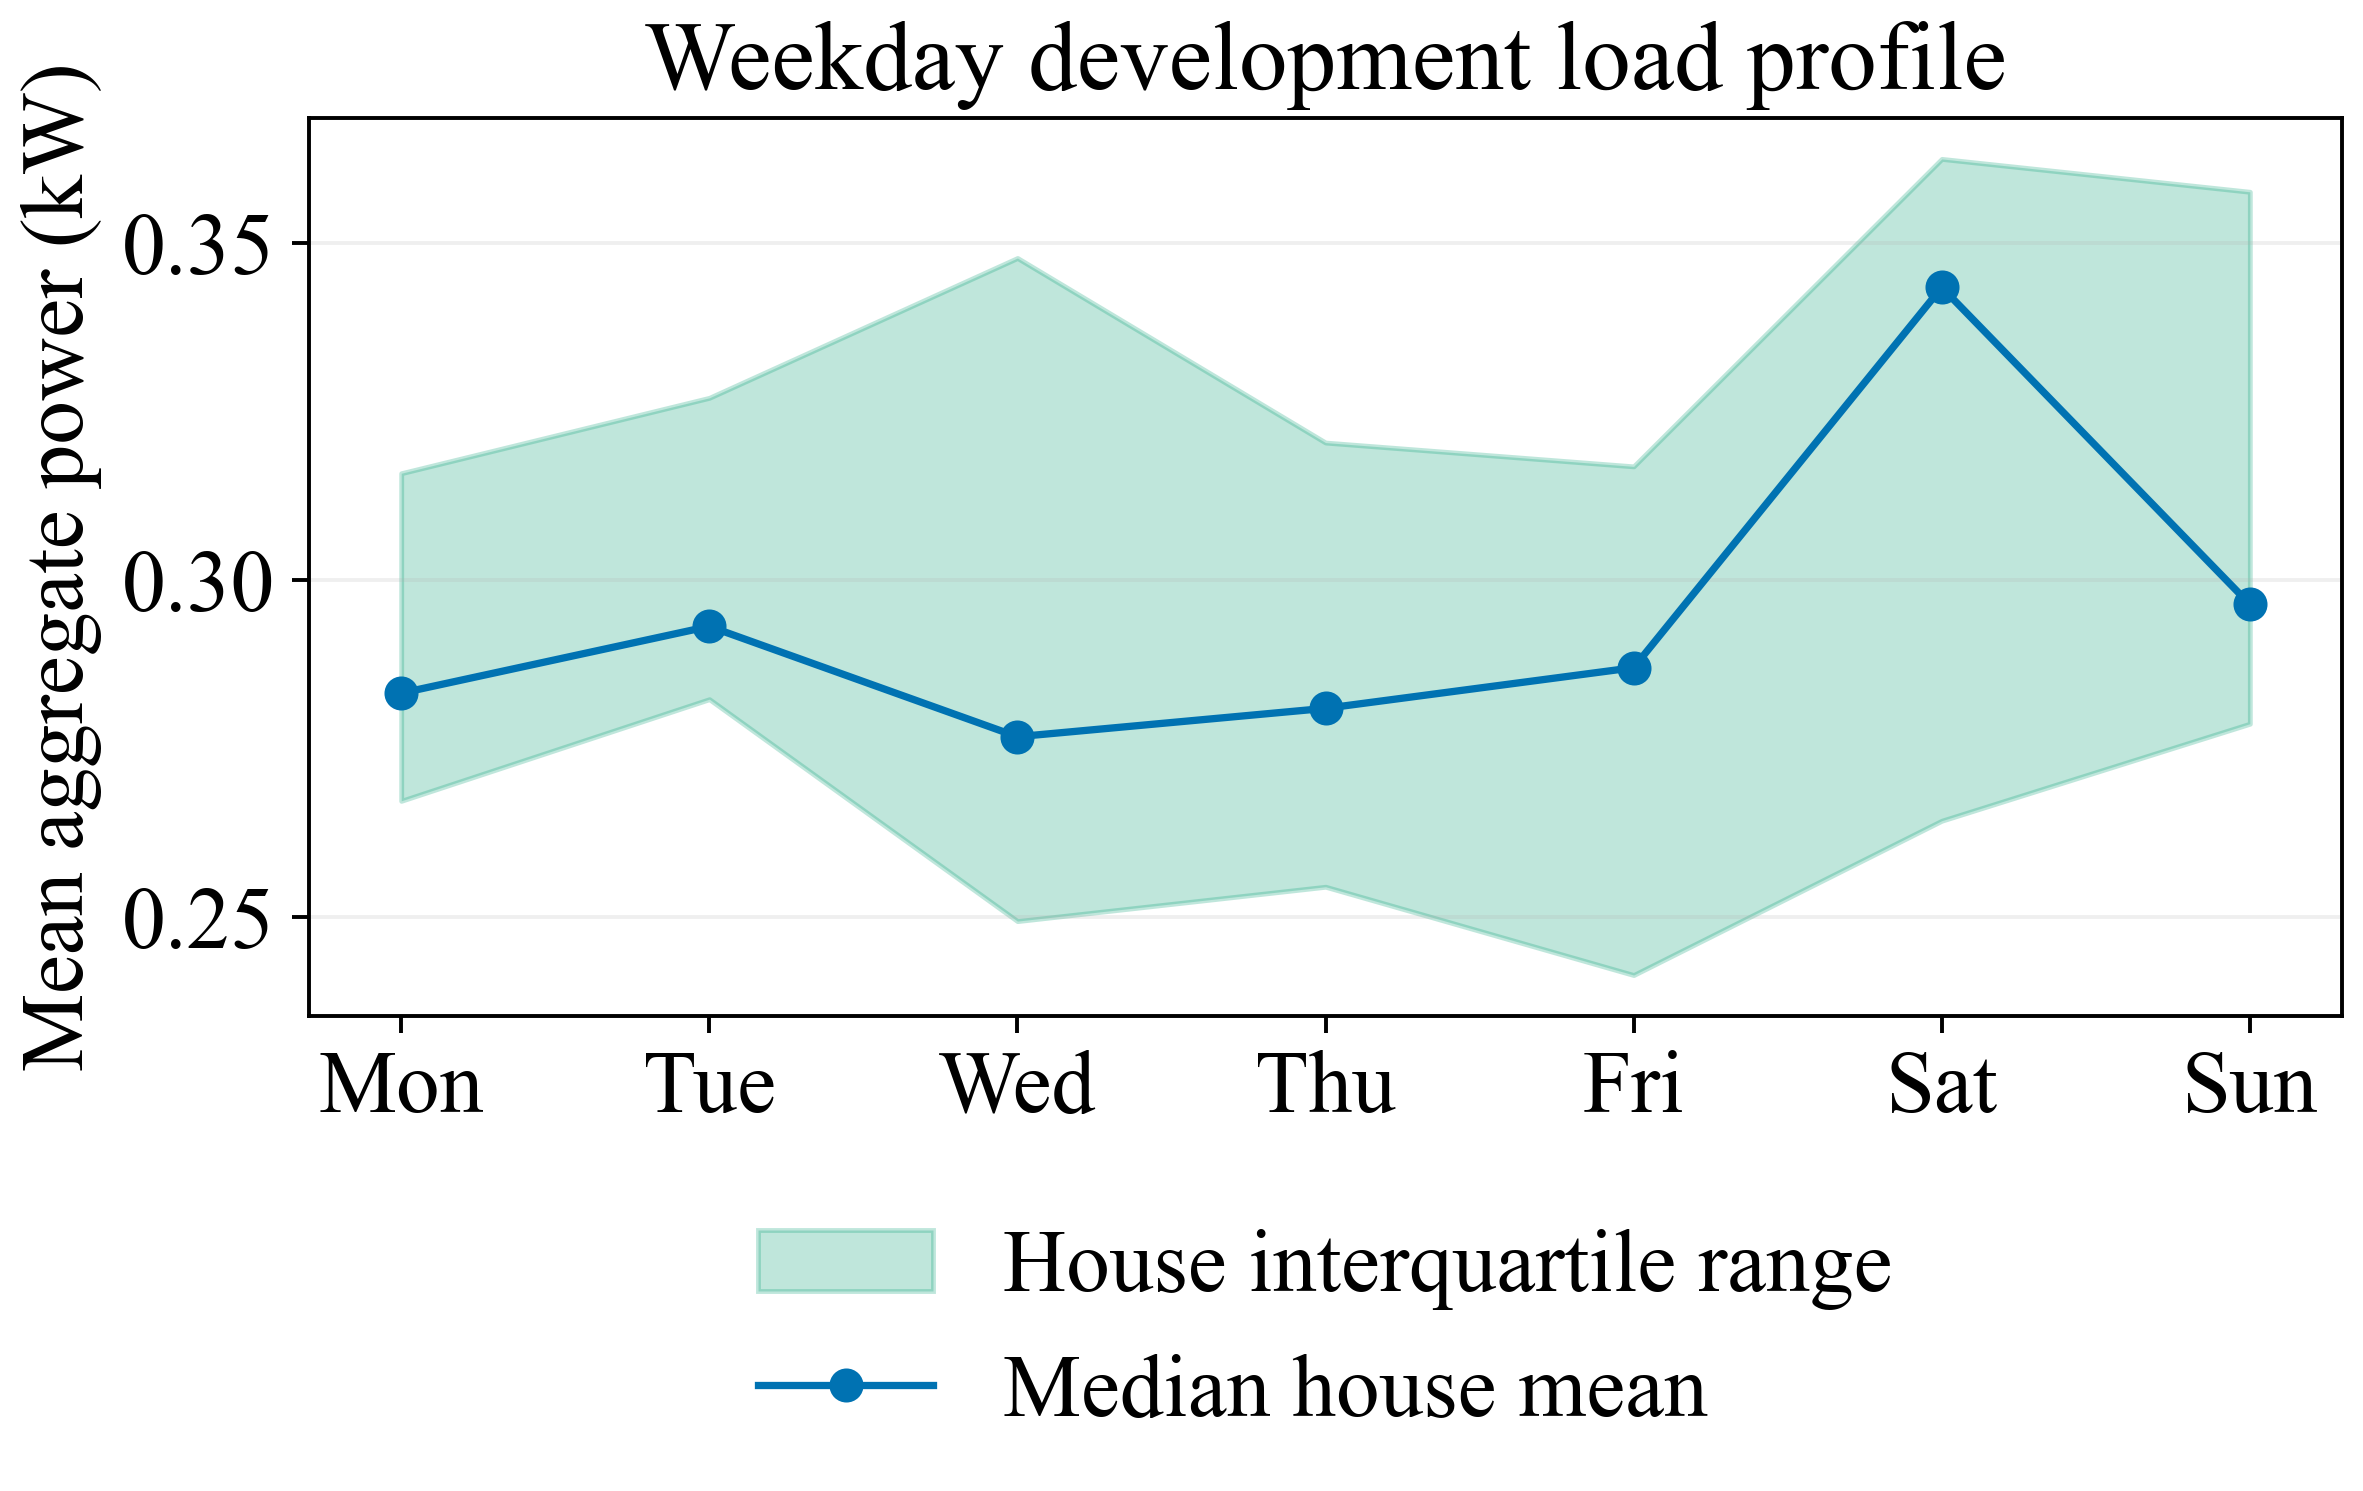

In [42]:
# Weekday profiles use the same equal-house estimand as the hourly profile.
weekday_rows = []
for house, info in development.items():
    y = info["values"].loc[info["target_mask"], "P_agg"]
    for day, sample in y.groupby(y.index.dayofweek):
        weekday_rows.append({"House":house, "Weekday":day, "Mean power (kW)":sample.mean(), "n":len(sample)})
weekday_profiles = pd.DataFrame(weekday_rows)
weekday_profiles.to_csv(TABLES / "house_weekday_profiles.csv", index=False)
weekday = weekday_profiles.groupby("Weekday")["Mean power (kW)"].agg(
    median="median", q25=lambda s:s.quantile(.25), q75=lambda s:s.quantile(.75))
table(weekday.reset_index().assign(Weekday=lambda x:x.Weekday.map(dict(enumerate(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])))),
      "weekday_profile_summary", "Table 27. Median and interquartile range of household-specific weekday means (kW).")
fig, ax = plt.subplots(figsize=(7,4.5))
ax.fill_between(weekday.index,weekday.q25,weekday.q75,color="#009E73",alpha=.25,label="House interquartile range")
ax.plot(weekday.index,weekday["median"],color="#0072B2",marker="o",label="Median house mean")
ax.set_xticks(range(7),labels=["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_ylabel("Mean aggregate power (kW)")
ax.set_title("Weekday development load profile")
ax.grid(axis="y",alpha=.2)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.15),frameon=False)
fig.subplots_adjust(left=.15,right=.98,top=.88,bottom=.31)
save_figure(fig,"07_weekday_load_profile")

**Interpretation.** The median household-specific mean is highest on Saturday and lowest on Wednesday in this development sample; exact values are computed above. Overlapping interquartile bands and seasonally unequal records prevent a causal weekday interpretation. Calendar encodings are observable covariates whose predictive value must be tested inside folds.

## 14. Magnitude of negative residuals and coverage sensitivity

A negative residual can arise from sensor error, asynchronous sampling, channel overlap or unresolved semantics; its frequency alone cannot identify the cause. The next table reports magnitudes without filtering the modeling cohort by the target-derived balance. House 8 remains withheld from this diagnostic because two nominal streams are duplicates. The subsequent coverage sensitivity uses a stricter six-bin rule only to describe the impact of measurement coverage; it does not select a threshold using prediction error.

In [43]:
# Negative residual severity is diagnostic only and never determines target eligibility.
negative_rows = []
for house, info in development.items():
    residual = info["residual"]
    negative_w = -1000 * residual[residual.lt(0)]
    negative_rows.append({"House":house,"Negative minutes":len(negative_w) if house not in ambiguous_houses else np.nan,
        "Magnitude median (W)":negative_w.median(),"Magnitude q95 (W)":negative_w.quantile(.95),
        "Magnitude maximum (W)":negative_w.max(),
        "Residual below −10 W (%)":100*residual.lt(-.01).mean(),
        "Residual below −100 W (%)":100*residual.lt(-.1).mean()})
negative_severity = pd.DataFrame(negative_rows)
table(negative_severity,"negative_residual_severity","Table 28. Negative residual magnitude and frequency of larger discrepancies on complete sets.")

House,Negative minutes,Magnitude median (W),Magnitude q95 (W),Magnitude maximum (W),Residual below −10 W (%),Residual below −100 W (%)
1,1576.0000,7.2505,577.8154,1416.6248,4.1397,1.7917
2,91.0000,62.9885,556.3004,1118.2460,0.1993,0.1196
3,5103.0000,10.5783,43.7040,608.0515,0.9559,0.0546
4,479.0000,43.2590,525.5725,1734.6840,0.2743,0.1065
5,229.0000,498.8002,1039.9833,1428.8940,2.4327,2.2921
6,209.0000,55.8009,325.5760,554.8602,0.0819,0.0475
7,21.0000,47.0915,550.4429,634.5558,0.0167,0.0089
8,Unavailable,Unavailable,Unavailable,Unavailable,Unavailable,Unavailable
9,2033.0000,14.9243,128.4800,1607.8835,1.0130,0.1134
10,104.0000,68.4536,255.4565,424.9788,0.3652,0.1243


**Interpretation.** House 1's negative residuals have a much heavier upper tail than their typical magnitude, and House 5 also has substantial negative discrepancies. The computed magnitude and threshold summaries distinguish these from numerical roundoff. Therefore some discrepancies are substantial, and hard physical equality is an ablation rather than an unquestioned measurement property. These diagnostics do not exclude targets or become inference features.

In [44]:
# A prespecified stricter coverage sensitivity does not replace the primary rule.
coverage_sensitivity_rows = []
for house, info in development.items():
    data = pd.read_parquet(REFINED_DIR / f"plegma_house_{house:02d}.parquet")
    agg = data[data.sensor.eq("P_agg")].set_index("timestamp").reindex(info["ids"].index)
    primary = info["target_mask"]
    strict = primary & agg.observed_10s_bins.ge(6) & agg["count"].ge(6)
    coverage_sensitivity_rows.append({"House":house,"Primary target minutes":int(primary.sum()),
        "Six-bin target minutes":int(strict.sum()),"Retained (%)":100*strict.sum()/primary.sum(),
        "Primary mean (kW)":agg.loc[primary,"mean"].mean(),"Six-bin mean (kW)":agg.loc[strict,"mean"].mean()})
coverage_sensitivity = pd.DataFrame(coverage_sensitivity_rows)
table(coverage_sensitivity,"coverage_rule_sensitivity","Table 29. Descriptive sensitivity to requiring observations in every ten-second bin.")

House,Primary target minutes,Six-bin target minutes,Retained (%),Primary mean (kW),Six-bin mean (kW)
1,438243,434827,99.2205,0.2699,0.2692
2,206516,202461,98.0365,0.2998,0.2998
3,440000,433680,98.5636,0.2846,0.2843
4,347843,318246,91.4913,0.3374,0.3347
5,259127,248267,95.8090,0.5596,0.5532
6,173554,161595,93.1093,0.3051,0.3051
7,308641,249299,80.7731,0.2733,0.2771
8,209110,195257,93.3753,0.2653,0.2641
9,234501,228567,97.4695,0.2015,0.2002
10,130043,95704,73.5941,0.3995,0.4071


**Interpretation.** Requiring all six ten-second bins removes different fractions of the primary targets across houses. House 10 loses the largest fraction and its retained target mean increases, as shown in the sensitivity table. Measurement coverage therefore affects sample composition. The primary five-bin rule remains fixed; this sensitivity does not use validation performance to choose eligibility.

## 15. Canonical vocabulary and summary

The vocabulary includes prespecified types absent from this release. A zero metadata count is structural absence, not an observed zero value. Device identifiers locate streams within a house but cannot become transferable learned house or channel-index embeddings. The next notebook must learn preprocessing, duplicate handling and mask distributions within each training partition and verify invariance to hidden current targets and future perturbations.

In [45]:
# Fix a metadata-only vocabulary, including types unseen in this release.
canonical_power_types = ["aggregate","refrigerator/freezer","washing_machine","dishwasher","kettle",
    "microwave","cooker/oven","water_heater","HVAC/air_conditioner","television/entertainment",
    "computer","lighting","dehumidifier","miscellaneous","unknown"]
canonical_context_types = ["indoor_temperature","indoor_humidity"]
canonical_schema = {"version":"1.0","power_types":canonical_power_types,"context_types":canonical_context_types,
    "unresolved_type":"unknown","forbidden_current_channels":["P_agg","A","V"],
    "forbidden_features":["current_target_coverage","current_target_validity","monitored_fraction","residual_load"],
    "history_end":"strictly_before_current_minute","learned_house_id":False,"learned_channel_index":False}
(ROOT / "Configs/sensor_schema.json").write_text(json.dumps(canonical_schema,indent=2)+"\n")
counts = semantic_map.groupby("canonical_type").size()
schema_table = pd.DataFrame({"Canonical type":canonical_power_types+canonical_context_types})
schema_table["Metadata channels"] = schema_table["Canonical type"].map(counts).fillna(0).astype(int)
table(schema_table,"canonical_sensor_schema","Table 30. Prespecified canonical vocabulary and metadata channel counts across all 13 houses.",precision=0)

# Verify that raw audit products contain development values only and original split IDs remain unchanged.
freeze = json.loads((ROOT / "Manifests/split_freeze.json").read_text())
for relative, expected_hash in freeze["files"].items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected_hash
for house, info in development.items():
    assert info["ids"].split.eq("development").all()
    assert info["ids"].index.is_monotonic_increasing and info["ids"].index.is_unique
    assert not {"V","A"}.intersection(info["values"].columns)
    assert info["values"].index.equals(info["ids"].index)
    assert not (info["target_mask"] & info["ids"].context_only).any()
    assert info["values"].loc[info["target_mask"],"P_agg"].notna().all()
    assert (info["ids"].index.to_series().diff().dropna() == pd.Timedelta(minutes=1)).all()
assert len(final_folds) == 30 and len(figure_qa) == 7
pd.DataFrame(figure_qa).to_csv(ROOT / "Manifests/nb01_figure_qa.csv",index=False)
quality_gate = {"notebook":"01_dataset_analysis_and_research_design.ipynb",
    "status":"primary_development_data_adequate_for_nb02","quality_version":"instrument_range_v2",
    "eligible_development_targets":int(final_targets["Target minutes"].sum()),"house_fold_partitions":len(final_folds),
    "protected_target_values_accessed":False,"fitted_models":0,
    "pending":["NB02 feature perturbation and fold-local preprocessing tests","REFIT endpoint qualification / external dataset decision"],
    "refined_files":{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
                     for p in sorted(REFINED_DIR.glob("plegma_house_*.parquet"))}}
(ROOT / "Manifests/nb01_gate.json").write_text(json.dumps(quality_gate,indent=2)+"\n");

Canonical type,Metadata channels
aggregate,13
refrigerator/freezer,14
washing_machine,13
dishwasher,4
kettle,1
microwave,0
cooker/oven,0
water_heater,12
HVAC/air_conditioner,18
television/entertainment,0


**Conclusion and limitations.** Plegma development data are adequate to proceed to fold-safe feature construction: every required household and house-by-fold role retains eligible targets, with full support counts computed above. Quality states, instrument envelopes, timestamp failures, sensor duplication and coverage sensitivity are explicit. Fixed splits and development-only minute artifacts enforce the data boundary; functional feature causality is still to be tested in Notebook 02. No models have been fitted. Locked Plegma and REFIT target distributions remain unopened. Because of REFIT's fixed-voltage instrumentation and collection-time filling, it cannot be treated as an unqualified validation of directly measured active power.

## 16. Extended analysis: prespecified development sensitivity

This extension was added after the initial analysis and is a development-stage sensitivity analysis. It keeps every split and artifact from the preceding sections unchanged. The original target rule remains primary: additional rules are sensitivity strata, never accuracy-driven replacement targets.

This section tests stricter temporal coverage and instrument limits, delays in auxiliary telemetry, incomplete sensor sets and the known House 8 identity ambiguity. No model is fitted here. Correlations using a future offset are explicitly descriptive clock-sensitivity diagnostics and are prohibited as model inputs. They cannot identify physical clock error in autocorrelated demand. New predictive paths and their leakage tests belong in Notebook 02.

In [1]:
# Independent extension setup: immutable historical inputs, separate output namespace.
from pathlib import Path
import hashlib, json, os, gc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text
from IPython.display import display, Image, Markdown, clear_output
from PIL import Image as PILImage
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
V2_RUN="guldana_n3_20261009_v02"
V2_RECORD=ROOT/"Manifests/Runs"/V2_RUN
V2_TABLES=ROOT/"Tables"/V2_RUN/"01_data_sensitivity"
V2_DATA=ROOT/"Data/Processed"/V2_RUN/"data_sensitivity"
for folder in [V2_TABLES,V2_DATA,ROOT/"Figures/PNG"/V2_RUN,ROOT/"Figures/PDF"/V2_RUN]:folder.mkdir(parents=True,exist_ok=True)
def v2_sha(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()
V2_PROTOCOL=json.loads((ROOT/"Configs/strengthening_v2.json").read_text())
V2_OLD_LOCK=json.loads((V2_RECORD/"historical_artifact_lock.json").read_text())
V2_SPLIT=json.loads((ROOT/"Manifests/split_freeze.json").read_text())
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest,relative
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6
font=font_manager.findfont("Times New Roman",fallback_to_default=False)
assert Path(font).is_file()
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,
    "axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
    "figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
def v2_table(frame,name,caption,precision=4):
    frame.to_csv(V2_TABLES/f"{name}.csv",index=False)
    frame.to_latex(V2_TABLES/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.{precision}f}")
    display(frame.style.format(precision=precision,na_rep="Not identifiable").hide(axis="index").set_caption(caption))
def v2_figure(fig,name):
    fig.canvas.draw()
    for text in fig.findobj(Text):
        if text.get_visible() and text.get_text().strip():
            assert 18<=text.get_fontsize()<=20
            assert font_manager.FontProperties(fname=font_manager.findfont(text.get_fontproperties(),fallback_to_default=False)).get_name()=="Times New Roman"
    png=ROOT/"Figures/PNG"/V2_RUN/f"{name}.png";pdf=ROOT/"Figures/PDF"/V2_RUN/f"{name}.pdf"
    fig.savefig(png,dpi=350,bbox_inches="tight",pad_inches=.06)
    fig.savefig(pdf,dpi=350,bbox_inches="tight",pad_inches=.06)
    with PILImage.open(png) as im:assert all(abs(d-350)<.02 for d in im.info["dpi"])
    plt.close(fig);display(Image(filename=str(png)))


In [2]:
# Compute sensitivities from original audited development minutes; no repaired or filled targets.
v2_quality_rows=[];v2_sync_rows=[];v2_composition_rows=[];v2_files={}
semantic=pd.read_csv(ROOT/"Data/Interim/sensor_semantic_map.csv")
for house in range(1,11):
    clear_output(wait=True);display(Markdown(f"Development measurement sensitivity: household {house}/10."))
    source=ROOT/f"Data/Interim/development_minutes_refined/plegma_house_{house:02d}.parquet"
    assert v2_sha(source)==V2_OLD_LOCK["files"][str(source.relative_to(ROOT))]
    data=pd.read_parquet(source)
    ids=pd.read_parquet(ROOT/f"Manifests/observation_ids/plegma_house_{house:02d}.parquet")
    ids=ids.loc[ids.split.eq("development")].set_index("timestamp")
    assert set(data.timestamp).issubset(set(ids.index))
    values=data.pivot(index="timestamp",columns="sensor",values="mean").reindex(ids.index)
    available=data.pivot(index="timestamp",columns="sensor",values="available").reindex(ids.index).fillna(False).astype(bool)
    values=values.where(available)  # Invalid auxiliary minutes never count as observed.
    agg=data.loc[data.sensor.eq("P_agg")].set_index("timestamp").reindex(ids.index)
    primary=available.P_agg & ~ids.context_only
    masks={"Primary":primary,"Six bins":primary & agg.observed_10s_bins.ge(6) & agg["count"].ge(6),
        "Maximum gap 10 s":primary & agg.max_gap_seconds.le(10),
        "No instrument allowance":primary & agg["max"].le(156.0)}
    aux=semantic.loc[semantic.house.eq(house)&semantic.role.eq("auxiliary_power"),"original_sensor"].tolist()
    assert all(sensor in values for sensor in aux)
    valid=available[aux]
    metadata=ids.loc[primary,["observation_id","house","fold_1","fold_2","fold_3"]].copy()
    metadata["y_kW"]=agg.loc[primary,"mean"]
    for name,mask in masks.items():metadata[name]=mask.loc[primary]
    metadata["Available nominal auxiliaries"]=valid.loc[primary].sum(axis=1)
    metadata["Nominal auxiliary count"]=len(aux)
    metadata["Ambiguous physical composition"]=house==8
    metadata.reset_index().to_parquet(V2_DATA/f"house_{house:02d}_sensitivity.parquet",index=False)
    v2_files[str((V2_DATA/f"house_{house:02d}_sensitivity.parquet").relative_to(ROOT))]=v2_sha(V2_DATA/f"house_{house:02d}_sensitivity.parquet")
    for fold in [1,2,3]:
        for role in ["train","inner_validation","outer_validation"]:
            role_mask=ids[f"fold_{fold}"].eq(role)
            for name,mask in masks.items():
                keep=role_mask&mask;target=agg.loc[keep,"mean"]
                v2_quality_rows.append({"House":house,"Fold":fold,"Role":role,"Rule":name,
                    "Eligible minutes":int(keep.sum()),"Primary minutes":int((role_mask&primary).sum()),
                    "Mean target (kW)":float(target.mean()),"Zero target (%)":float(target.eq(0).mean()*100)})
    # Matched finite triples prevent offset-specific support from masquerading as a timing effect.
    for sensor in aux:
        offsets=pd.DataFrame({"Aggregate":values.P_agg,
            **{f"Offset {offset}":values[sensor].shift(-offset) for offset in [-1,0,1]}})
        matched=primary & offsets.notna().all(axis=1)
        for offset in [-1,0,1]:
            part=offsets.loc[matched,["Aggregate",f"Offset {offset}"]]
            rho=part.corr(method="spearman").iloc[0,1] if len(part)>2 else np.nan
            v2_sync_rows.append({"House":house,"Sensor":sensor,"Offset minutes":offset,
                "Matched minutes":len(part),"Spearman correlation":rho,
                "Interpretation":"descriptive only; positive offset is future data and prohibited for prediction"})
    # A completed minute delayed by d minutes is causal; its original availability is retained.
    for lag in [0,1,2]:
        shifted=values[aux].shift(lag);count=shifted.notna().sum(axis=1)
        if house!=8:
            complete=primary & count.eq(len(aux));residual=values.P_agg-shifted.sum(axis=1,min_count=len(aux))
            negative=float(residual.loc[complete].lt(0).mean()*100) if complete.any() else np.nan
            abs_residual=float(residual.loc[complete].abs().mean()) if complete.any() else np.nan
        else:complete=pd.Series(False,index=ids.index);negative=np.nan;abs_residual=np.nan
        v2_composition_rows.append({"House":house,"Auxiliary delay (min)":lag,"Nominal sensors":len(aux),
            "Target minutes":int(primary.sum()),"Mean available sensors":float(count.loc[primary].mean()),
            "No auxiliary (%)":float(count.loc[primary].eq(0).mean()*100),"Complete eligible sets":int(complete.sum()),
            "Negative residual (%)":negative,"Mean absolute residual (kW)":abs_residual,
            "Physical balance identifiable":house!=8})
    del data,values,available,agg,metadata;gc.collect()
v2_quality=pd.DataFrame(v2_quality_rows);v2_sync=pd.DataFrame(v2_sync_rows);v2_composition=pd.DataFrame(v2_composition_rows)
for frame,name in [(v2_quality,"quality_by_house_fold_role"),(v2_sync,"matched_clock_offset_diagnostics"),(v2_composition,"causal_delay_composition")]:
    frame.to_csv(V2_TABLES/f"{name}.csv",index=False)
clear_output(wait=True)
quality_summary=v2_quality.groupby(["Fold","Role","Rule"],sort=False).agg(
    Eligible_minutes=("Eligible minutes","sum"),Primary_minutes=("Primary minutes","sum"),
    Equal_house_mean_kW=("Mean target (kW)","mean")).reset_index()
quality_summary["Retained (%)"]=100*quality_summary.Eligible_minutes/quality_summary.Primary_minutes
v2_table(quality_summary,"quality_sensitivity_summary",
    "Fixed development roles under stricter eligibility rules. Counts overlap across expanding folds; they are not independent observations. No alternative rule replaces the primary target contract.")
assert quality_summary.Eligible_minutes.gt(0).all()



Fold,Role,Rule,Eligible_minutes,Primary_minutes,Equal_house_mean_kW,Retained (%)
1,train,Primary,904525,904525,0.2769,100.0000
1,train,Six bins,843853,904525,0.2765,93.2924
1,train,Maximum gap 10 s,130318,904525,0.2521,14.4073
1,train,No instrument allowance,904525,904525,0.2769,100.0000
1,inner_validation,Primary,162034,162034,0.2898,100.0000
1,inner_validation,Six bins,149554,162034,0.2882,92.2979
1,inner_validation,Maximum gap 10 s,18046,162034,0.2965,11.1372
1,inner_validation,No instrument allowance,162034,162034,0.2898,100.0000
1,outer_validation,Primary,556333,556333,0.3495,100.0000
1,outer_validation,Six bins,521585,556333,0.3465,93.7541


**Reading guide.** Compare retention and target composition within each fixed fold/role. Coverage sensitivity is a selection-effect diagnostic, not evidence that discarded values should be reinstated. Offset correlations are matched for support and must not be used to choose a future-looking feature.


In [3]:
# Compact physical-composition sensitivity and clock-offset diagnostic summaries.
v2_table(v2_composition.loc[v2_composition["Auxiliary delay (min)"].eq(0)].drop(columns="Auxiliary delay (min)"),
    "composition_sensitivity_summary","Actual current auxiliary support. House 8 balance is not identifiable from the conflicting physical labels; unavailable values are not zeros.")
clock_summary=v2_sync.groupby(["House","Offset minutes"],as_index=False).agg(
    Median_sensor_Spearman=("Spearman correlation","median"),Minimum_matched_minutes=("Matched minutes","min"))
clock_summary.to_csv(V2_TABLES/"clock_offset_summary.csv",index=False)


House,Nominal sensors,Target minutes,Mean available sensors,No auxiliary (%),Complete eligible sets,Negative residual (%),Mean absolute residual (kW),Physical balance identifiable
1,5,438243,3.9414,0.0062,15460,10.1940,0.0614,True
2,5,206516,3.7604,0.0097,35130,0.2590,0.0925,True
3,5,440000,4.4624,0.0477,285701,1.7861,0.1226,True
4,5,347843,3.9918,0.5534,138906,0.3448,0.1234,True
5,5,259127,3.0893,0.0185,9249,2.4759,0.5354,True
6,3,173554,2.9713,0.0000,168584,0.1240,0.1512,True
7,5,308641,3.8433,1.9259,89907,0.0234,0.2251,True
8,4,209110,3.6668,0.2133,0,Not identifiable,Not identifiable,False
9,3,234501,2.3553,3.6644,130508,1.5578,0.0960,True
10,6,130043,4.3499,0.0715,25738,0.4041,0.1677,True


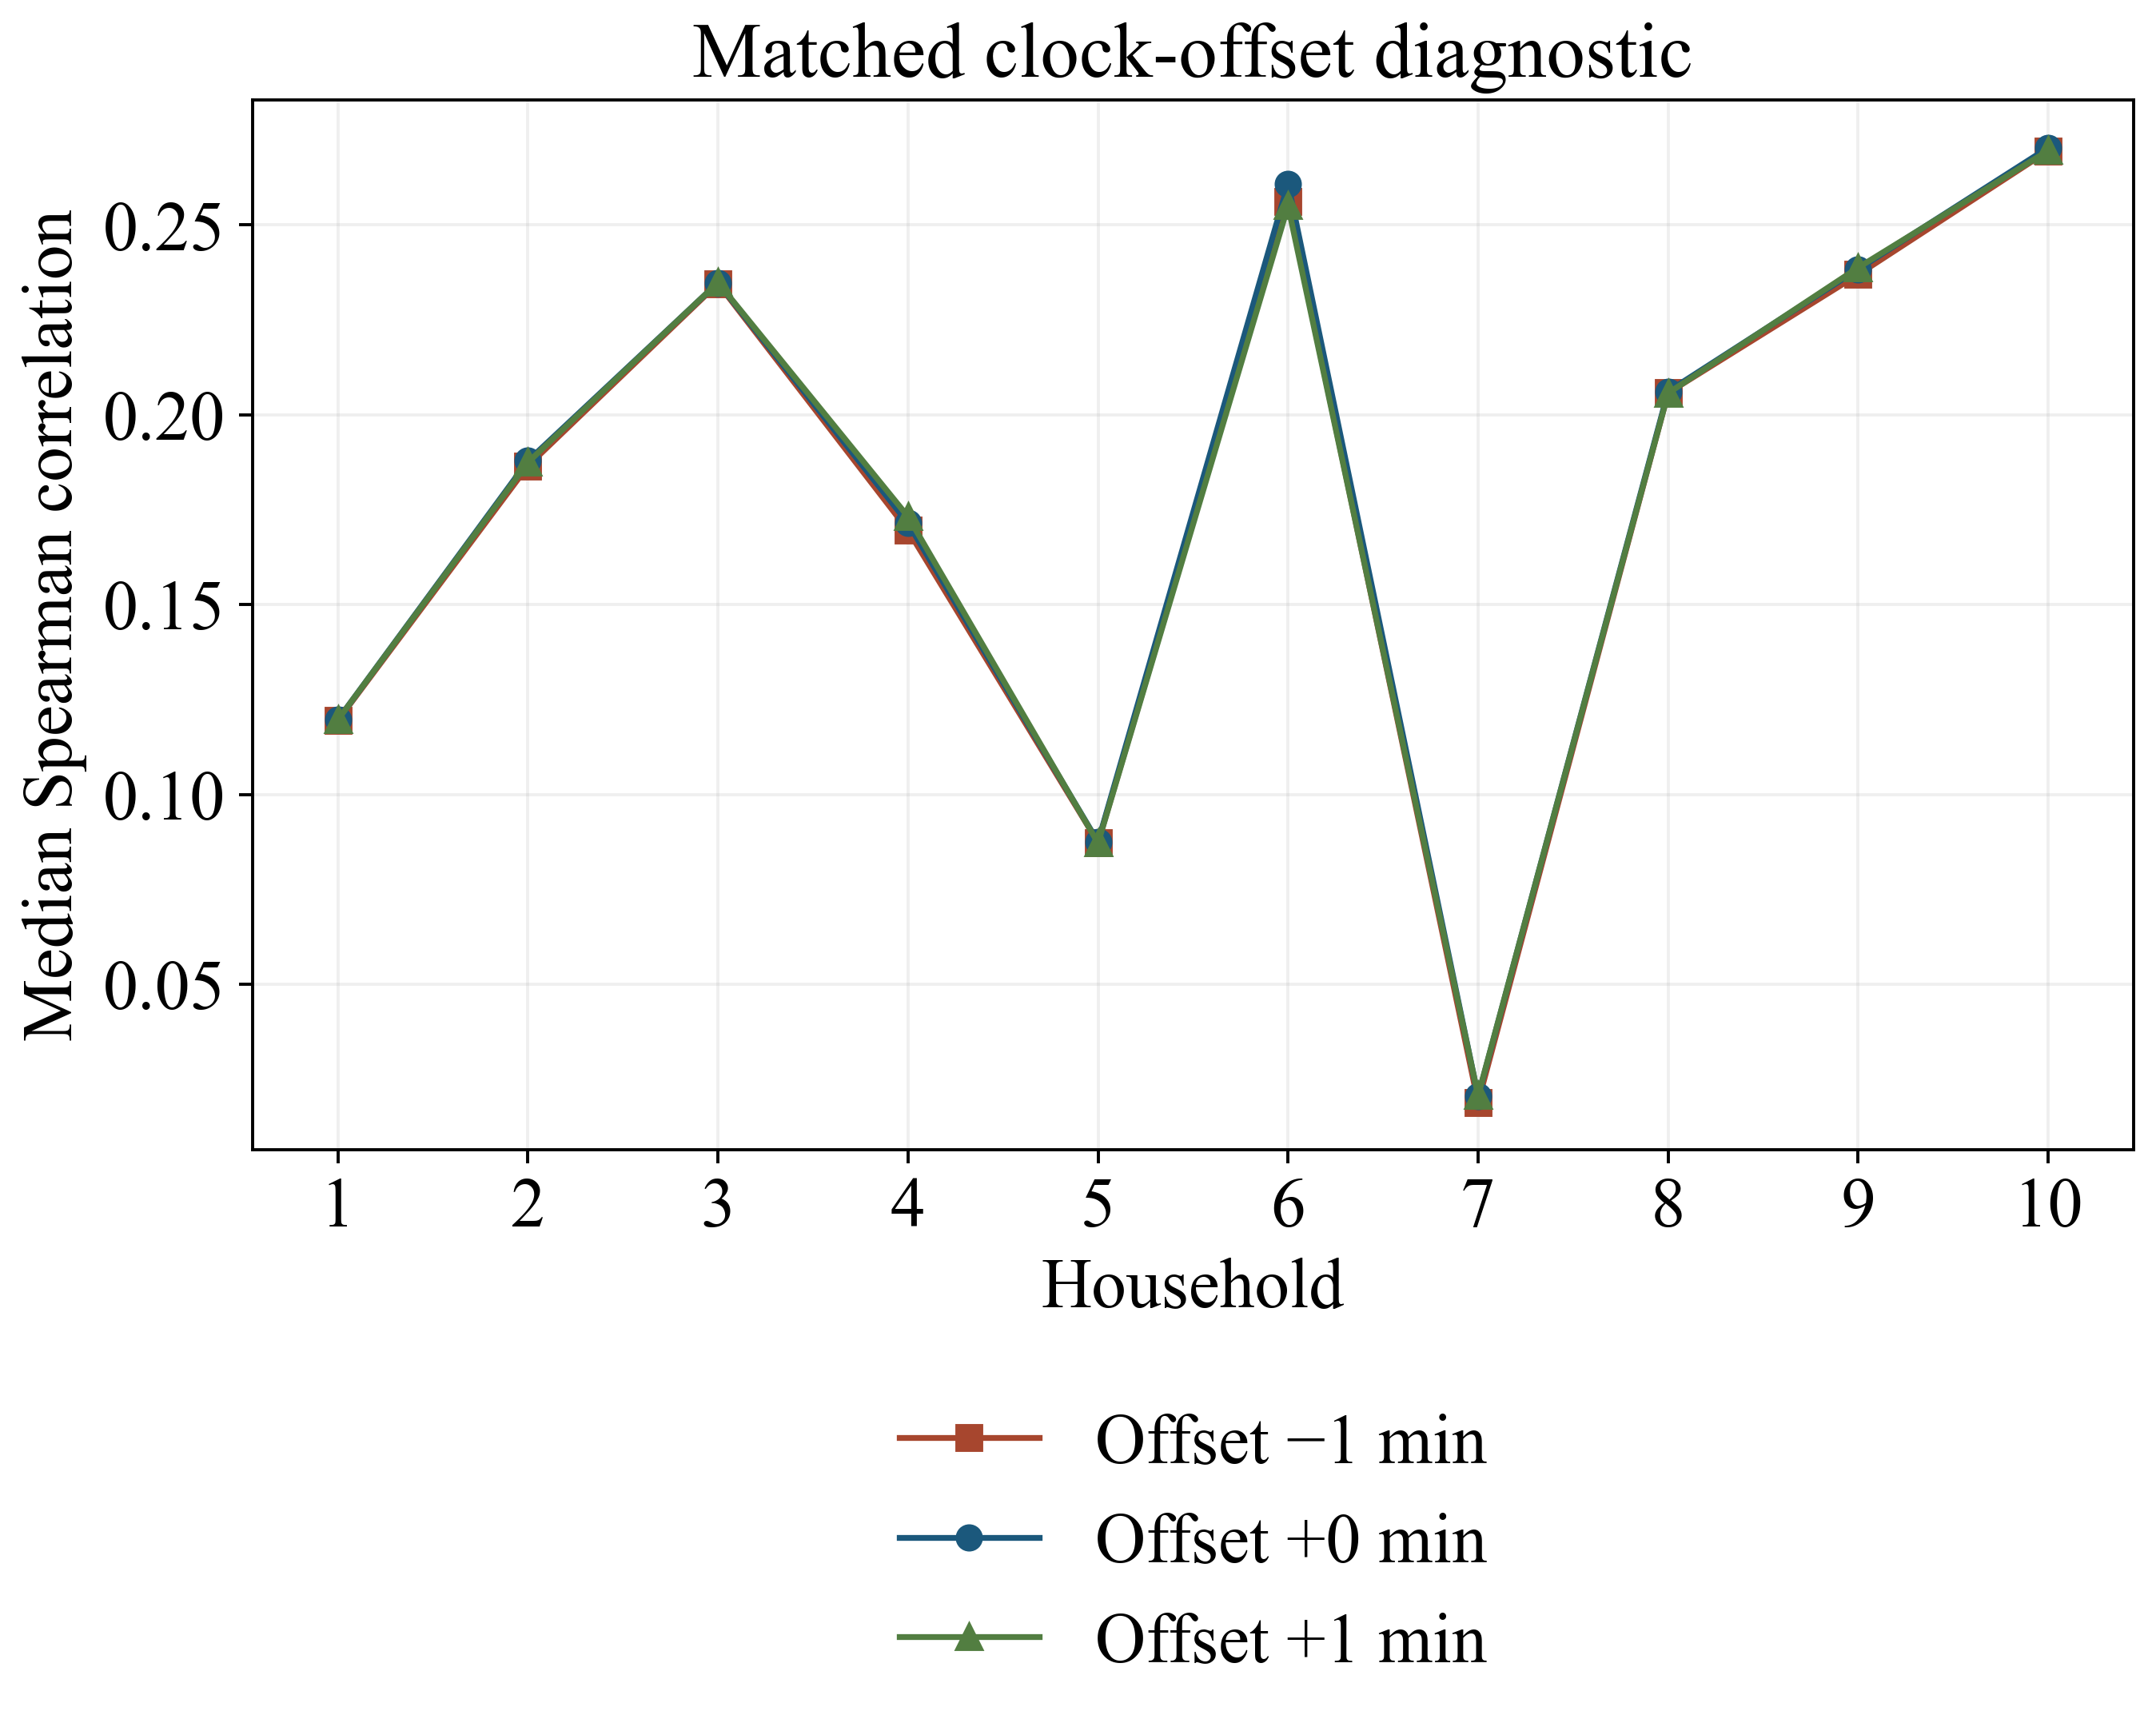

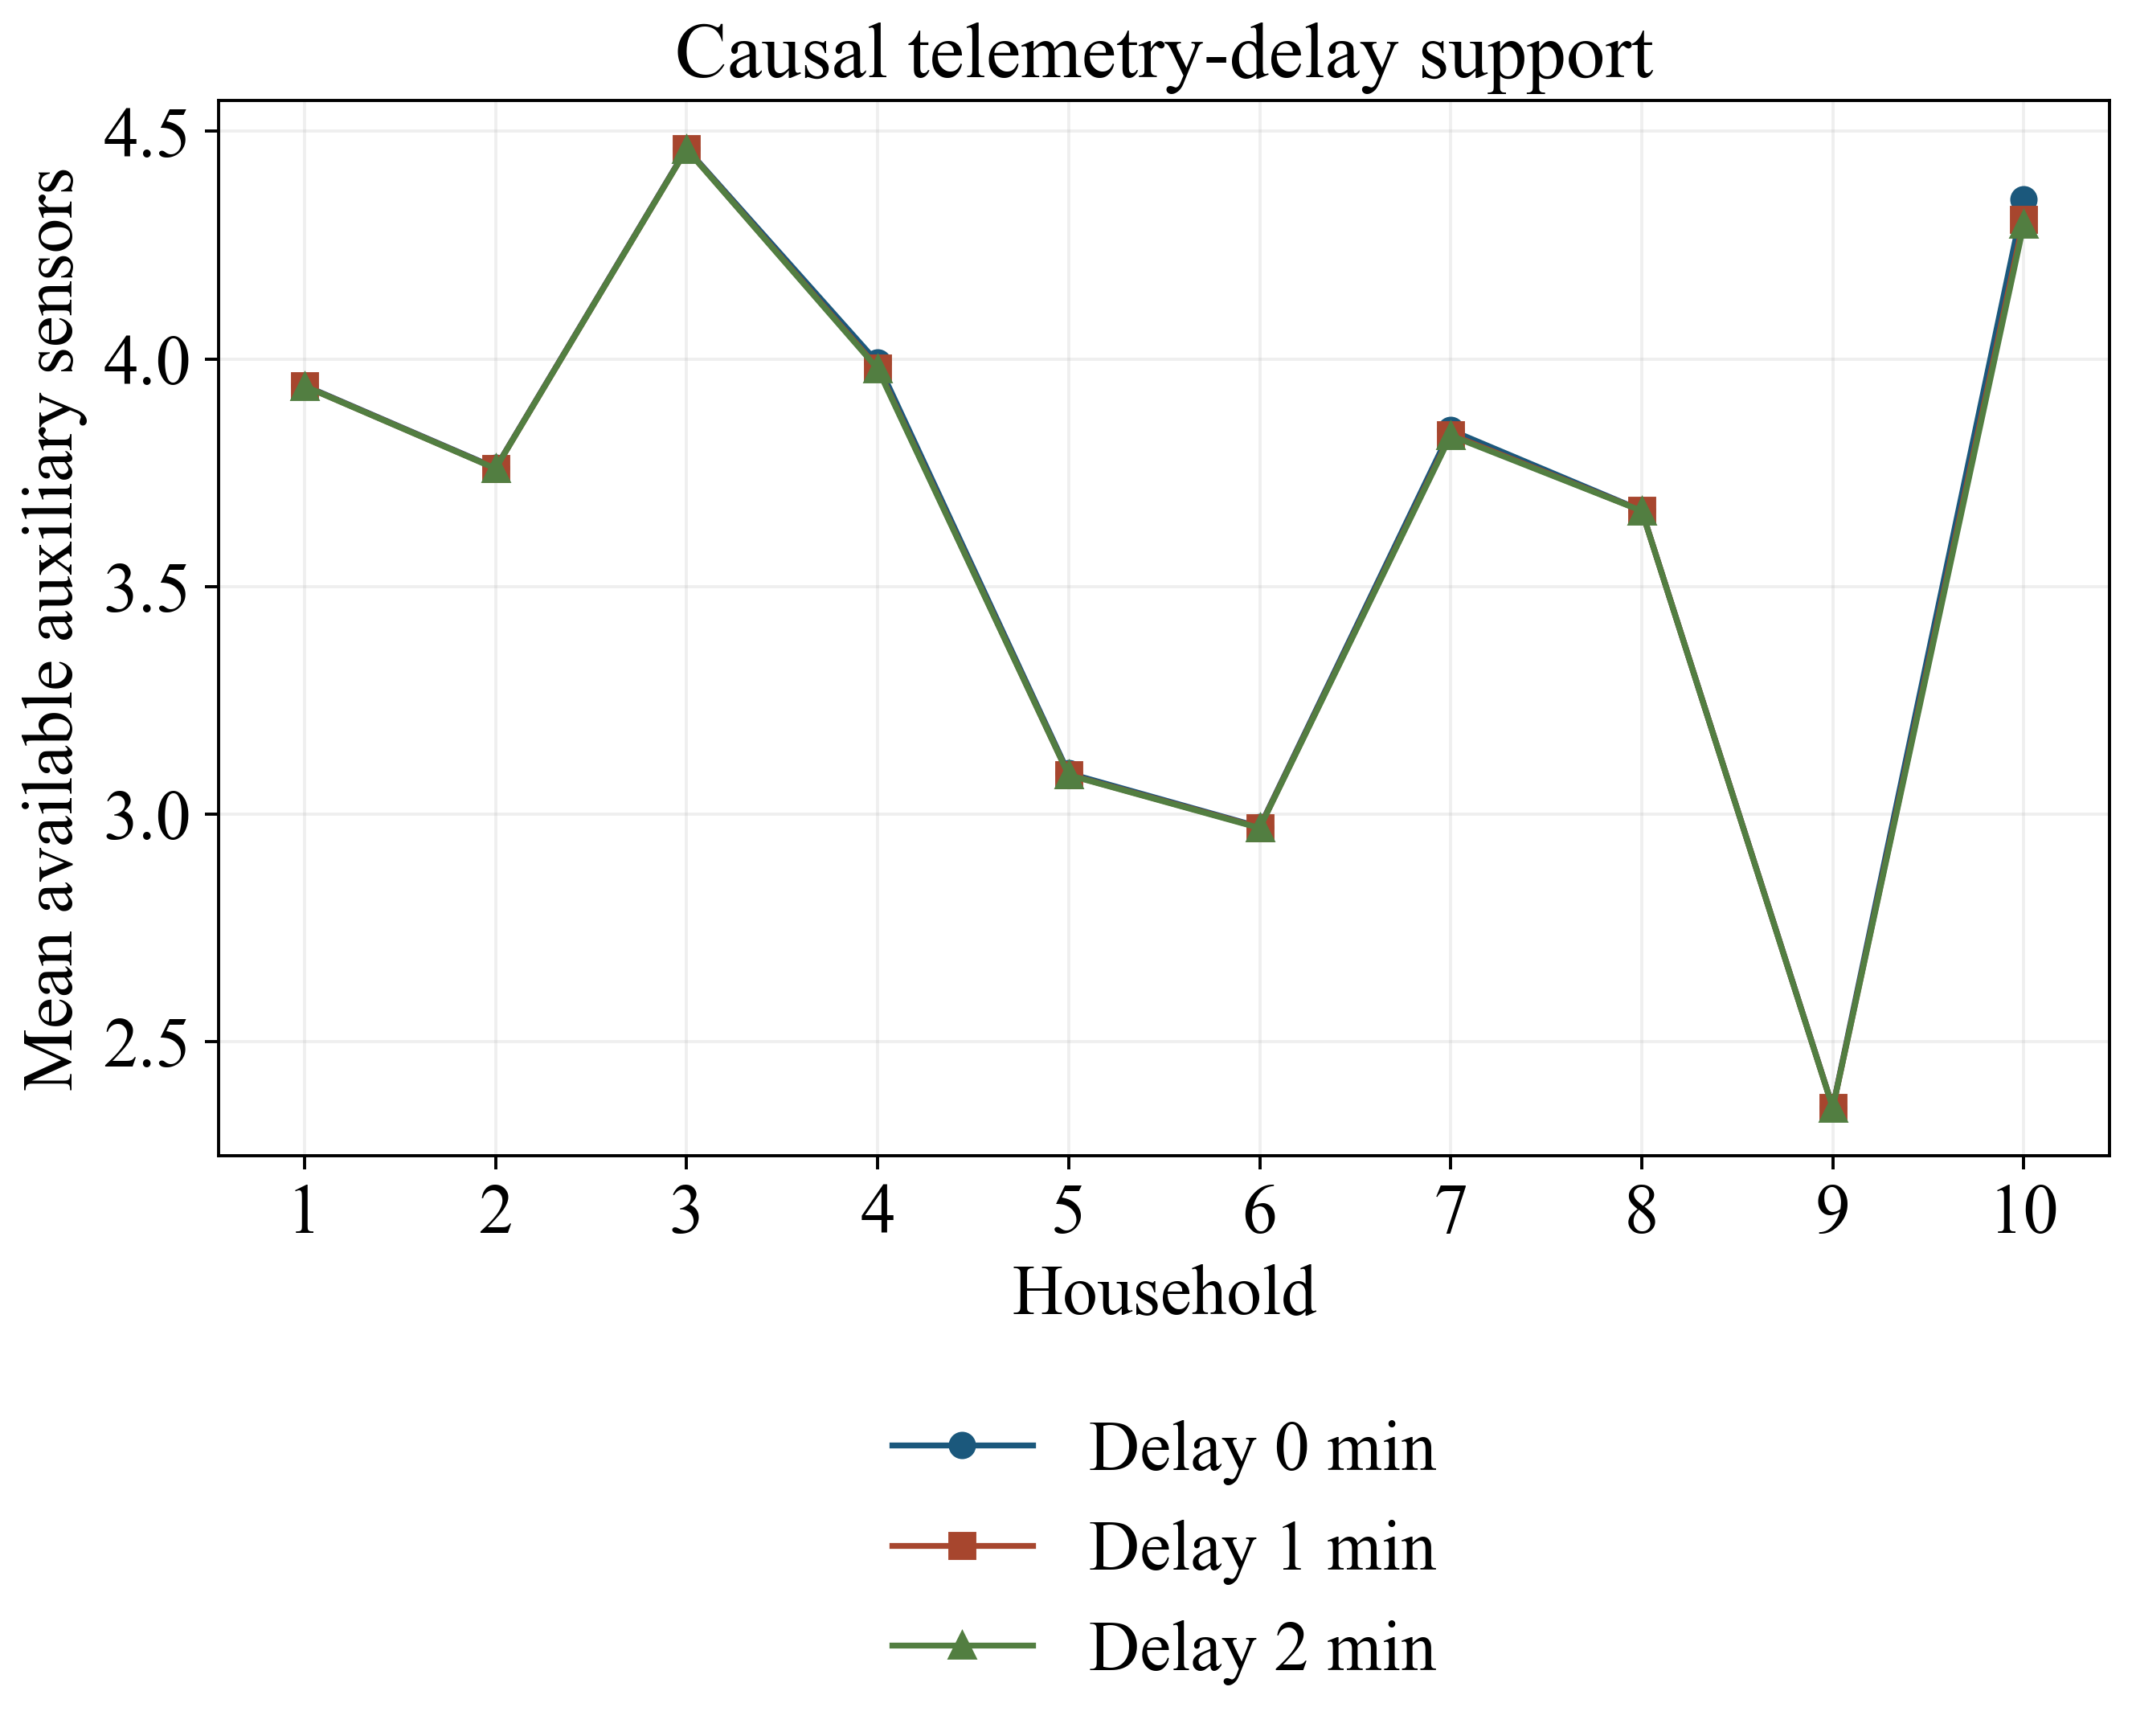

In [1]:
def render_presentation_nb01_composition():
    # Presentation only: exact saved summaries; no fitting or per-query metric calculation.
    from pathlib import Path
    import hashlib
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    from matplotlib.text import Text
    from IPython.display import display, Image, Markdown, HTML
    from PIL import Image as PILImage
    ROOT = Path.cwd()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    PRESENTATION_RUN = "guldana_n3_20261011_presentation"
    _font = font_manager.findfont("Times New Roman", fallback_to_default=False)
    assert Path(_font).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42})
    def read_presentation_csv(relative):
        path = ROOT / relative
        assert hashlib.sha256(path.read_bytes()).hexdigest() == INPUT_SHA256[relative], relative
        return pd.read_csv(path)
    def save_presentation(fig, name):
        fig.canvas.draw()
        for item in fig.findobj(Text):
            if item.get_visible() and item.get_text().strip():
                assert 18 <= item.get_fontsize() <= 20
                actual = font_manager.FontProperties(fname=font_manager.findfont(item.get_fontproperties(), fallback_to_default=False)).get_name()
                assert actual == "Times New Roman"
        for kind in ["PNG", "PDF"]:
            directory = ROOT / "Figures" / kind / PRESENTATION_RUN
            directory.mkdir(parents=True, exist_ok=True)
            fig.savefig(directory / (name + "." + kind.lower()), dpi=350, bbox_inches="tight", pad_inches=.08)
        png = ROOT / "Figures/PNG" / PRESENTATION_RUN / (name + ".png")
        with PILImage.open(png) as raster:
            assert all(abs(value - 350) < .02 for value in raster.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    INPUT_SHA256 = {'Tables/guldana_n3_20261009_v02/01_data_sensitivity/clock_offset_summary.csv': 'afe5b09f9e630c96f1e40e46e077bf2909c9ebcabbeccae140606e319ac8b56f', 'Tables/guldana_n3_20261009_v02/01_data_sensitivity/causal_delay_composition.csv': '506d549293e1fd383b3b2faee25f0ffe49a1863a9c49c2edb86c55f7c44c19fc'}

    clock = read_presentation_csv("Tables/guldana_n3_20261009_v02/01_data_sensitivity/clock_offset_summary.csv")
    delays = read_presentation_csv("Tables/guldana_n3_20261009_v02/01_data_sensitivity/causal_delay_composition.csv")
    assert len(clock) == len(delays) == 30
    fig, ax = plt.subplots(figsize=(8.2, 6.7))
    for offset, color, marker in [(-1, "#A7462E", "s"), (0, "#1B587C", "o"), (1, "#527E41", "^")]:
        part = clock.loc[clock["Offset minutes"].eq(offset)].sort_values("House")
        assert len(part) == 10
        ax.plot(part.House, part.Median_sensor_Spearman, label=f"Offset {offset:+d} min".replace("-", "−"), color=color, marker=marker)
    ax.set(title="Matched clock-offset diagnostic", xlabel="Household", ylabel="Median Spearman correlation")
    ax.set_xticks(range(1, 11)); ax.grid(alpha=.2)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.19), ncol=1, frameon=False)
    fig.subplots_adjust(left=.15, right=.97, top=.90, bottom=.34)
    save_presentation(fig, "NB01_clock_offset")
    fig, ax = plt.subplots(figsize=(8.2, 6.7))
    for lag, color, marker in [(0, "#1B587C", "o"), (1, "#A7462E", "s"), (2, "#527E41", "^")]:
        part = delays.loc[delays["Auxiliary delay (min)"].eq(lag)].sort_values("House")
        assert len(part) == 10
        ax.plot(part.House, part["Mean available sensors"], label=f"Delay {lag} min", color=color, marker=marker)
    ax.set(title="Causal telemetry-delay support", xlabel="Household", ylabel="Mean available auxiliary sensors")
    ax.set_xticks(range(1, 11)); ax.grid(alpha=.2)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.19), ncol=1, frameon=False)
    fig.subplots_adjust(left=.15, right=.97, top=.90, bottom=.34)
    save_presentation(fig, "NB01_telemetry_delay")

render_presentation_nb01_composition()


In [4]:
# Bind new descriptive artifacts and verify that every historical split is unchanged.
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest
for file in V2_TABLES.glob("*.csv"):v2_files[str(file.relative_to(ROOT))]=v2_sha(file)
record={"run_id":V2_RUN,"status":"development_measurement_sensitivity_complete",
    "kernel_pid":os.getpid(),"files":v2_files,"split_freeze_sha256":v2_sha(ROOT/"Manifests/split_freeze.json"),
    "primary_rule_changed":False,"locked_or_external_measurements_accessed":False,
    "model_fits":0,"next":"Notebook 02 causal scenario paths and leakage checks; prediction sensitivity belongs in NB03-05"}
(V2_RECORD/"nb01_sensitivity_gate.json").write_text(json.dumps(record,indent=2,allow_nan=False)+"\n");


**Development sensitivity finding.** Across the fixed fold/role populations, six-bin completeness retains 92.30–94.68% of primary targets, whereas a maximum within-minute gap of 10 seconds retains only 8.58–14.41%. Removing the 1% instrument allowance does not exclude additional primary aggregate targets. These are overlapping development populations, not independent sample replications. The restrictive gap rule changes the target population substantially and remains a sensitivity analysis.

**Figure 44.** Matched-support correlations under offsets −1, 0 and +1 minute are similar at household-median level; this does not establish exact clock synchronization. Future-shifted values remain prohibited for modeling. Telemetry delays of 1–2 minutes change mean available-sensor counts little, but predictive error sensitivity still requires experiments. Negative aggregate-minus-submeter residuals occur even in complete observed sets (10.19% in House 1), so hard physical equality or an automatically nonnegative residual is not supported for every observed minute. House 8 remains physically ambiguous. These findings motivate explicit balance and sensor-set controls; they do not establish a model advantage.

**Next step.** Notebook 02 examines the additional causal stress paths. The original partitions are unchanged; no test or external target was opened in this section.